# Trabalho Prático 2
#### Leonardo Demore - 15674786
#### Arthur Araujo - 14651458

Pipeline: documentos → pré-processamento e indexação → recuperação lexical + recuperação semântica → busca híbrida → reranking → seleção de contexto → LLM → resposta.

# Carregamento dos dados

## Decisões de projeto

**Fonte oficial do BEIR.** Usamos o arquivo `nfcorpus.zip` do BEIR, que já traz `corpus.jsonl`, `queries.jsonl` e os qrels de `train`, `dev` e `test`. Se a pasta `data/nfcorpus` não existir, a célula abaixo baixa e extrai o arquivo.

**Splits.** As consultas de cada conjunto são as que aparecem no respectivo arquivo de qrels: o `queries.jsonl` traz as 3.237 consultas de todos os conjuntos. O **dev** é usado para todas as escolhas (pré-processamento, `k1`/`b`, limiares da correção ortográfica, modelo de embeddings, `k` do RRF e modelo de reranking); o **test** fica reservado para a avaliação final.

**Representação do documento.** `title` e `text` concatenados, com um ponto separando os dois quando o título não termina em pontuação. A **mesma** string é usada nos três sistemas (lexical, semântico e reranking), como pede o enunciado.

In [1]:
import json
import math
import random
import re
import time
import unicodedata
import urllib.request
import zipfile
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")
NFC_DIR = DATA_DIR / "nfcorpus"
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BEIR_URL = "https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/nfcorpus.zip"

if not (NFC_DIR / "corpus.jsonl").exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = DATA_DIR / "nfcorpus.zip"
    urllib.request.urlretrieve(BEIR_URL, zip_path)
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_DIR)

print(sorted(str(p.relative_to(DATA_DIR)) for p in NFC_DIR.rglob("*") if p.is_file()))

['nfcorpus/corpus.jsonl', 'nfcorpus/qrels/dev.tsv', 'nfcorpus/qrels/test.tsv', 'nfcorpus/qrels/train.tsv', 'nfcorpus/queries.jsonl']


In [2]:
corpus = [json.loads(line) for line in open(NFC_DIR / "corpus.jsonl", encoding="utf-8")]
queries = {q["_id"]: q["text"] for q in map(json.loads, open(NFC_DIR / "queries.jsonl", encoding="utf-8"))}


def load_qrels(split):
    """query_id -> {doc_id: grau}, a partir de qrels/<split>.tsv."""
    table = pd.read_csv(NFC_DIR / "qrels" / f"{split}.tsv", sep="\t", dtype={"query-id": str, "corpus-id": str})
    qrels = defaultdict(dict)
    for row in table.itertuples(index=False):
        qrels[row[0]][row[1]] = int(row[2])
    return dict(qrels)


qrels = {split: load_qrels(split) for split in ("dev", "test")}
split_ids = {split: sorted(qrels[split]) for split in qrels}


def doc_representation(title, text):
    """title + text, com um ponto entre os dois se o título não terminar em pontuação."""
    title = title.strip()
    if title and title[-1] not in ".?!:":
        title += "."
    return f"{title} {text.strip()}".strip()


doc_ids = [d["_id"] for d in corpus]
doc_titles = [d["title"] for d in corpus]
doc_texts = [doc_representation(d["title"], d["text"]) for d in corpus]
doc_position = {doc_id: i for i, doc_id in enumerate(doc_ids)}

print(f"documentos:          {len(corpus)}")
print(f"consultas (total):   {len(queries)}")
for split in ("dev", "test"):
    grades = Counter(g for q in qrels[split].values() for g in q.values())
    n_rel = [sum(1 for g in q.values() if g > 0) for q in qrels[split].values()]
    print(f"{split:5s}: {len(split_ids[split])} consultas, {sum(grades.values())} julgamentos, "
          f"graus {dict(sorted(grades.items()))}, relevantes/consulta: média {np.mean(n_rel):.1f}, "
          f"mediana {np.median(n_rel):.0f}, máx {max(n_rel)}")

documentos:          3633
consultas (total):   3237
dev  : 324 consultas, 11385 julgamentos, graus {1: 10864, 2: 521}, relevantes/consulta: média 35.1, mediana 18, máx 919
test : 323 consultas, 12334 julgamentos, graus {1: 11758, 2: 576}, relevantes/consulta: média 38.2, mediana 16, máx 475


In [3]:
lengths_words = [len(t.split()) for t in doc_texts]
query_words = [len(queries[q].split()) for q in split_ids["test"]]
print(f"documento (palavras): média {np.mean(lengths_words):.0f}, mediana {np.median(lengths_words):.0f}, máx {max(lengths_words)}")
print(f"consulta test (palavras): média {np.mean(query_words):.1f}, mediana {np.median(query_words):.0f}, máx {max(query_words)}")
print()
for q in split_ids["test"][:5]:
    print(f"  {q:11s} {queries[q]}")

documento (palavras): média 234, mediana 237, máx 1481
consulta test (palavras): média 3.3, mediana 2, máx 11

  PLAIN-1008  deafness
  PLAIN-1018  DHA
  PLAIN-102   Stopping Heart Disease in Childhood
  PLAIN-1028  dietary scoring
  PLAIN-1039  domoic acid


# Funções de avaliação

As métricas do requisito 6 são definidas aqui no início porque já são usadas nas escolhas feitas no conjunto **dev** desde o requisito 1. A avaliação oficial sobre o test, e a conferência com a biblioteca `ir_measures`, estão no requisito 6.

**Convenções** (as do enunciado e do `trec_eval`):

- Relevante = grau > 0. O NFCorpus só tem graus 1 e 2 nos qrels.
- **P@10** divide por 10; **R@10** divide pelo total de relevantes da consulta nos qrels.
- **AP@10** soma P@k nas posições k ≤ 10 que contêm relevantes e divide pelo **total** de relevantes da consulta (não por min(10, R)). MAP@10 é a média.
- **NDCG@10** com ganho linear (ganho = grau), desconto $\log_2(i+1)$ e IDCG calculado a partir de **todos** os julgamentos da consulta.

In [4]:
def precision_at_k(ranked, grades, k=10):
    """Fração de relevantes (grau > 0) entre as k primeiras posições."""
    return sum(1 for d in ranked[:k] if grades.get(d, 0) > 0) / k


def recall_at_k(ranked, grades, k=10):
    """Relevantes nas k primeiras posições / total de relevantes da consulta."""
    n_rel = sum(1 for g in grades.values() if g > 0)
    return sum(1 for d in ranked[:k] if grades.get(d, 0) > 0) / n_rel if n_rel else 0.0


def ap_at_k(ranked, grades, k=10):
    """AP truncada em k, dividida pelo total de relevantes (convenção trec_eval)."""
    n_rel = sum(1 for g in grades.values() if g > 0)
    if not n_rel:
        return 0.0
    hits, total = 0, 0.0
    for position, doc_id in enumerate(ranked[:k], 1):
        if grades.get(doc_id, 0) > 0:
            hits += 1
            total += hits / position
    return total / n_rel


def ndcg_at_k(ranked, grades, k=10):
    """NDCG com ganho linear (= grau); IDCG a partir de todos os julgamentos."""
    dcg = sum(grades.get(d, 0) / math.log2(i + 1) for i, d in enumerate(ranked[:k], 1))
    ideal = sorted((g for g in grades.values() if g > 0), reverse=True)[:k]
    idcg = sum(g / math.log2(i + 1) for i, g in enumerate(ideal, 1))
    return dcg / idcg if idcg else 0.0


METRICS = {"P10": precision_at_k, "R10": recall_at_k, "AP10": ap_at_k, "NDCG10": ndcg_at_k}


def evaluate(rankings, split):
    """DataFrame por consulta com as quatro métricas. rankings: query_id -> [doc_id, ...]."""
    rows = []
    for query_id in split_ids[split]:
        ranked = rankings[query_id]
        grades = qrels[split][query_id]
        rows.append({"query_id": query_id, **{m: f(ranked, grades) for m, f in METRICS.items()}})
    return pd.DataFrame(rows)


def mean_ndcg(rankings, split):
    """NDCG@10 médio: o critério de escolha em todas as decisões tomadas no dev."""
    return float(np.mean([ndcg_at_k(rankings[q], qrels[split][q]) for q in split_ids[split]]))

# Requisito 1 - Pré-processamento

## Decisões de projeto

**Normalização.** Minúsculas e remoção de acentos e símbolos não ASCII (decomposição Unicode NFKD): `β-carotene` vira `carotene`, `Ménière` vira `meniere`. A coleção é texto biomédico em inglês, com símbolos gregos e acentos esparsos que, sem isso, criariam variantes do mesmo termo.

**Tokenização por regex** `[a-z0-9]+`, como no Trabalho 1. Mantemos os dígitos porque eles carregam sentido no domínio (`omega 3`, `b12`, `2` em *type 2 diabetes*). O hífen separa tokens (`omega-3` → `omega`, `3`).

**Mesmo pipeline para documentos e consultas**, para que os termos casem.

**Escolha das etapas no dev.** Comparamos cinco configurações com o BM25 nos valores usuais ($k_1 = 1{,}2$, $b = 0{,}75$) e ficamos com a de maior NDCG@10 médio no **dev**. No Trabalho 1 (Cranfield) a melhor foi `stopwords+stemming`, mas a coleção agora é outra (biomédica, consultas de 2 a 3 palavras), então a escolha é refeita com dados.

| Configuração | Stopwords (NLTK) | Redução morfológica |
|---|---|---|
| `nada` | — | — |
| `stopwords` | removidas | — |
| `stemming` | — | Porter |
| `stopwords+stemming` | removidas | Porter |
| `stopwords+lematização` | removidas | WordNet (substantivos) |

Stopwords são removidas **antes** da redução morfológica: o Porter transforma `does` em `doe`, que escaparia da lista se a ordem fosse invertida (decisão do Trabalho 1).

In [5]:
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

TOKEN_RE = re.compile(r"[a-z0-9]+")
STOPWORDS = frozenset(stopwords.words("english"))
_stemmer = PorterStemmer()
_lemmatizer = WordNetLemmatizer()
_stem_cache, _lemma_cache = {}, {}


def tokenize(text):
    """Minúsculas, remoção de acentos/símbolos não ASCII e extração de [a-z0-9]+."""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return TOKEN_RE.findall(text.lower())


def stem(token):
    """Radical de Porter, com memoização por termo."""
    if token not in _stem_cache:
        _stem_cache[token] = _stemmer.stem(token)
    return _stem_cache[token]


def lemmatize(token):
    """Lema do WordNet (classe gramatical padrão: substantivo), com memoização."""
    if token not in _lemma_cache:
        _lemma_cache[token] = _lemmatizer.lemmatize(token)
    return _lemma_cache[token]


def preprocess(text, remove_stopwords=False, reduction=None):
    """Tokenização -> stopwords -> redução morfológica (None, 'stem' ou 'lemma')."""
    tokens = tokenize(text)
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS]
    if reduction == "stem":
        tokens = [stem(t) for t in tokens]
    elif reduction == "lemma":
        tokens = [lemmatize(t) for t in tokens]
    return tokens


CONFIGS = {
    "nada": dict(remove_stopwords=False, reduction=None),
    "stopwords": dict(remove_stopwords=True, reduction=None),
    "stemming": dict(remove_stopwords=False, reduction="stem"),
    "stopwords+stemming": dict(remove_stopwords=True, reduction="stem"),
    "stopwords+lematização": dict(remove_stopwords=True, reduction="lemma"),
}

print(f"stopwords do NLTK (inglês): {len(STOPWORDS)}")
exemplo = "Do Cholesterol Statin Drugs Cause Breast Cancer? β-carotene, omega-3 fatty acids"
for name, options in CONFIGS.items():
    print(f"  {name:22s} {preprocess(exemplo, **options)}")

stopwords do NLTK (inglês): 198
  nada                   ['do', 'cholesterol', 'statin', 'drugs', 'cause', 'breast', 'cancer', 'carotene', 'omega', '3', 'fatty', 'acids']
  stopwords              ['cholesterol', 'statin', 'drugs', 'cause', 'breast', 'cancer', 'carotene', 'omega', '3', 'fatty', 'acids']
  stemming               ['do', 'cholesterol', 'statin', 'drug', 'caus', 'breast', 'cancer', 'caroten', 'omega', '3', 'fatti', 'acid']
  stopwords+stemming     ['cholesterol', 'statin', 'drug', 'caus', 'breast', 'cancer', 'caroten', 'omega', '3', 'fatti', 'acid']


  stopwords+lematização  ['cholesterol', 'statin', 'drug', 'cause', 'breast', 'cancer', 'carotene', 'omega', '3', 'fatty', 'acid']


In [6]:
doc_tokens = {}
for name, options in CONFIGS.items():
    doc_tokens[name] = [preprocess(t, **options) for t in doc_texts]

rows = []
for name in CONFIGS:
    vocabulary = set()
    for terms in doc_tokens[name]:
        vocabulary.update(terms)
    n_terms = sum(len(t) for t in doc_tokens[name])
    q_terms = [len(preprocess(queries[q], **CONFIGS[name])) for q in split_ids["test"]]
    rows.append({
        "configuração": name,
        "vocabulário": len(vocabulary),
        "termos (total)": n_terms,
        "termos/doc": round(n_terms / len(doc_texts), 1),
        "termos/consulta (test)": round(np.mean(q_terms), 2),
    })

preproc_stats = pd.DataFrame(rows).set_index("configuração")
preproc_stats

,vocabulário,termos (total),termos/doc,termos/consulta (test)
configuração,,,,
nada,26869,890831,245.2,3.34
stopwords,26740,600433,165.3,2.59
stemming,19496,890831,245.2,3.34
stopwords+stemming,19398,600433,165.3,2.59
stopwords+lematização,24388,600433,165.3,2.59


### Quanto cada redução morfológica funde

Agrupamos os termos distintos da coleção (sem stopwords) pela forma reduzida e mostramos os maiores grupos de cada método.

In [7]:
surface_terms = sorted({t for text in doc_texts for t in tokenize(text) if t not in STOPWORDS})
for label, reduce in (("stemming (Porter)", stem), ("lematização (WordNet)", lemmatize)):
    groups = defaultdict(list)
    for t in surface_terms:
        groups[reduce(t)].append(t)
    merged = sum(1 for g in groups.values() if len(g) > 1)
    print(f"{label}: {len(surface_terms)} termos -> {len(groups)} formas; {merged} formas agrupam 2+ termos")
    for form, members in sorted(groups.items(), key=lambda kv: (-len(kv[1]), kv[0]))[:4]:
        print(f"    {form!r:14s} <- {members[:9]}")
print()
for t in ("eating", "infected", "infections", "dietary", "studies", "women", "fried"):
    print(f"  {t:11s} stem={stem(t)!r:12s} lema={lemmatize(t)!r}")

stemming (Porter): 26740 termos -> 19398 formas; 4154 formas agrupam 2+ termos
    'gener'        <- ['general', 'generality', 'generalizations', 'generalized', 'generally', 'generate', 'generated', 'generates', 'generating']
    'organ'        <- ['organ', 'organic', 'organically', 'organics', 'organism', 'organisms', 'organization', 'organizations', 'organized']
    'activ'        <- ['activate', 'activated', 'activates', 'activating', 'activation', 'activator', 'activators', 'active', 'actively']
    'indic'        <- ['indicate', 'indicated', 'indicates', 'indicating', 'indication', 'indications', 'indicative', 'indicator', 'indicators']
lematização (WordNet): 26740 termos -> 24388 formas; 2345 formas agrupam 2+ termos
    'body'         <- ['bodies', 'body', 'bodys']
    'calyx'        <- ['calyces', 'calyx', 'calyxes']
    'child'        <- ['child', 'children', 'childs']
    'focus'        <- ['foci', 'focus', 'focuses']

  eating      stem='eat'        lema='eating'
  infected 

A escolha da configuração depende de um modelo de recuperação, então ela é feita no requisito 3, depois que o índice invertido (requisito 2) e o BM25 estão implementados. Ver "Escolha do pré-processamento no dev".

# Requisito 2 - Índice invertido

## Decisões de projeto

**Implementado do zero**, usando apenas estruturas genéricas do Python (`dict`, `list`, `Counter`).

**Dicionário de termos.** Um `dict` termo → lista de postings. O df de um termo é o tamanho da sua lista, e o acesso a um termo é O(1).

**Posting lists.** Lista de pares `(doc_idx, tf)`, em ordem crescente de `doc_idx`. A ordem sai naturalmente porque a coleção é percorrida em sequência na construção, e o `doc_idx` (posição em `doc_ids`) ocupa menos memória que a string `MED-xxxx`.

**Estatísticas guardadas no índice.** TF (nas postings), DF (tamanho da lista), comprimento de cada documento em termos, N e o comprimento médio (`avgdl`). É tudo o que o BM25 precisa, e o índice não depende de `k1` e `b`.

**Busca term-at-a-time.** Para cada termo da consulta percorremos só a sua posting list, acumulando o score em um dicionário de acumuladores. Documentos que não contêm nenhum termo da consulta nunca são visitados: **não percorremos a coleção inteira a cada consulta**.

In [8]:
class InvertedIndex:
    """Índice invertido: termo -> [(doc_idx, tf), ...], mais estatísticas para o BM25."""

    def __init__(self, tokens_per_doc):
        self.postings = {}
        for doc_idx, terms in enumerate(tokens_per_doc):
            for term, tf in Counter(terms).items():
                plist = self.postings.get(term)
                if plist is None:
                    plist = self.postings[term] = []
                plist.append((doc_idx, tf))
        self.doc_lens = [len(terms) for terms in tokens_per_doc]
        self.n_docs = len(tokens_per_doc)
        self.avgdl = sum(self.doc_lens) / self.n_docs
        self.n_postings = sum(len(plist) for plist in self.postings.values())

    def df(self, term):
        return len(self.postings.get(term, ()))

    def __contains__(self, term):
        return term in self.postings

    def __len__(self):
        return len(self.postings)

# Requisito 3 - Busca lexical (BM25)

## Decisões de projeto

**Modelo escolhido: BM25.** No Trabalho 1 o BM25 superou o Modelo Vetorial nas quatro métricas e nas quatro configurações de pré-processamento (+12,2% de MAP na Cranfield). A explicação encontrada lá foi a normalização por comprimento: o cosseno penaliza documentos longos pelo módulo completo do vetor, enquanto o BM25 normaliza de forma parcial e ajustável ($b$) e satura a tf ($k_1$). O NFCorpus tem documentos de comprimento muito variado (de poucas dezenas a ~1.500 palavras), o que torna essa diferença ainda mais relevante.

**Função de score** (a mesma do Trabalho 1, reaproveitada e adaptada ao novo índice):

$$\mathrm{BM25}(q,d) = \sum_{t \in q} \mathrm{qtf}_t \cdot \mathrm{idf}_t \cdot \frac{\mathrm{tf}_{t,d}\,(k_1+1)}{\mathrm{tf}_{t,d} + k_1\left(1 - b + b\,\frac{|d|}{\mathrm{avgdl}}\right)}, \qquad \mathrm{idf}_t = \ln\left(1 + \frac{N - \mathrm{df}_t + 0{,}5}{\mathrm{df}_t + 0{,}5}\right)$$

O `1+` no idf evita valores negativos para termos presentes em mais da metade dos documentos.

**Ranking.** Todos os documentos com score não nulo, ordenados por score decrescente, com desempate pelo `doc_idx` para ser reprodutível. Os arquivos de resultado guardam os 100 primeiros.

**Parâmetros.** Primeiro escolhemos o pré-processamento com os valores usuais $k_1 = 1{,}2$, $b = 0{,}75$; depois fazemos um grid de $k_1$ e $b$ no **dev**, com o pré-processamento já fixado.

In [9]:
class BM25:
    """Score BM25 sobre um InvertedIndex. k1 e b são parâmetros de busca, não do índice."""

    def __init__(self, index, k1=1.2, b=0.75):
        self.index, self.k1, self.b = index, k1, b
        n = index.n_docs
        self.idf = {t: math.log(1 + (n - len(p) + 0.5) / (len(p) + 0.5)) for t, p in index.postings.items()}

    def search(self, query_terms, k1=None, b=None):
        """Ranking [(doc_idx, score)] decrescente, percorrendo só as postings dos termos da consulta."""
        k1 = self.k1 if k1 is None else k1
        b = self.b if b is None else b
        idx = self.index
        scores = defaultdict(float)
        for term, qtf in Counter(query_terms).items():
            plist = idx.postings.get(term)
            if plist is None:
                continue
            idf = self.idf[term]
            for doc_idx, tf in plist:
                norm = 1 - b + b * idx.doc_lens[doc_idx] / idx.avgdl
                scores[doc_idx] += qtf * idf * tf * (k1 + 1) / (tf + k1 * norm)
        return sorted(scores.items(), key=lambda item: (-item[1], item[0]))


def bm25_rankings(model, config, split, **params):
    """query_id -> [doc_id, ...] para todas as consultas de um split."""
    out = {}
    for query_id in split_ids[split]:
        ranking = model.search(preprocess(queries[query_id], **CONFIGS[config]), **params)
        out[query_id] = [doc_ids[doc_idx] for doc_idx, _ in ranking]
    return out

### Escolha do pré-processamento no dev

Um índice por configuração, BM25 com $k_1 = 1{,}2$ e $b = 0{,}75$, NDCG@10 médio sobre as 324 consultas do dev. Reportamos também o MAP@10 para conferir se as duas métricas concordam.

In [10]:
indexes = {name: InvertedIndex(doc_tokens[name]) for name in CONFIGS}

rows = []
for name in CONFIGS:
    model = BM25(indexes[name])
    rankings = bm25_rankings(model, name, "dev")
    per_query = evaluate(rankings, "dev")
    rows.append({"configuração": name, "NDCG@10 (dev)": per_query.NDCG10.mean(),
                 "MAP@10 (dev)": per_query.AP10.mean(), "vocabulário": len(indexes[name])})

preproc_dev = pd.DataFrame(rows).set_index("configuração").sort_values("NDCG@10 (dev)", ascending=False)
PREPROC = preproc_dev.index[0]
print(f"configuração escolhida: {PREPROC}")
preproc_dev.round(4)

configuração escolhida: stopwords+stemming


,NDCG@10 (dev),MAP@10 (dev),vocabulário
configuração,,,
stopwords+stemming,0.2957,0.0922,19398
stemming,0.2897,0.0891,19496
stopwords+lematização,0.2884,0.0867,24388
stopwords,0.2747,0.0806,26740
nada,0.2678,0.0791,26869


## Conclusão do requisito 1

| configuração | vocabulário | termos (total) | termos/doc | NDCG@10 (dev) | MAP@10 (dev) |
|---|---|---|---|---|---|
| `stopwords+stemming` | 19.398 | 600.433 | 165,3 | **0,2957** | **0,0922** |
| `stemming` | 19.496 | 890.831 | 245,2 | 0,2897 | 0,0891 |
| `stopwords+lematização` | 24.388 | 600.433 | 165,3 | 0,2884 | 0,0867 |
| `stopwords` | 26.740 | 600.433 | 165,3 | 0,2747 | 0,0806 |
| `nada` | 26.869 | 890.831 | 245,2 | 0,2678 | 0,0791 |

**Escolhida: `stopwords+stemming`**, a mesma do Trabalho 1. A ordem das quatro configurações comuns aos dois trabalhos é idêntica (`nada` < `stopwords` < `stemming` < `stopwords+stemming`), mesmo com outra coleção, de outro domínio e com consultas bem mais curtas. As duas métricas concordam na ordenação das cinco configurações.

**As duas etapas continuam agindo em eixos diferentes.** Remover stopwords corta 32,6% dos tokens (890.831 → 600.433) mas só 129 termos do vocabulário: o ganho é sobretudo de eficiência (posting lists menores), e o de efetividade é pequeno (+2,6% de NDCG@10 sobre `nada`). O stemming não muda o total de tokens e corta 27,4% do vocabulário (26.869 → 19.496). É dele o maior ganho de efetividade: +8,2% sozinho e +10,4% combinado com stopwords.

**Lematização × stemming.** A lematização do WordNet, aplicada sem etiquetagem gramatical (todo termo tratado como substantivo), é muito mais conservadora: reduz o vocabulário em 8,8% (26.740 → 24.388) contra 27,5% do Porter sobre a mesma base, e só 2.345 formas agrupam mais de um termo, contra 4.154. Ela une essencialmente flexões de número (`studies` → `study`, `women` → `woman`, `children` → `child`). O Porter também une derivações (`infected` e `infections` → `infect`, `eating` → `eat`) e famílias inteiras (`activate`, `activation`, `active`, `actively`… → `activ`). No dev, a lematização entrega 65% do ganho do stemming sobre a base `stopwords` (+0,0137 contra +0,0210). A agressividade do Porter tem custo visível (`organ`, `organic`, `organism` e `organization` viram todos `organ`), mas no agregado o benefício de casar mais variantes morfológicas é maior.

**O MAP@10 é baixo por definição.** O AP@10 divide pelo total de relevantes da consulta (35,1 em média no dev, até 919), mas só as 10 primeiras posições contribuem: uma consulta com 35 relevantes tem AP@10 máximo de 10/35 ≈ 0,29. Por isso o NDCG@10 é o critério de todas as escolhas no dev.

### Estatísticas do índice da configuração escolhida (requisito 2)

O tempo de construção é medido a partir dos documentos já tokenizados (média de 5 construções), e o tempo de pré-processamento da coleção é reportado separadamente. O tempo por consulta inclui o pré-processamento da consulta, o acúmulo dos scores e a ordenação. "Documentos visitados" é o número de documentos com ao menos um termo da consulta, os únicos que entram no acumulador.

In [11]:
start = time.perf_counter()
_tokens = [preprocess(t, **CONFIGS[PREPROC]) for t in doc_texts]
preprocess_time = time.perf_counter() - start

build_times = []
for _ in range(5):
    start = time.perf_counter()
    index = InvertedIndex(_tokens)
    build_times.append(time.perf_counter() - start)

bm25_default = BM25(index)
query_times, visited = [], []
for query_id in split_ids["test"]:
    start = time.perf_counter()
    ranking = bm25_default.search(preprocess(queries[query_id], **CONFIGS[PREPROC]))
    query_times.append(time.perf_counter() - start)
    visited.append(len(ranking))
most_visited = split_ids["test"][int(np.argmax(visited))]

index_stats = {
    "termos no vocabulário": len(index),
    "postings (total)": index.n_postings,
    "postings/termo (média)": round(index.n_postings / len(index), 2),
    "postings/termo (mediana)": int(np.median([len(p) for p in index.postings.values()])),
    "termos com df = 1": sum(1 for p in index.postings.values() if len(p) == 1),
    "avgdl (termos)": round(index.avgdl, 1),
    "pré-processamento da coleção (s)": round(preprocess_time, 3),
    "construção do índice (s, média de 5)": round(float(np.mean(build_times)), 3),
    "tempo médio por consulta (ms, test)": round(1000 * float(np.mean(query_times)), 3),
    "documentos visitados/consulta (média)": round(float(np.mean(visited)), 1),
    "documentos visitados/consulta (máx)": f"{max(visited)} ({most_visited}: {queries[most_visited]!r})",
}
pd.Series(index_stats, name=PREPROC).to_frame()

,stopwords+stemming
termos no vocabulário,19398
postings (total),359738
postings/termo (média),18.55
postings/termo (mediana),2
termos com df = 1,9041
avgdl (termos),165.3
pré-processamento da coleção (s),0.194
"construção do índice (s, média de 5)",0.131
"tempo médio por consulta (ms, test)",0.255
documentos visitados/consulta (média),494.2


### Verificação do índice

Conferimos o índice contra uma contagem direta: o df de um termo deve ser o número de documentos que o contêm, e a tf na posting deve ser igual à contagem no documento.

In [12]:
for term in ("statin", "cancer", "vitamin", "broccoli"):
    t = stem(term)
    direct_df = sum(1 for terms in _tokens if t in terms)
    plist = index.postings[t]
    doc_idx, tf = plist[0]
    print(f"{term:9s} -> '{t}'  df índice={index.df(t):4d}  df direto={direct_df:4d}  "
          f"1ª posting: ({doc_ids[doc_idx]}, tf={tf}) / contagem direta={_tokens[doc_idx].count(t)}")

assert all(len(p) == len({d for d, _ in p}) for p in index.postings.values())
assert all(p == sorted(p) for p in index.postings.values())
print("\npostings sem duplicatas e ordenadas por doc_idx")

statin    -> 'statin'  df índice=  27  df direto=  27  1ª posting: (MED-10, tf=12) / contagem direta=12
cancer    -> 'cancer'  df índice= 786  df direto= 786  1ª posting: (MED-10, tf=10) / contagem direta=10
vitamin   -> 'vitamin'  df índice= 222  df direto= 222  1ª posting: (MED-329, tf=1) / contagem direta=1
broccoli  -> 'broccoli'  df índice=  35  df direto=  35  1ª posting: (MED-840, tf=4) / contagem direta=4

postings sem duplicatas e ordenadas por doc_idx


## Conclusão do requisito 2

| medida | valor |
|---|---|
| termos no vocabulário | 19.398 |
| postings (total) | 359.738 (18,5 por termo) |
| comprimento médio do documento (`avgdl`) | 165,3 termos |
| construção do índice | 0,13 s (pré-processamento da coleção: 0,19 s) |
| tempo médio por consulta | 0,26 ms |
| documentos visitados por consulta | 494,2 em média (13,6% da coleção) |

**O índice confere com a contagem direta**: df e tf de quatro termos batem com a contagem feita percorrendo os documentos, e todas as posting lists estão ordenadas e sem duplicatas.

**A busca não percorre a coleção.** Uma consulta toca em média 494 dos 3.633 documentos, os que contêm ao menos um termo dela. O pior caso é a PLAIN-1262 (*Global Burden of Disease Study*), com 2.803 documentos (77%), porque `studi` aparece em 2.364 documentos e `diseas` em 1.149. Mesmo assim, só as posting lists dos termos da consulta são lidas, e os documentos sem nenhum termo em comum nunca entram no acumulador.

**Custo.** A coleção é pequena e as consultas têm 2,6 termos em média depois do pré-processamento. Construir o índice inteiro leva 0,13 s, e uma consulta, 0,26 ms em média. A distribuição das postings é muito assimétrica: a média é de 18,5 por termo, mas a mediana é **2**, e 9.041 termos (47% do vocabulário) aparecem em um único documento. Os termos genéricos do domínio (`studi`, `diseas`) têm milhares de postings, e são eles que dominam o custo das consultas.

### Grid de $k_1$ e $b$ no dev

Com o pré-processamento fixado, variamos $k_1 \in \{0{,}6;\ 0{,}9;\ 1{,}2;\ 1{,}5;\ 2{,}0\}$ e $b \in \{0{,}3;\ 0{,}5;\ 0{,}75;\ 0{,}9;\ 1{,}0\}$. O índice não é reconstruído: $k_1$ e $b$ entram só no cálculo do score.

In [13]:
K1_VALUES = [0.6, 0.9, 1.2, 1.5, 2.0]
B_VALUES = [0.3, 0.5, 0.75, 0.9, 1.0]

grid_rows = []
for k1 in K1_VALUES:
    for b in B_VALUES:
        rankings = bm25_rankings(bm25_default, PREPROC, "dev", k1=k1, b=b)
        grid_rows.append({"k1": k1, "b": b, "NDCG@10": mean_ndcg(rankings, "dev")})

bm25_grid = pd.DataFrame(grid_rows)
best = bm25_grid.loc[bm25_grid["NDCG@10"].idxmax()]
K1, B = float(best.k1), float(best.b)
default_ndcg = bm25_grid[(bm25_grid.k1 == 1.2) & (bm25_grid.b == 0.75)]["NDCG@10"].iloc[0]

print("NDCG@10 médio no dev")
print(bm25_grid.pivot(index="k1", columns="b", values="NDCG@10").round(4).to_string())
print(f"\nmelhor: k1={K1}  b={B}  ->  {best['NDCG@10']:.4f}")
print(f"usual:  k1=1.2  b=0.75  ->  {default_ndcg:.4f}   ({(best['NDCG@10'] / default_ndcg - 1) * 100:+.1f}%)")
print(f"amplitude do grid: {bm25_grid['NDCG@10'].min():.4f} a {bm25_grid['NDCG@10'].max():.4f}")

NDCG@10 médio no dev
b      0.30    0.50    0.75    0.90    1.00
k1                                         
0.6  0.2912  0.2932  0.2926  0.2921  0.2898
0.9  0.2929  0.2948  0.2946  0.2941  0.2921
1.2  0.2947  0.2962  0.2957  0.2965  0.2938
1.5  0.2954  0.2969  0.2963  0.2959  0.2933
2.0  0.2945  0.2977  0.2956  0.2952  0.2939

melhor: k1=2.0  b=0.5  ->  0.2977
usual:  k1=1.2  b=0.75  ->  0.2957   (+0.7%)
amplitude do grid: 0.2898 a 0.2977


### Comprimento dos documentos relevantes

Referência para interpretar o $b$ escolhido: $b$ controla quanto um documento longo é penalizado. Se os relevantes tendem a ser mais longos que a média, uma normalização mais branda os favorece.

In [14]:
for split in ("dev", "test"):
    rel_docs = {d for q in split_ids[split] for d, g in qrels[split][q].items() if g > 0}
    rel_pair_lens = [index.doc_lens[doc_position[d]] for q in split_ids[split] for d, g in qrels[split][q].items() if g > 0]
    print(f"{split}: {len(rel_docs)} documentos distintos julgados relevantes, "
          f"|d| médio {np.mean([index.doc_lens[doc_position[d]] for d in rel_docs]):.1f}; "
          f"média sobre os pares (consulta, relevante) {np.mean(rel_pair_lens):.1f}")
judged = {d for s in ("dev", "test") for q in split_ids[s] for d in qrels[s][q]}
never = [index.doc_lens[i] for i, d in enumerate(doc_ids) if d not in judged]
print(f"avgdl da coleção: {index.avgdl:.1f};  documentos nunca julgados em dev/test: {len(never)}, |d| médio {np.mean(never):.1f}")

dev: 3119 documentos distintos julgados relevantes, |d| médio 165.1; média sobre os pares (consulta, relevante) 166.4
test: 3128 documentos distintos julgados relevantes, |d| médio 164.4; média sobre os pares (consulta, relevante) 166.1
avgdl da coleção: 165.3;  documentos nunca julgados em dev/test: 295, |d| médio 171.5


### Ranking lexical final

BM25 com o pré-processamento e os parâmetros escolhidos no dev. Guardamos o ranking completo (com scores) do dev e do test: o dev alimenta a escolha do `k` do RRF no requisito 8.

In [15]:
bm25 = BM25(index, k1=K1, b=B)


def lexical_search(text, top_k=None):
    """[(doc_id, score)] do BM25 para um texto livre de consulta."""
    ranking = bm25.search(preprocess(text, **CONFIGS[PREPROC]))
    if top_k:
        ranking = ranking[:top_k]
    return [(doc_ids[doc_idx], score) for doc_idx, score in ranking]


lexical_run = {split: {q: lexical_search(queries[q]) for q in split_ids[split]} for split in ("dev", "test")}

query_text = queries


def show_ranking(run, query_id, split="test", k=10):
    print(f"CONSULTA {query_id} — {query_text[query_id]}")
    for position, (doc_id, score) in enumerate(run[query_id][:k], 1):
        grade = qrels[split][query_id].get(doc_id, 0)
        title = " ".join(doc_titles[doc_position[doc_id]].split())[:70]
        print(f"  {position:2d}. [{grade}] {doc_id:9s} {score:7.3f}  {title}")


show_ranking(lexical_run["test"], "PLAIN-2")

CONSULTA PLAIN-2 — Do Cholesterol Statin Drugs Cause Breast Cancer?


   1. [2] MED-10     24.596  Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from 
   2. [2] MED-14     24.552  Statin use after diagnosis of breast cancer and survival: a population
   3. [2] MED-2429   21.167  Statin use and risk of breast cancer: a meta-analysis of observational
   4. [0] MED-1193   20.908  The effects of lowering LDL cholesterol with statin therapy in people 
   5. [2] MED-2431   19.904  Long-term statin use and risk of ductal and lobular breast cancer amon
   6. [0] MED-4827   17.039  Men with Low Serum Cholesterol Have a Lower Risk of High-Grade Prostat
   7. [2] MED-2427   16.763  Elevated Levels of Cholesterol-Rich Lipid Rafts in Cancer Cells Are Co
   8. [1] MED-4830   15.833  Statin therapy induces ultrastructural damage in skeletal muscle in pa
   9. [1] MED-2428   14.967  Women and statin use: a women's health advocacy perspective.
  10. [0] MED-1207   14.852  Cholesterol crystals piercing the arterial plaque and intima trigger l


Entre colchetes, o grau de relevância no qrels (0 = não julgado).

## Conclusão do requisito 3

**NDCG@10 no dev (pré-processamento `stopwords+stemming`):**

| $k_1$ \ $b$ | 0,3 | 0,5 | 0,75 | 0,9 | 1,0 |
|---|---|---|---|---|---|
| 0,6 | 0,2912 | 0,2932 | 0,2926 | 0,2921 | 0,2898 |
| 0,9 | 0,2929 | 0,2948 | 0,2946 | 0,2941 | 0,2921 |
| 1,2 | 0,2947 | 0,2962 | 0,2957 | 0,2965 | 0,2938 |
| 1,5 | 0,2954 | 0,2969 | 0,2963 | 0,2959 | 0,2933 |
| 2,0 | 0,2945 | **0,2977** | 0,2956 | 0,2952 | 0,2939 |

**Modelo lexical: BM25**, pelos resultados do Trabalho 1 (vitória sobre o Modelo Vetorial em todas as métricas e configurações, explicada pela normalização parcial por comprimento e pela saturação da tf).

**O grid é plano.** Em 25 combinações o NDCG@10 do dev vai só de 0,2898 a 0,2977 (2,7%). O melhor ponto ($k_1 = 2{,}0$, $b = 0{,}5$) supera os valores usuais ($k_1 = 1{,}2$, $b = 0{,}75$) em apenas **0,7%**. Pelo protocolo adotamos o melhor ponto do dev, mas uma diferença desse tamanho não deve ser lida como ganho robusto. É a mesma conclusão do Trabalho 1, em que o melhor ponto rendia +1,8%: os valores convencionais já estão perto do ótimo.

**Os padrões do grid.** $b = 1$ (normalização total) é o pior valor em **todas** as linhas, e $b$ entre 0,5 e 0,9 é praticamente indiferente. $k_1$ maior (saturação mais lenta da tf) ajuda um pouco até 1,5–2,0, como no Trabalho 1.

**O comprimento não explica a preferência por $b$ menor.** Os 3.119 documentos julgados relevantes no dev têm comprimento médio de 165,1 termos, igual ao `avgdl` da coleção (165,3). Diferente do Trabalho 1, em que os relevantes longos eram o eixo que separava os modelos, aqui não há viés de comprimento nos julgamentos que favoreça uma normalização mais branda. Isso é coerente com a planura do grid.

**Os julgamentos do NFCorpus são densos.** 3.119 dos 3.633 documentos (86%) são relevantes para alguma consulta do dev, e a média é de 35 relevantes por consulta. Os julgamentos do NFCorpus não vêm de avaliadores lendo o documento: um documento é relevante para uma consulta quando o artigo do NutritionFacts.org que originou a consulta cita o estudo (grau 2 para citação direta e 1 para citação indireta, por meio de outro artigo do site; Boteva et al., 2016). Isso pesa na leitura de todas as métricas deste trabalho: "relevante" significa "citado por um artigo sobre o tema", não necessariamente "responde à consulta".

# Requisito 4 - Tolerância a erros

## Decisões de projeto

**Dicionário.** Os termos da coleção **antes** do stemming, ou seja, a saída de `tokenize` sobre todos os documentos (com stopwords), com a frequência de cada termo na coleção. Os termos da consulta passam pela mesma normalização e tokenização.

**Pipeline de correção** (Manning et al., cap. 3):

1. **Detecção.** Um termo é desconhecido se não está no dicionário. Números nunca são corrigidos.
2. **Geração de candidatos por k-gramas.** O termo recebe marcadores de fronteira (`$termo$`) e é quebrado em k-gramas. Um índice invertido de k-gramas (k-grama → termos do dicionário) devolve todos os termos que compartilham ao menos um k-grama.
3. **Filtro por Jaccard.** $J(A,B) = |A \cap B| / |A \cup B|$ entre os conjuntos de k-gramas. Candidatos abaixo do limiar $\tau$ são descartados.
4. **Seleção por distância de edição.** Entre os que passam, escolhemos o de menor distância. Usamos a distância de **Damerau-Levenshtein restrita** (*optimal string alignment*), em que a troca de dois caracteres adjacentes custa 1, e não 2 como na Levenshtein, porque a transposição é um dos quatro tipos de erro do experimento. Desempate: maior Jaccard, depois maior frequência na coleção. Se nenhum candidato estiver a no máximo 2 edições, o termo fica como está.

**Proteção de variantes morfológicas.** Um termo fora do dicionário cujo radical de Porter **existe no índice lexical** não é corrigido: ele já casa com o índice depois do stemming. É o caso de `deafness`, `pineapples` e `cataracts` nas consultas de test. "Corrigir" esses termos só poderia trocá-los por outra palavra. A eficácia dessa proteção é medida no dev, abaixo.

**Parâmetros escolhidos no dev**: k ∈ {2, 3} e $\tau$ ∈ {0,1; 0,2; 0,3; 0,4; 0,5}. O critério é a acurácia da correção sobre erros **sintéticos** introduzidos nos termos das consultas do dev (os quatro tipos de erro, com seed fixa), isto é, a fração de casos em que o termo corrigido é exatamente o original.

### Dicionário, k-gramas e distância de edição

In [16]:
surface_cf = Counter(t for text in doc_texts for t in tokenize(text))
index_terms = set(index.postings)  # radicais do índice lexical (stopwords+stemming)


def kgrams(term, k):
    """Conjunto de k-gramas de $termo$."""
    padded = f"${term}$"
    return {padded[i:i + k] for i in range(len(padded) - k + 1)}


def edit_distance(a, b, limit=None):
    """Damerau-Levenshtein restrita (OSA): inserção, remoção, substituição e transposição custam 1.

    Com `limit`, para assim que duas linhas seguidas da matriz passam do limite (nenhuma célula
    futura pode voltar a ficar abaixo dele) e devolve limit + 1.
    """
    prev2, prev = None, list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        cur = [i] + [0] * len(b)
        for j in range(1, len(b) + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + cost)
            if i > 1 and j > 1 and a[i - 1] == b[j - 2] and a[i - 2] == b[j - 1]:
                cur[j] = min(cur[j], prev2[j - 2] + 1)
        if limit is not None and min(cur) > limit and min(prev) > limit:
            return limit + 1
        prev2, prev = prev, cur
    return prev[-1]


class SpellingCorrector:
    """Correção de termos desconhecidos: k-gramas -> Jaccard -> distância de edição."""

    def __init__(self, dictionary, k=2, jaccard_min=0.3, max_dist=2, protected=None):
        self.dictionary, self.k, self.jaccard_min, self.max_dist = dictionary, k, jaccard_min, max_dist
        self.protected = protected
        self.gram_index = defaultdict(list)  # k-grama -> termos do dicionário
        self.n_grams = {}
        for term in dictionary:
            grams = kgrams(term, k)
            self.n_grams[term] = len(grams)
            for g in grams:
                self.gram_index[g].append(term)

    def is_unknown(self, term):
        if term in self.dictionary or term.isdigit():
            return False
        if self.protected is not None and stem(term) in self.protected:
            return False
        return True

    def candidates(self, term):
        """[(candidato, jaccard)] acima do limiar e o número de termos gerados pelos k-gramas."""
        grams = kgrams(term, self.k)
        shared = Counter()  # termo -> nº de k-gramas em comum com `term`
        for g in grams:
            shared.update(self.gram_index.get(g, ()))
        kept = []
        for t, inter in shared.items():
            jaccard = inter / (len(grams) + self.n_grams[t] - inter)
            if jaccard >= self.jaccard_min:
                kept.append((t, jaccard))
        return kept, len(shared)

    def correct_term(self, term, stats=None):
        """Termo corrigido (ou o próprio termo, se conhecido ou sem candidato próximo).

        Se `stats` for uma lista, recebe (gerados pelos k-gramas, mantidos pelo Jaccard).
        """
        if not self.is_unknown(term):
            return term
        kept, n_generated = self.candidates(term)
        if stats is not None:
            stats.append((n_generated, len(kept)))
        best_key, best = None, term
        for t, jaccard in kept:
            if abs(len(t) - len(term)) > self.max_dist:  # limite inferior da distância
                continue
            dist = edit_distance(term, t, self.max_dist)
            if dist <= self.max_dist:
                key = (dist, -jaccard, -self.dictionary[t], t)
                if best_key is None or key < best_key:
                    best_key, best = key, t
        return best

    def correct_query(self, text):
        """Texto normalizado com cada termo desconhecido substituído pela sua correção."""
        normalized = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii").lower()
        return TOKEN_RE.sub(lambda m: self.correct_term(m.group()), normalized)


print(f"dicionário: {len(surface_cf)} termos (antes do stemming)")
print(f"kgrams('salt', 2) = {sorted(kgrams('salt', 2))}")
print(f"kgrams('salt', 3) = {sorted(kgrams('salt', 3))}")
for a, b in (("salt", "slat"), ("vitamin", "vitamni"), ("cancer", "cancr"), ("broccoli", "brocolli")):
    print(f"edit_distance({a!r}, {b!r}) = {edit_distance(a, b)}")

dicionário: 26869 termos (antes do stemming)
kgrams('salt', 2) = ['$s', 'al', 'lt', 'sa', 't$']
kgrams('salt', 3) = ['$sa', 'alt', 'lt$', 'sal']
edit_distance('salt', 'slat') = 1
edit_distance('vitamin', 'vitamni') = 1
edit_distance('cancer', 'cancr') = 1
edit_distance('broccoli', 'brocolli') = 2


### Erros sintéticos no dev

Para cada termo de conteúdo das consultas do dev (alfabético, fora da lista de stopwords, com 4 letras ou mais e presente no dicionário), geramos um erro de cada tipo com `random.Random(42)`. Cada erro precisa produzir um termo **desconhecido** (fora do dicionário e com radical fora do índice), o mesmo critério exigido para os erros do test. Se o primeiro sorteio produz uma palavra existente, sorteamos de novo.

In [17]:
ALPHABET = "abcdefghijklmnopqrstuvwxyz"
ERROR_TYPES = ["inserção", "remoção", "substituição", "transposição"]


def make_typo(term, kind, rng):
    if kind == "inserção":
        pos = rng.randrange(len(term) + 1)
        return term[:pos] + rng.choice(ALPHABET) + term[pos:]
    if kind == "remoção":
        pos = rng.randrange(len(term))
        return term[:pos] + term[pos + 1:]
    if kind == "substituição":
        pos = rng.randrange(len(term))
        return term[:pos] + rng.choice([c for c in ALPHABET if c != term[pos]]) + term[pos + 1:]
    pos = rng.randrange(len(term) - 1)  # transposição de dois caracteres adjacentes
    return term[:pos] + term[pos + 1] + term[pos] + term[pos + 2:]


def detectable(typo):
    return typo not in surface_cf and stem(typo) not in index_terms


dev_terms = sorted({
    t for q in split_ids["dev"] for t in tokenize(queries[q])
    if t.isalpha() and len(t) >= 4 and t not in STOPWORDS and t in surface_cf
})

rng = random.Random(42)
synthetic = []
for term in dev_terms:
    for kind in ERROR_TYPES:
        for _ in range(20):
            typo = make_typo(term, kind, rng)
            if typo != term and detectable(typo):
                synthetic.append((term, typo, kind))
                break

print(f"{len(dev_terms)} termos de conteúdo no dev -> {len(synthetic)} erros sintéticos")
print("exemplos:", synthetic[:8])

521 termos de conteúdo no dev -> 2079 erros sintéticos
exemplos: [('able', 'aable', 'inserção'), ('able', 'abe', 'remoção'), ('able', 'ayle', 'substituição'), ('able', 'bale', 'transposição'), ('acceptable', 'acceptablex', 'inserção'), ('acceptable', 'acceptabe', 'remoção'), ('acceptable', 'atceptable', 'substituição'), ('acceptable', 'acceptbale', 'transposição')]


### Escolha de k e do limiar de Jaccard no dev

In [18]:
tuning_rows = []
correctors = {}
for k in (2, 3):
    for tau in (0.1, 0.2, 0.3, 0.4, 0.5):
        corrector = SpellingCorrector(surface_cf, k=k, jaccard_min=tau, protected=index_terms)
        correctors[(k, tau)] = corrector
        hits, unchanged, stats = 0, 0, []
        start = time.perf_counter()
        for term, typo, kind in synthetic:
            fixed = corrector.correct_term(typo, stats)
            hits += fixed == term
            unchanged += fixed == typo
        elapsed = time.perf_counter() - start
        tuning_rows.append({
            "k": k, "jaccard_min": tau,
            "acurácia": hits / len(synthetic),
            "sem correção": unchanged / len(synthetic),
            "candidatos (k-gramas)": np.mean([s[0] for s in stats]),
            "candidatos (após Jaccard)": np.mean([s[1] for s in stats]),
            "ms/termo": 1000 * elapsed / len(synthetic),
        })

spell_tuning = pd.DataFrame(tuning_rows)
best = spell_tuning.sort_values(["acurácia", "candidatos (após Jaccard)"], ascending=[False, True]).iloc[0]
SPELL_K, SPELL_TAU = int(best.k), float(best.jaccard_min)
print(f"escolhido: k={SPELL_K}, jaccard_min={SPELL_TAU}  (acurácia {best['acurácia']:.3f})")
spell_tuning.round(3)

escolhido: k=2, jaccard_min=0.2  (acurácia 0.877)


,k,jaccard_min,acurácia,sem correção,candidatos (k-gramas),candidatos (após Jaccard),ms/termo
0,2,0.1,0.877,0.000,7565.186,1829.633,8.571
1,2,0.2,0.877,0.000,7565.186,235.863,2.126
2,2,0.3,0.872,0.000,7565.186,31.205,1.094
3,2,0.4,0.852,0.012,7565.186,6.662,0.961
4,2,0.5,0.778,0.089,7565.186,2.381,0.926
5,3,0.1,0.841,0.000,981.287,217.192,1.183
6,3,0.2,0.819,0.005,981.287,28.724,0.290
7,3,0.3,0.725,0.105,981.287,4.975,0.156
8,3,0.4,0.589,0.295,981.287,1.627,0.134
9,3,0.5,0.415,0.531,981.287,0.713,0.123


### Acurácia por tipo de erro (configuração escolhida)

In [19]:
corrector = correctors[(SPELL_K, SPELL_TAU)]
by_type = defaultdict(lambda: [0, 0])
for term, typo, kind in synthetic:
    by_type[kind][0] += corrector.correct_term(typo) == term
    by_type[kind][1] += 1
for kind in ERROR_TYPES:
    hits, n = by_type[kind]
    print(f"  {kind:13s} {hits:4d}/{n:4d}  ({hits / n:.1%})")

  inserção       517/ 521  (99.2%)
  remoção        474/ 516  (91.9%)
  substituição   429/ 521  (82.3%)
  transposição   404/ 521  (77.5%)


### Por que a correção erra

Para cada erro sintético que o corretor não acertou, verificamos se o termo correto estava entre os candidatos empatados na menor distância (e perdeu no desempate por Jaccard e frequência) ou se foi barrado pelo filtro de Jaccard.

In [20]:
fail_reasons, fail_examples = Counter(), defaultdict(list)
for term, typo, kind in synthetic:
    fixed = corrector.correct_term(typo)
    if fixed == term:
        continue
    kept = {t for t, _ in corrector.candidates(typo)[0]}
    if term not in kept:
        reason = "correto barrado pelo Jaccard"
    elif edit_distance(typo, fixed) < edit_distance(typo, term):
        reason = "outro termo mais próximo"
    else:
        reason = "empate na menor distância"
    fail_reasons[(reason, kind)] += 1
    if len(fail_examples[reason]) < 6:
        fail_examples[reason].append(f"{term}→{typo}→{fixed}")

fails = pd.Series(fail_reasons).unstack(fill_value=0).reindex(columns=ERROR_TYPES, fill_value=0)
fails["total"] = fails.sum(axis=1)
print(fails.to_string())
for reason, examples in fail_examples.items():
    print(f"\n{reason}: {', '.join(examples)}")

                           inserção  remoção  substituição  transposição  total
empate na menor distância         4       42            92           117    255

empate na menor distância: able→ayle→ale, able→bale→bae, acid→apid→rapid, acid→acdi→cdi, acne→ance→dance, addiction→additcion→addition


### A correção é inócua em consultas sem erro?

Aplicamos o corretor às consultas **originais** do dev, com e sem a proteção de variantes morfológicas, e contamos quantos termos ele altera e quanto o NDCG@10 muda. O ideal é não alterar nada.

In [21]:
def lexical_ranked_ids(text):
    return [d for d, _ in lexical_search(text, top_k=10)]


for label, protected in (("com proteção", index_terms), ("sem proteção", None)):
    c = SpellingCorrector(surface_cf, k=SPELL_K, jaccard_min=SPELL_TAU, protected=protected)
    changed, ndcg_before, ndcg_after, examples = 0, [], [], []
    for query_id in split_ids["dev"]:
        original = queries[query_id]
        fixed = c.correct_query(original)
        diffs = [(a, b) for a, b in zip(tokenize(original), tokenize(fixed)) if a != b]
        changed += len(diffs)
        examples += diffs
        grades = qrels["dev"][query_id]
        ndcg_before.append(ndcg_at_k(lexical_ranked_ids(original), grades))
        ndcg_after.append(ndcg_at_k(lexical_ranked_ids(fixed), grades))
    print(f"{label}: {changed} termos alterados em consultas sem erro;  "
          f"NDCG@10 dev {np.mean(ndcg_before):.4f} -> {np.mean(ndcg_after):.4f}")
    print(f"    exemplos: {examples[:10]}")

com proteção: 38 termos alterados em consultas sem erro;  NDCG@10 dev 0.2977 -> 0.3003
    exemplos: [('spence', 'science'), ('dulse', 'pulse'), ('fennel', 'funnel'), ('limonin', 'lignin'), ('melqx', 'meiqx'), ('prozac', 'prac'), ('quercitin', 'quercetin'), ('dawkins', 'atkins'), ('bugs', 'bus'), ('vaseline', 'baseline')]


sem proteção: 58 termos alterados em consultas sem erro;  NDCG@10 dev 0.2977 -> 0.3004
    exemplos: [('spence', 'science'), ('walter', 'walters'), ('dulse', 'pulse'), ('fennel', 'funnel'), ('blues', 'blue'), ('dealing', 'healing'), ('limonin', 'lignin'), ('melqx', 'meiqx'), ('mycotoxins', 'mycotoxin'), ('prozac', 'prac')]


### Seleção das 10 consultas de test

**Critério programático**, para não escolher casos favoráveis:

1. Elegíveis: consultas de test com NDCG@10 lexical **> 0** na versão original (condição iii) e com ao menos um termo de conteúdo (alfabético, fora das stopwords, 4 letras ou mais).
2. Sorteio de 10 com `random.Random(42)`.
3. O erro é introduzido no termo de conteúdo de **maior idf** da consulta. É o termo mais discriminativo, onde um erro deveria causar a maior perda, e portanto onde a correção é mais posta à prova.

Os erros foram escritos à mão, com os quatro tipos distribuídos entre as consultas, e cada um é verificado: o termo com erro precisa ser desconhecido (fora do dicionário e com radical fora do índice), condição (ii).

In [22]:
lexical_ndcg_test = {q: ndcg_at_k([d for d, _ in lexical_run["test"][q]], qrels["test"][q]) for q in split_ids["test"]}


def content_terms(text):
    return [t for t in tokenize(text) if t.isalpha() and len(t) >= 4 and t not in STOPWORDS]


def target_term(text):
    """Termo de conteúdo de maior idf no BM25 (pelo seu radical)."""
    return max(content_terms(text), key=lambda t: bm25.idf.get(stem(t), 0.0))


eligible = [q for q in split_ids["test"] if lexical_ndcg_test[q] > 0 and content_terms(queries[q])]
typo_queries = random.Random(42).sample(eligible, 10)

print(f"{len(eligible)} consultas elegíveis; sorteadas:")
for q in typo_queries:
    t = target_term(queries[q])
    print(f"  {q:11s} NDCG@10={lexical_ndcg_test[q]:.3f}  alvo={t!r} (idf {bm25.idf.get(stem(t), 0):.2f})  | {queries[q]}")

223 consultas elegíveis; sorteadas:
  PLAIN-3312  NDCG@10=0.152  alvo='transmitted' (idf 5.34)  | Sexually Transmitted Fish Toxin
  PLAIN-1441  NDCG@10=0.422  alvo='japan' (idf 4.10)  | Japan
  PLAIN-1141  NDCG@10=0.220  alvo='medicine' (idf 3.13)  | Evidence-based medicine
  PLAIN-56    NDCG@10=0.679  alvo='glaucoma' (idf 6.06)  | Foods for Glaucoma
  PLAIN-2030  NDCG@10=0.191  alvo='rutin' (idf 7.28)  | Rutin
  PLAIN-1919  NDCG@10=0.797  alvo='workers' (idf 4.28)  | poultry workers
  PLAIN-1847  NDCG@10=0.249  alvo='philippines' (idf 6.69)  | philippines
  PLAIN-1537  NDCG@10=0.095  alvo='carb' (idf 7.79)  | low-carb diets
  PLAIN-541   NDCG@10=0.179  alvo='dental' (idf 5.00)  | American Dental Association
  PLAIN-1419  NDCG@10=0.437  alvo='insects' (idf 6.06)  | insects


### Os dez erros introduzidos

In [23]:
TYPOS = {
    "PLAIN-3312": ("Sexually Trasnmitted Fish Toxin", "transposição"),
    "PLAIN-1441": ("Japam", "substituição"),
    "PLAIN-1141": ("Evidence-based medicne", "remoção"),
    "PLAIN-56": ("Foods for Glaucomma", "inserção"),
    "PLAIN-2030": ("Rutni", "transposição"),
    "PLAIN-1919": ("poultry wokers", "remoção"),
    "PLAIN-1847": ("phillippines", "inserção"),
    "PLAIN-1537": ("low-varb diets", "substituição"),
    "PLAIN-541": ("American Dentak Association", "substituição"),
    "PLAIN-1419": ("isnects", "transposição"),
}

for query_id in typo_queries:
    erro, tipo = TYPOS[query_id]
    diff = [(a, b) for a, b in zip(tokenize(queries[query_id]), tokenize(erro)) if a != b]
    assert len(diff) == 1, (query_id, diff)
    termo, termo_erro = diff[0]
    assert termo == target_term(queries[query_id]), (query_id, termo)
    assert detectable(termo_erro), (query_id, termo_erro)
    assert edit_distance(termo, termo_erro) == 1
    print(f"  {query_id:11s} {tipo:13s} {termo!r:15s} -> {termo_erro!r}")
print("\ntodos os erros: 1 edição, no termo-alvo, gerando termo desconhecido")

  PLAIN-3312  transposição  'transmitted'   -> 'trasnmitted'
  PLAIN-1441  substituição  'japan'         -> 'japam'
  PLAIN-1141  remoção       'medicine'      -> 'medicne'
  PLAIN-56    inserção      'glaucoma'      -> 'glaucomma'
  PLAIN-2030  transposição  'rutin'         -> 'rutni'
  PLAIN-1919  remoção       'workers'       -> 'wokers'
  PLAIN-1847  inserção      'philippines'   -> 'phillippines'
  PLAIN-1537  substituição  'carb'          -> 'varb'
  PLAIN-541   substituição  'dental'        -> 'dentak'
  PLAIN-1419  transposição  'insects'       -> 'isnects'

todos os erros: 1 edição, no termo-alvo, gerando termo desconhecido


### Original × com erro × corrigida (BM25, NDCG@10)

In [24]:
def lexical_ndcg(text, query_id):
    return ndcg_at_k([d for d, _ in lexical_search(text, top_k=10)], qrels["test"][query_id])


typo_rows = []
for query_id in typo_queries:
    original = queries[query_id]
    erro, tipo = TYPOS[query_id]
    corrigida = corrector.correct_query(erro)
    termo, termo_erro = [(a, b) for a, b in zip(tokenize(original), tokenize(erro)) if a != b][0]
    termo_corrigido = corrector.correct_term(termo_erro)
    n_orig, n_err, n_corr = (lexical_ndcg(t, query_id) for t in (original, erro, corrigida))
    drop = n_orig - n_err
    typo_rows.append({
        "query_id": query_id,
        "query_original": original,
        "query_erro": erro,
        "query_corrigida": corrigida,
        "tipo_erro": tipo,
        "termo_original": termo,
        "termo_erro": termo_erro,
        "termo_corrigido": termo_corrigido,
        "correcao_exata": termo_corrigido == termo,
        "NDCG10_original": n_orig,
        "NDCG10_erro": n_err,
        "NDCG10_corrigida": n_corr,
        "recuperacao": (n_corr - n_err) / drop if drop > 0 else np.nan,
        "observacao": "" if drop > 0 else "o erro não reduziu o desempenho",
    })

typo_df = pd.DataFrame(typo_rows)
typo_df[["query_id", "tipo_erro", "termo_original", "termo_erro", "termo_corrigido",
         "NDCG10_original", "NDCG10_erro", "NDCG10_corrigida", "recuperacao"]].round(3)

,query_id,tipo_erro,termo_original,termo_erro,termo_corrigido,NDCG10_original,NDCG10_erro,NDCG10_corrigida,recuperacao
0,PLAIN-3312,transposição,transmitted,trasnmitted,transmitted,0.152,0.268,0.152,NaN
1,PLAIN-1441,substituição,japan,japam,japan,0.422,0.000,0.422,1.0
2,PLAIN-1141,remoção,medicine,medicne,medicine,0.220,0.066,0.220,1.0
3,PLAIN-56,inserção,glaucoma,glaucomma,glaucoma,0.679,0.000,0.679,1.0
4,PLAIN-2030,transposição,rutin,rutni,rutin,0.191,0.000,0.191,1.0
5,PLAIN-1919,remoção,workers,wokers,workers,0.797,0.407,0.797,1.0
6,PLAIN-1847,inserção,philippines,phillippines,philippines,0.249,0.000,0.249,1.0
7,PLAIN-1537,substituição,carb,varb,var,0.095,0.095,0.073,NaN
8,PLAIN-541,substituição,dental,dentak,dental,0.179,0.000,0.179,1.0
9,PLAIN-1419,transposição,insects,isnects,insects,0.437,0.000,0.437,1.0


In [25]:
dropped = typo_df[typo_df.NDCG10_original > typo_df.NDCG10_erro]
print(f"correções exatas: {typo_df.correcao_exata.sum()}/10")
print(f"consultas em que o erro reduziu o NDCG@10: {len(dropped)}/10")
print(f"NDCG@10 médio  original {typo_df.NDCG10_original.mean():.4f}   com erro {typo_df.NDCG10_erro.mean():.4f}"
      f"   corrigida {typo_df.NDCG10_corrigida.mean():.4f}")
total_lost = (dropped.NDCG10_original - dropped.NDCG10_erro).sum()
total_back = (dropped.NDCG10_corrigida - dropped.NDCG10_erro).sum()
print(f"recuperação agregada: {total_back:.4f} de {total_lost:.4f} perdidos = {total_back / total_lost:.1%}")
print(f"recuperação média por consulta: {dropped.recuperacao.mean():.1%}")

correções exatas: 9/10
consultas em que o erro reduziu o NDCG@10: 8/10
NDCG@10 médio  original 0.3421   com erro 0.0836   corrigida 0.3399
recuperação agregada: 2.7003 de 2.7003 perdidos = 100.0%
recuperação média por consulta: 100.0%


### Candidatos das correções

Os cinco melhores candidatos de cada termo com erro, na ordem usada pelo corretor (distância, depois Jaccard, depois frequência na coleção).

In [26]:
def top_candidates(term, n=5):
    kept, n_generated = corrector.candidates(term)
    scored = [(edit_distance(term, t), j, surface_cf[t], t) for t, j in kept if abs(len(t) - len(term)) <= 2]
    scored.sort(key=lambda x: (x[0], -x[1], -x[2], x[3]))
    return scored[:n], n_generated, len(kept)


for row in typo_df.itertuples():
    best, n_gen, n_kept = top_candidates(row.termo_erro)
    shown = ", ".join(f"{t}(d={d}, J={j:.2f}, cf={cf})" for d, j, cf, t in best)
    print(f"{row.termo_erro:13s} [{n_gen} gerados, {n_kept} após Jaccard]  {shown}")

trasnmitted   [9757 gerados, 296 após Jaccard]  transmitted(d=1, J=0.60, cf=18), transmitter(d=2, J=0.41, cf=1), translated(d=4, J=0.35, cf=8), transported(d=4, J=0.33, cf=7), transfected(d=4, J=0.33, cf=3)
japam         [2346 gerados, 69 após Jaccard]  japan(d=1, J=0.50, cf=92), jam(d=2, J=0.67, cf=6), pam(d=2, J=0.43, cf=4), jap(d=2, J=0.43, cf=1), spam(d=2, J=0.38, cf=4)
medicne       [10123 gerados, 235 após Jaccard]  medicine(d=1, J=0.70, cf=141), medicare(d=2, J=0.55, cf=1), medicines(d=2, J=0.50, cf=30), medical(d=2, J=0.45, cf=311), medline(d=2, J=0.45, cf=106)
glaucomma     [6157 gerados, 93 após Jaccard]  glaucoma(d=1, J=0.90, cf=45), glaucum(d=3, J=0.38, cf=1), mascoma(d=4, J=0.31, cf=1), glucose(d=4, J=0.29, cf=558), sarcoma(d=4, J=0.29, cf=19)
rutni         [3174 gerados, 37 após Jaccard]  rutin(d=1, J=0.33, cf=2), rni(d=2, J=0.43, cf=1), ruth(d=2, J=0.38, cf=1), run(d=2, J=0.25, cf=27), uti(d=2, J=0.25, cf=20)
wokers        [7975 gerados, 328 após Jaccard]  workers(d=1, J

In [27]:
typo_df.to_csv(RESULTS_DIR / "typo_experiment.csv", index=False)
print(RESULTS_DIR / "typo_experiment.csv")

results/typo_experiment.csv


## Conclusão do requisito 4

### Ajuste no dev

**k = 2 e Jaccard ≥ 0,2**: o corretor acerta **87,7%** dos 2.079 erros sintéticos. O limiar 0,1 tem a mesma acurácia, mas manda 1.830 candidatos por termo para a distância de edição, contra 236, e é 4× mais lento. O papel do Jaccard aqui é a **eficiência**: ele descarta 97% dos 7.565 termos gerados pelos bigramas sem perder nenhum acerto. Acima de 0,3 ele começa a barrar o termo correto (0,4: 85,2%; 0,5: 77,8%, com 8,9% dos termos sem correção alguma).

**Trigramas são frágeis para palavras curtas.** Com k = 3 são gerados 8× menos candidatos (981), mas a acurácia é menor em todos os limiares, e com $\tau$ = 0,5 metade dos termos (53,1%) fica sem correção. Uma única troca no meio de uma palavra curta destrói quase todos os trigramas em comum: `salt` e `slat` não compartilham **nenhum** trigrama (o correto nem é gerado como candidato), embora compartilhem 2 dos 8 bigramas distintos.

**Por tipo de erro**: inserção 99,2%, remoção 91,9%, substituição 82,3%, transposição 77,5%. A inserção é a mais fácil porque o termo com erro contém o original inteiro, na ordem, e preserva quase todos os seus bigramas. Nos 255 casos em que o corretor erra, **todos** são empates na distância mínima entre o termo correto e outra palavra do dicionário, decididos a favor da errada pelo Jaccard ou pela frequência (`acne` → `ance` → `dance`, `addiction` → `additcion` → `addition`). O Jaccard nunca barrou o termo correto: o limite do método está no desempate, não na geração de candidatos. A transposição sofre mais porque troca três bigramas de uma vez (`insects` → `isnects`: $J$ = 0,45), o que deixa o termo correto em desvantagem no desempate.

**Proteção de variantes morfológicas.** Aplicado às consultas **sem erro** do dev, o corretor altera 38 termos com a proteção e 58 sem ela. Os 20 que a proteção evita são palavras legítimas cujo radical já está no índice (`walter` → `walters`, `blues` → `blue`, `dealing` → `healing`). O NDCG@10 do dev quase não muda (0,2977 → 0,3003 com proteção, 0,3004 sem), porque um termo fora do dicionário não tem postings e não contribuía para o score de qualquer forma. A pequena melhora vem de erros reais nas próprias consultas do dev, como `quercitin` → `quercetin`. Os 38 termos restantes mostram o limite do método: nomes próprios e termos raros ausentes da coleção (`prozac` → `prac`, `vaseline` → `baseline`, `fennel` → `funnel`) são "corrigidos" para a palavra mais parecida, mesmo quando ela não tem relação de sentido.

### As dez consultas de test

| consulta | tipo | termo → erro → corrigido | NDCG@10 original | com erro | corrigida | recuperação |
|---|---|---|---|---|---|---|
| PLAIN-3312 | transposição | transmitted → trasnmitted → transmitted | 0,152 | 0,268 | 0,152 | erro não reduziu |
| PLAIN-1441 | substituição | japan → japam → japan | 0,422 | 0,000 | 0,422 | 100% |
| PLAIN-1141 | remoção | medicine → medicne → medicine | 0,220 | 0,066 | 0,220 | 100% |
| PLAIN-56 | inserção | glaucoma → glaucomma → glaucoma | 0,679 | 0,000 | 0,679 | 100% |
| PLAIN-2030 | transposição | rutin → rutni → rutin | 0,191 | 0,000 | 0,191 | 100% |
| PLAIN-1919 | remoção | workers → wokers → workers | 0,797 | 0,407 | 0,797 | 100% |
| PLAIN-1847 | inserção | philippines → phillippines → philippines | 0,249 | 0,000 | 0,249 | 100% |
| PLAIN-1537 | substituição | carb → varb → **var** | 0,095 | 0,095 | 0,073 | erro não reduziu |
| PLAIN-541 | substituição | dental → dentak → dental | 0,179 | 0,000 | 0,179 | 100% |
| PLAIN-1419 | transposição | insects → isnects → insects | 0,437 | 0,000 | 0,437 | 100% |

**O sistema lexical é frágil a um único erro.** Com o erro no termo de maior idf, o NDCG@10 médio cai de 0,3421 para **0,0836** (−76%), e 6 das 10 consultas vão a **zero**. O termo com erro não existe no índice, não tem postings e some da consulta. Nas consultas de uma palavra (*Japan*, *Rutin*, *philippines*, *insects*) sobra uma consulta vazia, e em *Foods for Glaucoma* e *American Dental Association* os termos restantes (`food`, `american`, `associ`) são genéricos demais para recuperar algo relevante.

**O corretor recupera 100% do que foi perdido**: nas 8 consultas em que o erro reduziu o NDCG@10, a correção restaura o termo exato e o NDCG@10 original. As nove correções exatas em dez incluem os quatro tipos de erro e duas transposições em palavras curtas (`rutni`, `isnects`), o caso mais difícil no dev.

**Dois casos fogem do padrão, e ambos são informativos:**

- **PLAIN-3312 (*Sexually Transmitted Fish Toxin*): o erro melhorou a consulta.** O título é um trocadilho sobre a ciguatera (toxina de peixe que pode ser transmitida sexualmente), e `sexual` + `transmit` puxam para o topo artigos sobre doenças sexualmente transmissíveis: modelo epidemiológico do câncer cervical, vaginose bacteriana, HPV, todos não relevantes. Sem `transmit`, os artigos sobre ciguatera sobem e um relevante de grau 2 (MED-4966) entra no Top-10, levando o NDCG@10 de 0,152 a 0,268. Corrigir devolve a consulta original e o seu desempenho. É ambiguidade lexical: o termo existe e casa, mas no sentido errado.
- **PLAIN-1537 (*low-carb diets*): a correção errou e piorou.** `varb` está à distância 1 de quatro palavras do dicionário (`var`, `vary`, `carb`, `rarb`), e o desempate pelo Jaccard escolheu `var` (0,50 contra 0,43 de `carb`). `var` casa com a abreviação botânica *var.* (*Actinidia chinensis var.*) e traz artigos sobre kiwi e cereja, derrubando o NDCG@10 para 0,073. O erro em si não tinha custado nada, porque `carb` tem df = 1 e o único documento que o contém nem é relevante: a coleção escreve *low-carbohydrate*. Um corretor sensível ao contexto, que pontuasse a sequência *low-___ diets* com estatísticas da coleção, escolheria `carb`. O nosso corrige cada termo isoladamente.

# Requisito 5 - Recuperação semântica

## Decisões de projeto

**Bi-encoder com Sentence Transformers.** Documentos e consultas são codificados **separadamente** em vetores densos. Os vetores dos documentos são calculados uma vez e guardados em disco (`data/embeddings/`, regerável pelo notebook). A cada consulta só o vetor da consulta é calculado.

**Similaridade: cosseno.** Os embeddings são normalizados para norma L2 = 1 (`normalize_embeddings=True`), de modo que o cosseno se reduz a um produto escalar. A busca é exaustiva (uma multiplicação matriz-vetor contra os 3.633 documentos), como o enunciado permite para a busca semântica.

**Escolha do modelo no dev.** Quatro bi-encoders pequenos, viáveis em CPU, com NDCG@10 médio no dev como critério:

| modelo | treinamento | prefixos |
|---|---|---|
| `all-MiniLM-L6-v2` | 1 bilhão de pares de sentenças, uso geral | — |
| `multi-qa-MiniLM-L6-cos-v1` | 215 milhões de pares pergunta-resposta | — |
| `bge-small-en-v1.5` | contrastivo em larga escala, voltado a recuperação | instrução na consulta |
| `e5-small-v2` | contrastivo em larga escala, voltado a recuperação | `query:` / `passage:` |

Os prefixos são os recomendados pelos autores de cada modelo. A representação do documento é a mesma do lexical (título + texto).

**Comprimento máximo.** O comprimento máximo de entrada (em tokens WordPiece) de cada modelo é lido de `max_seq_length`. Documentos mais longos são **truncados** pelo próprio modelo, e medimos quantos são afetados.

In [28]:
import torch
import sentence_transformers
from sentence_transformers import SentenceTransformer, CrossEncoder
from huggingface_hub import HfApi

EMB_DIR = DATA_DIR / "embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)

CANDIDATE_MODELS = {
    "sentence-transformers/all-MiniLM-L6-v2": ("", ""),
    "sentence-transformers/multi-qa-MiniLM-L6-cos-v1": ("", ""),
    "BAAI/bge-small-en-v1.5": ("Represent this sentence for searching relevant passages: ", ""),
    "intfloat/e5-small-v2": ("query: ", "passage: "),
}

print(f"sentence-transformers {sentence_transformers.__version__}, torch {torch.__version__}, "
      f"threads {torch.get_num_threads()}")


def model_revision(name):
    """Commit do modelo no Hugging Face Hub (identifica a versão exata usada)."""
    try:
        return HfApi().model_info(name).sha
    except Exception:
        return "desconhecida (offline)"


def doc_embeddings(name, model):
    """Embeddings normalizados dos documentos, calculados uma vez e guardados em disco."""
    path = EMB_DIR / (name.replace("/", "__") + ".npy")
    meta_path = path.with_suffix(".json")
    if path.exists() and meta_path.exists():
        return np.load(path), json.loads(meta_path.read_text())
    _, doc_prefix = CANDIDATE_MODELS[name]
    start = time.perf_counter()
    emb = model.encode([doc_prefix + t for t in doc_texts], batch_size=32,
                       normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
    meta = {"seconds": time.perf_counter() - start, "threads": torch.get_num_threads()}
    np.save(path, emb.astype(np.float32))
    meta_path.write_text(json.dumps(meta))
    return emb.astype(np.float32), meta


def encode_queries(name, model, texts):
    query_prefix, _ = CANDIDATE_MODELS[name]
    return model.encode([query_prefix + t for t in texts], batch_size=64,
                        normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)


def truncation_stats(name, model):
    """Tokens por documento (com prefixo e tokens especiais) e fração acima do máximo do modelo."""
    _, doc_prefix = CANDIDATE_MODELS[name]
    ids = model.tokenizer([doc_prefix + t for t in doc_texts], add_special_tokens=True, truncation=False)["input_ids"]
    lens = np.array([len(x) for x in ids])
    return lens, float((lens > model.max_seq_length).mean())


def rank_from_scores(scores, top_k=None):
    """Índices dos documentos em ordem decrescente de score (desempate estável pelo índice)."""
    order = np.argsort(-scores, kind="stable")
    return order[:top_k] if top_k else order

sentence-transformers 6.3.0, torch 2.15.0+cpu, threads 12


### Comparação dos candidatos no dev

In [29]:
selection_rows = []
for name in CANDIDATE_MODELS:
    model = SentenceTransformer(name, device="cpu")
    emb, meta = doc_embeddings(name, model)
    q_emb = encode_queries(name, model, [queries[q] for q in split_ids["dev"]])
    scores = q_emb @ emb.T
    rankings = {q: [doc_ids[i] for i in rank_from_scores(scores[row], 10)] for row, q in enumerate(split_ids["dev"])}
    lens, truncated = truncation_stats(name, model)
    selection_rows.append({
        "modelo": name.split("/")[1],
        "NDCG@10 (dev)": mean_ndcg(rankings, "dev"),
        "dimensão": emb.shape[1],
        "max tokens": model.max_seq_length,
        "docs truncados": truncated,
        "embeddings dos docs (s)": meta["seconds"],
    })
    del model

semantic_selection = pd.DataFrame(selection_rows).set_index("modelo").sort_values("NDCG@10 (dev)", ascending=False)
SEM_MODEL = next(n for n in CANDIDATE_MODELS if n.split("/")[1] == semantic_selection.index[0])
print(f"modelo escolhido: {SEM_MODEL}")
print(f"(BM25 no dev, para referência: {mean_ndcg({q: [d for d, _ in lexical_run['dev'][q]] for q in split_ids['dev']}, 'dev'):.4f})")
semantic_selection.round(4)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (387 > 256). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (527 > 512). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (527 > 512). Running this sequence through the model will result in indexing errors


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (529 > 512). Running this sequence through the model will result in indexing errors


modelo escolhido: BAAI/bge-small-en-v1.5
(BM25 no dev, para referência: 0.2977)


,NDCG@10 (dev),dimensão,max tokens,docs truncados,embeddings dos docs (s)
modelo,,,,,
bge-small-en-v1.5,0.3281,384,512,0.0911,539.0992
e5-small-v2,0.3215,384,512,0.0941,529.4616
all-MiniLM-L6-v2,0.3028,384,256,0.7886,131.9412
multi-qa-MiniLM-L6-cos-v1,0.2734,384,512,0.0911,276.0615


### Modelo escolhido: busca, tempos e truncamento

Cada consulta é codificada individualmente (lote de 1), como em uso real, e o tempo inclui a codificação, o produto com a matriz de documentos e a ordenação. Guardamos a matriz completa de similaridades (consultas × documentos) de dev e test, que permite consultar a posição de qualquer documento no ranking semântico (requisitos 7, 10 e 14), e os 100 primeiros de cada consulta para a fusão e os arquivos de resultado.

In [30]:
sem_model = SentenceTransformer(SEM_MODEL, device="cpu")
sem_doc_emb, sem_meta = doc_embeddings(SEM_MODEL, sem_model)
sem_token_lens, sem_truncated = truncation_stats(SEM_MODEL, sem_model)


def semantic_scores(text):
    """Cosseno da consulta com todos os documentos (embeddings já normalizados)."""
    return sem_doc_emb @ encode_queries(SEM_MODEL, sem_model, [text])[0]


def semantic_search(text, top_k=100):
    scores = semantic_scores(text)
    return [(doc_ids[i], float(scores[i])) for i in rank_from_scores(scores, top_k)]


sem_score_matrix, semantic_run, sem_times, sem_encode_times = {}, {}, {}, {}
for split in ("dev", "test"):
    matrix, times, encode_times = [], [], []
    for query_id in split_ids[split]:
        start = time.perf_counter()
        q_vec = encode_queries(SEM_MODEL, sem_model, [queries[query_id]])[0]
        encoded = time.perf_counter()
        scores = sem_doc_emb @ q_vec
        top = rank_from_scores(scores, 100)
        times.append(time.perf_counter() - start)
        encode_times.append(encoded - start)
        matrix.append(scores)
    sem_score_matrix[split] = np.vstack(matrix)
    sem_times[split] = times
    sem_encode_times[split] = encode_times
    semantic_run[split] = {
        q: [(doc_ids[i], float(sem_score_matrix[split][row, i])) for i in rank_from_scores(sem_score_matrix[split][row], 100)]
        for row, q in enumerate(split_ids[split])
    }

sem_info = {
    "modelo": SEM_MODEL,
    "revisão (commit no HF Hub)": model_revision(SEM_MODEL),
    "biblioteca": f"sentence-transformers {sentence_transformers.__version__} (torch {torch.__version__}, CPU)",
    "dimensão": sem_doc_emb.shape[1],
    "similaridade": "cosseno (produto escalar entre vetores L2-normalizados)",
    "normalização": "L2 (normalize_embeddings=True)",
    "comprimento máximo (tokens)": sem_model.max_seq_length,
    "tokens/doc (média, mediana, máx)": f"{sem_token_lens.mean():.0f}, {np.median(sem_token_lens):.0f}, {sem_token_lens.max()}",
    "documentos truncados": f"{(sem_token_lens > sem_model.max_seq_length).sum()} de {len(doc_texts)} ({sem_truncated:.1%})",
    "embeddings dos documentos (s)": round(sem_meta["seconds"], 1),
    "tempo médio por consulta (ms, test)": round(1000 * float(np.mean(sem_times["test"])), 2),
    "  dos quais codificação da consulta (ms)": round(1000 * float(np.mean(sem_encode_times["test"])), 2),
    "  dos quais busca exaustiva + ordenação (ms)": round(
        1000 * float(np.mean(np.array(sem_times["test"]) - np.array(sem_encode_times["test"]))), 2),
}
pd.Series(sem_info).to_frame("valor")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (527 > 512). Running this sequence through the model will result in indexing errors


,valor
modelo,BAAI/bge-small-en-v1.5
revisão (commit no HF Hub),5c38ec7c405ec4b44b94cc5a9bb96e735b38267a
biblioteca,"sentence-transformers 6.3.0 (torch 2.15.0+cpu,..."
dimensão,384
similaridade,cosseno (produto escalar entre vetores L2-norm...
normalização,L2 (normalize_embeddings=True)
comprimento máximo (tokens),512
"tokens/doc (média, mediana, máx)","358, 357, 2377"
documentos truncados,331 de 3633 (9.1%)
embeddings dos documentos (s),539.1


In [31]:
show_ranking(semantic_run["test"], "PLAIN-2")

CONSULTA PLAIN-2 — Do Cholesterol Statin Drugs Cause Breast Cancer?
   1. [2] MED-14      0.857  Statin use after diagnosis of breast cancer and survival: a population
   2. [2] MED-10      0.853  Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from 
   3. [2] MED-2429    0.849  Statin use and risk of breast cancer: a meta-analysis of observational
   4. [2] MED-2431    0.828  Long-term statin use and risk of ductal and lobular breast cancer amon
   5. [1] MED-2439    0.790  Plant Sterols as Anticancer Nutrients: Evidence for Their Role in Brea
   6. [0] MED-4827    0.778  Men with Low Serum Cholesterol Have a Lower Risk of High-Grade Prostat
   7. [0] MED-1193    0.767  The effects of lowering LDL cholesterol with statin therapy in people 
   8. [1] MED-4830    0.767  Statin therapy induces ultrastructural damage in skeletal muscle in pa
   9. [1] MED-2440    0.764  Total Cholesterol and Cancer Risk in a Large Prospective Study in Kore
  10. [1] MED-2434    0.756  Hig

### Robustez a erros ortográficos (opcional)

As mesmas dez consultas do requisito 4 aplicadas ao sistema semântico, sem e com correção. O tokenizador do modelo quebra palavras desconhecidas em sub-palavras (WordPiece), então um termo com erro não "some" da consulta como no índice lexical.

In [32]:
def semantic_ndcg(text, query_id):
    return ndcg_at_k([d for d, _ in semantic_search(text, 10)], qrels["test"][query_id])


for col, source in (("original", "query_original"), ("erro", "query_erro"), ("corrigida", "query_corrigida")):
    typo_df[f"NDCG10_sem_{col}"] = [semantic_ndcg(t, q) for t, q in zip(typo_df[source], typo_df.query_id)]

typo_df["tokens_wordpiece_erro"] = [" ".join(sem_model.tokenizer.tokenize(t)) for t in typo_df.termo_erro]
typo_df["cosseno_original_erro"] = [
    float(np.dot(*encode_queries(SEM_MODEL, sem_model, [a, b]))) for a, b in zip(typo_df.query_original, typo_df.query_erro)
]
typo_df.to_csv(RESULTS_DIR / "typo_experiment.csv", index=False)

print(f"NDCG@10 médio (semântico)  original {typo_df.NDCG10_sem_original.mean():.4f}   "
      f"com erro {typo_df.NDCG10_sem_erro.mean():.4f}   corrigida {typo_df.NDCG10_sem_corrigida.mean():.4f}")
print(f"NDCG@10 médio (lexical)    original {typo_df.NDCG10_original.mean():.4f}   "
      f"com erro {typo_df.NDCG10_erro.mean():.4f}   corrigida {typo_df.NDCG10_corrigida.mean():.4f}")
typo_df[["query_id", "termo_erro", "tokens_wordpiece_erro", "cosseno_original_erro", "NDCG10_original", "NDCG10_erro",
         "NDCG10_sem_original", "NDCG10_sem_erro", "NDCG10_sem_corrigida"]].round(3)

NDCG@10 médio (semântico)  original 0.4185   com erro 0.2035   corrigida 0.4127
NDCG@10 médio (lexical)    original 0.3421   com erro 0.0836   corrigida 0.3399


,query_id,termo_erro,tokens_wordpiece_erro,cosseno_original_erro,NDCG10_original,NDCG10_erro,NDCG10_sem_original,NDCG10_sem_erro,NDCG10_sem_corrigida
0,PLAIN-3312,trasnmitted,tr ##as ##n ##mit ##ted,0.923,0.152,0.268,0.156,0.175,0.156
1,PLAIN-1441,japam,ja ##pa ##m,0.545,0.422,0.000,0.699,0.176,0.699
2,PLAIN-1141,medicne,med ##ic ##ne,0.881,0.220,0.066,0.139,0.139,0.139
3,PLAIN-56,glaucomma,g ##lau ##com ##ma,0.971,0.679,0.000,0.627,0.625,0.627
4,PLAIN-2030,rutni,ru ##t ##ni,0.759,0.191,0.000,0.303,0.091,0.303
5,PLAIN-1919,wokers,woke ##rs,0.776,0.797,0.407,0.860,0.212,0.860
6,PLAIN-1847,phillippines,phillip ##pine ##s,0.765,0.249,0.000,0.000,0.000,0.000
7,PLAIN-1537,varb,var ##b,0.861,0.095,0.095,0.691,0.617,0.633
8,PLAIN-541,dentak,dent ##ak,0.863,0.179,0.000,0.151,0.000,0.151
9,PLAIN-1419,isnects,isn ##ect ##s,0.528,0.437,0.000,0.559,0.000,0.559


## Conclusão do requisito 5

| modelo | NDCG@10 (dev) | máx. tokens | docs truncados | embeddings dos documentos |
|---|---|---|---|---|
| **bge-small-en-v1.5** | **0,3281** | 512 | 9,1% | 539 s |
| e5-small-v2 | 0,3215 | 512 | 9,4% | 529 s |
| all-MiniLM-L6-v2 | 0,3028 | 256 | 78,9% | 132 s |
| multi-qa-MiniLM-L6-cos-v1 | 0,2734 | 512 | 9,1% | 276 s |
| *BM25 (referência)* | *0,2977* | | | |

**Escolhido: `BAAI/bge-small-en-v1.5`** (commit `5c38ec7` no Hugging Face Hub), via `sentence-transformers` 6.3.0. Embeddings de 384 dimensões normalizados em L2, similaridade por cosseno (produto escalar), entrada máxima de 512 tokens WordPiece e instrução de busca prefixada à consulta.

**O tipo de treinamento pesa muito.** Os dois modelos treinados especificamente para recuperação (bge e e5) superam o BM25 no dev em 10,2% e 8,0%. O `all-MiniLM-L6-v2`, de uso geral, fica só 1,7% acima, e trunca 79% dos documentos em 256 tokens. O `multi-qa-MiniLM-L6-cos-v1` tem a mesma arquitetura do anterior (6 camadas, 384 dimensões) e entrada de 512 tokens, mas fica 8,2% **abaixo** do BM25. Ele foi treinado em pares pergunta-resposta, e as consultas do NFCorpus são em sua maioria títulos curtos de artigos e vídeos, não perguntas: só 42 das 323 de test terminam em "?".

**Truncamento.** Com o bge-small, 331 documentos (9,1%) passam de 512 tokens (média de 358, máximo de 2.377) e perdem o final. Como o título vem primeiro na representação, ele nunca é cortado.

**Custo.** Gerar os embeddings dos 3.633 documentos levou 539 s em CPU, contra 0,13 s para construir o índice invertido. Cada consulta custa 122 ms, dos quais 116 ms são a codificação da consulta pelo transformer. A busca exaustiva em si (produto de uma matriz 3.633 × 384 por um vetor, mais a ordenação) leva só 6,5 ms. O semântico é cerca de 500× mais caro por consulta que o BM25, e o custo está na rede neural, não na busca, que poderia ser exaustiva mesmo numa coleção bem maior.

**Robustez a erros ortográficos (opcional).** Nas dez consultas do requisito 4:

| sistema | original | com erro | corrigida |
|---|---|---|---|
| lexical | 0,3421 | 0,0836 (−75,6%) | 0,3399 |
| semântico | 0,4185 | 0,2035 (−51,4%) | 0,4127 |

O semântico perde menos porque o tokenizador WordPiece decompõe o termo com erro em sub-palavras em vez de descartá-lo. `glaucomma` → `g ##lau ##com ##ma` mantém o embedding da consulta quase intacto (cosseno de 0,971 com a original), e o NDCG@10 praticamente não muda (0,627 → 0,625). Mas ele não é imune: quando os fragmentos perdem a identidade da palavra, o estrago se iguala ao do lexical. `isnects` (`isn ##ect ##s`, cosseno 0,528) e `dentak` vão a zero, `japam` (cosseno 0,545) cai de 0,699 para 0,176, e `wokers` vira `woke ##rs`, outra palavra real (0,860 → 0,212). A correção ortográfica restaura os dois sistemas quase por completo. A diferença residual vem de `varb` → `var` (0,691 → 0,633 no semântico).

Vale notar que, nessas dez consultas (sorteadas entre as que tinham NDCG@10 lexical > 0), o semântico já parte de um NDCG@10 maior. Em *low-carb diets*, em particular, ele tira 0,691 contra 0,095 do lexical, um caso analisado no requisito 7.

# Requisito 6 - Avaliação da recuperação

## Decisões de projeto

**Mesmas 323 consultas de test** para os dois sistemas, com as funções de métrica definidas no início do notebook.

**Conferência com o `ir_measures`.** Recalculamos as quatro métricas com a biblioteca `ir_measures` (que usa o `trec_eval` por baixo) e comparamos consulta a consulta. Para a conferência, o score de cada documento passado ao `ir_measures` é derivado da posição (100 − posição). O `trec_eval` desempata scores iguais pelo identificador do documento, e não pela ordem do nosso ranking, então passar os scores originais poderia mudar a ordem nos empates e produzir diferenças que não viriam das métricas.

**Métricas por consulta preservadas** em `results/metrics_per_query.csv` (requisito 15).

In [33]:
import ir_measures
from ir_measures import P, R, AP, nDCG


def ids_only(run):
    return {q: [d for d, _ in ranking] for q, ranking in run.items()}


per_query_metrics = {
    "lexical": evaluate(ids_only(lexical_run["test"]), "test"),
    "semantic": evaluate(ids_only(semantic_run["test"]), "test"),
}


def summary(models):
    rows = {m: per_query_metrics[m][list(METRICS)].mean() for m in models}
    table = pd.DataFrame(rows).T.rename(columns={"P10": "P@10", "R10": "R@10", "AP10": "MAP@10", "NDCG10": "NDCG@10"})
    return table


summary(["lexical", "semantic"]).round(4)

,P@10,R@10,MAP@10,NDCG@10
lexical,0.2402,0.1548,0.1231,0.3300
semantic,0.2567,0.1620,0.1230,0.3433


### Conferência com o `ir_measures`

In [34]:
IRM = {"P10": P @ 10, "R10": R @ 10, "AP10": AP @ 10, "NDCG10": nDCG @ 10}
irm_qrels = [ir_measures.Qrel(q, d, g) for q in split_ids["test"] for d, g in qrels["test"][q].items()]


def check_with_ir_measures(run, ours):
    run_irm = [ir_measures.ScoredDoc(q, d, float(100 - pos)) for q, ranking in run.items()
               for pos, (d, _) in enumerate(ranking[:100])]
    theirs = defaultdict(dict)
    for m in ir_measures.iter_calc(list(IRM.values()), irm_qrels, run_irm):
        theirs[m.query_id][str(m.measure)] = m.value
    ours = ours.set_index("query_id")
    return {name: max(abs(ours.loc[q, name] - theirs[q].get(str(measure), 0.0)) for q in ours.index)
            for name, measure in IRM.items()}


for model_name, run in (("lexical", lexical_run["test"]), ("semantic", semantic_run["test"])):
    diffs = check_with_ir_measures(run, per_query_metrics[model_name])
    print(f"{model_name:9s} maior diferença absoluta por consulta: "
          + "  ".join(f"{k}={v:.1e}" for k, v in diffs.items()))

lexical   maior diferença absoluta por consulta: P10=0.0e+00  R10=0.0e+00  AP10=0.0e+00  NDCG10=2.2e-16


semantic  maior diferença absoluta por consulta: P10=0.0e+00  R10=0.0e+00  AP10=0.0e+00  NDCG10=3.3e-16


### Onde ficam os relevantes no Top-10

P@10 e MAP@10 contam os mesmos relevantes, mas o MAP@10 pesa a posição: um relevante na 1ª posição vale mais que um na 10ª. Para entender quando as duas métricas divergem, medimos a precisão nas primeiras posições e o MRR@10 (inverso da posição do primeiro relevante).

In [35]:
def position_profile(run):
    rows = []
    for q in split_ids["test"]:
        ranked = [d for d, _ in run[q][:10]]
        rel = [qrels["test"][q].get(d, 0) > 0 for d in ranked]
        first = next((i for i, r in enumerate(rel, 1) if r), None)
        rows.append({"P@1": sum(rel[:1]), "P@3": sum(rel[:3]) / 3, "P@10": sum(rel) / 10,
                     "MRR@10": 1 / first if first else 0.0, "sem relevante no Top-10": first is None})
    return pd.DataFrame(rows).mean()


pd.DataFrame({"lexical": position_profile(lexical_run["test"]),
              "semantic": position_profile(semantic_run["test"])}).T.round(4)

,P@1,P@3,P@10,MRR@10,sem relevante no Top-10
lexical,0.4427,0.3695,0.2402,0.5333,0.3003
semantic,0.4427,0.3818,0.2567,0.5305,0.3034


### Métricas por número de relevantes da consulta

O AP@10 e o R@10 dividem pelo total de relevantes da consulta: um acerto numa consulta com 1 relevante vale 1,0, e numa com 400 relevantes vale quase nada. Por isso comparamos os sistemas por faixa de número de relevantes.

In [36]:
n_rel_test = pd.Series({q: sum(1 for g in qrels["test"][q].values() if g > 0) for q in split_ids["test"]})
band = pd.cut(n_rel_test, [0, 5, 20, 50, 1000], labels=["1–5", "6–20", "21–50", "> 50"])
rows = []
for label in band.cat.categories:
    qs = band[band == label].index
    row = {"faixa de relevantes": label, "consultas": len(qs)}
    for model_name in ("lexical", "semantic"):
        m = per_query_metrics[model_name].set_index("query_id").loc[qs]
        row[f"P@10 {model_name}"] = m.P10.mean()
        row[f"AP@10 {model_name}"] = m.AP10.mean()
    rows.append(row)
pd.DataFrame(rows).set_index("faixa de relevantes").round(4)

,consultas,P@10 lexical,AP@10 lexical,P@10 semantic,AP@10 semantic
faixa de relevantes,,,,,
1–5,86,0.0663,0.2346,0.0651,0.2151
6–20,93,0.1774,0.1232,0.2032,0.1346
21–50,83,0.2795,0.0663,0.3036,0.0721
> 50,61,0.5279,0.0431,0.5443,0.0448


## Conclusão do requisito 6

| sistema (test) | P@10 | R@10 | MAP@10 | NDCG@10 |
|---|---|---|---|---|
| lexical (BM25) | 0,2402 | 0,1548 | 0,1231 | 0,3300 |
| semântico (bge-small) | **0,2567** | **0,1620** | 0,1230 | **0,3433** |

**As métricas conferem com o `ir_measures`.** A maior diferença por consulta é de 3×10⁻¹⁶ (arredondamento de ponto flutuante), nas quatro métricas e nos dois sistemas. O NDCG@10 do BM25 (0,3300) está próximo do valor reportado no BEIR para o NFCorpus (0,325; Thakur et al., 2021).

**O semântico é melhor em três das quatro métricas** (P@10 +6,9%, R@10 +4,7%, NDCG@10 +4,0%) e **empata no MAP@10** (0,1230 contra 0,1231). A ordem do dev se repete no test, mas com vantagem semântica menor: +10,2% de NDCG@10 no dev (0,3281 contra 0,2977) e +4,0% no test.

**Por que o MAP@10 empata.** Não é a posição dos acertos: o P@1 é idêntico (0,4427), o MRR@10 é quase igual (0,5333 contra 0,5305), e os dois sistemas deixam ~30% das consultas sem nenhum relevante no Top-10. A explicação está no denominador do AP@10, que é o total de relevantes da consulta:

| relevantes da consulta | consultas | P@10 lexical | P@10 semântico | AP@10 lexical | AP@10 semântico |
|---|---|---|---|---|---|
| 1–5 | 86 | 0,0663 | 0,0651 | **0,2346** | 0,2151 |
| 6–20 | 93 | 0,1774 | **0,2032** | 0,1232 | **0,1346** |
| 21–50 | 83 | 0,2795 | **0,3036** | 0,0663 | **0,0721** |
| > 50 | 61 | 0,5279 | **0,5443** | 0,0431 | **0,0448** |

O lexical vence nas consultas com 1 a 5 relevantes, justamente onde cada acerto vale muito no AP@10 (média de ~0,22). O semântico vence nas outras três faixas, sobretudo em P@10, mas ali o denominador grande faz cada acerto valer pouco. Ponderando pelo número de consultas, a vantagem lexical na primeira faixa (86 × 0,0195 = 1,68) é praticamente igual à soma das vantagens semânticas nas outras três (1,06 + 0,48 + 0,10 = 1,64), e o MAP@10 empata. É o mesmo padrão do requisito 7: consultas específicas, com poucos relevantes e termos raros, favorecem o casamento exato.

**Valores absolutos baixos em R@10 e MAP@10** vêm do número de relevantes (38,2 por consulta no test, até 475): com 38 relevantes, o R@10 máximo é 10/38 ≈ 0,26. A comparação entre sistemas é válida, mas esses valores não são comparáveis aos da Cranfield do Trabalho 1.

# Requisito 7 - Comparação entre busca lexical e busca semântica

## Decisões de projeto

**Comparação pareada por consulta**, com $\Delta = \mathrm{NDCG@10}_{\text{semântico}} - \mathrm{NDCG@10}_{\text{lexical}}$. As três consultas de maior $\Delta$ e as três de menor $\Delta$ são escolhidas pelo valor, não à mão (empates resolvidos pelo `query_id`).

**Evidência lexical medida, não suposta.** Para cada documento do Top-5 mostramos quais termos da consulta (após o pré-processamento) ele contém e a posição que ele recebe no **outro** sistema. Para a consulta, mostramos o df e o idf de cada termo e a **cobertura lexical dos relevantes**: a fração dos documentos relevantes que contém ao menos um termo da consulta. Um relevante sem nenhum termo em comum tem score BM25 zero por construção, e só o sistema semântico pode recuperá-lo.

**Hipótese testada no agregado.** Se a vantagem semântica vem de descasamento de vocabulário, ela deve crescer quando a cobertura lexical dos relevantes é baixa. Testamos isso com a correlação de $\Delta$ com características da consulta, como no requisito 5 do Trabalho 1.

**Scores não são comparados entre sistemas.** BM25 (sem limite superior) e cosseno ($[-1, 1]$) estão em escalas diferentes. Comparamos posições e métricas, e os scores aparecem só como informação dentro de cada sistema.

### Vitórias por consulta e sobreposição dos rankings

In [37]:
cmp = pd.DataFrame({
    "lexical": per_query_metrics["lexical"].set_index("query_id").NDCG10,
    "semantic": per_query_metrics["semantic"].set_index("query_id").NDCG10,
})
cmp["delta"] = cmp.semantic - cmp.lexical
cmp["overlap10"] = [
    len({d for d, _ in lexical_run["test"][q][:10]} & {d for d, _ in semantic_run["test"][q][:10]}) for q in cmp.index
]

print(f"semântico melhor: {(cmp.delta > 0).sum():3d} consultas")
print(f"lexical melhor:   {(cmp.delta < 0).sum():3d} consultas")
print(f"empate:           {(cmp.delta == 0).sum():3d} consultas  "
      f"(das quais {((cmp.delta == 0) & (cmp.lexical == 0)).sum()} com NDCG@10 = 0 nos dois)")
print(f"\nΔNDCG@10 médio {cmp.delta.mean():+.4f}   mediana {cmp.delta.median():+.4f}")
print(f"sobreposição do Top-10: média {cmp.overlap10.mean():.2f}, mediana {cmp.overlap10.median():.0f}, "
      f"mín {cmp.overlap10.min()}, máx {cmp.overlap10.max()}")

semântico melhor: 116 consultas
lexical melhor:    93 consultas
empate:           114 consultas  (das quais 78 com NDCG@10 = 0 nos dois)

ΔNDCG@10 médio +0.0133   mediana +0.0000
sobreposição do Top-10: média 3.14, mediana 3, mín 0, máx 9


### Características das consultas e correlação com $\Delta$

In [38]:
def query_stems(query_id):
    return list(dict.fromkeys(preprocess(queries[query_id], **CONFIGS[PREPROC])))


doc_stem_sets = [set(terms) for terms in _tokens]


def lexical_coverage(query_id, split="test"):
    """Fração dos relevantes que contém ao menos um termo (radical) da consulta."""
    terms = set(query_stems(query_id))
    rel = [d for d, g in qrels[split][query_id].items() if g > 0]
    return sum(1 for d in rel if terms & doc_stem_sets[doc_position[d]]) / len(rel)


features = pd.DataFrame({
    "delta": cmp.delta,
    "termos_consulta": pd.Series({q: len(query_stems(q)) for q in cmp.index}),
    "termos_fora_do_indice": pd.Series({q: sum(t not in index for t in query_stems(q)) for q in cmp.index}),
    "idf_medio": pd.Series({q: np.mean([bm25.idf.get(t, 0) for t in query_stems(q)]) if query_stems(q) else 0 for q in cmp.index}),
    "n_relevantes": pd.Series({q: sum(1 for g in qrels["test"][q].values() if g > 0) for q in cmp.index}),
    "cobertura_lexical": pd.Series({q: lexical_coverage(q) for q in cmp.index}),
})

print("correlação de Pearson com ΔNDCG@10 (semântico − lexical):")
print(features.corr()["delta"].drop("delta").round(3).to_string())
print(f"\ncobertura lexical média dos relevantes: {features.cobertura_lexical.mean():.3f}")

correlação de Pearson com ΔNDCG@10 (semântico − lexical):
termos_consulta          0.128
termos_fora_do_indice    0.081
idf_medio               -0.178
n_relevantes             0.094
cobertura_lexical       -0.092

cobertura lexical média dos relevantes: 0.394


In [39]:
features["faixa_cobertura"] = pd.cut(features.cobertura_lexical, [-0.01, 0.25, 0.5, 0.75, 0.999, 1.0],
                                     labels=["≤25%", "25–50%", "50–75%", "75–99%", "100%"])
coverage_bands = features.groupby("faixa_cobertura", observed=True).agg(
    consultas=("delta", "size"),
    ndcg_lexical=("delta", lambda s: cmp.loc[s.index, "lexical"].mean()),
    ndcg_semantico=("delta", lambda s: cmp.loc[s.index, "semantic"].mean()),
    delta_medio=("delta", "mean"),
    semantico_vence=("delta", lambda s: (s > 0).mean()),
)
coverage_bands.round(3)

,consultas,ndcg_lexical,ndcg_semantico,delta_medio,semantico_vence
faixa_cobertura,,,,,
≤25%,140,0.189,0.215,0.026,0.314
25–50%,76,0.444,0.454,0.010,0.461
50–75%,47,0.369,0.394,0.025,0.383
75–99%,29,0.380,0.407,0.026,0.517
100%,31,0.581,0.515,-0.066,0.129


In [40]:
features["faixa_tamanho"] = pd.cut(features.termos_consulta, [-1, 1, 2, 3, 100], labels=["1", "2", "3", "4+"])
features.groupby("faixa_tamanho", observed=True).agg(
    consultas=("delta", "size"),
    ndcg_lexical=("delta", lambda s: cmp.loc[s.index, "lexical"].mean()),
    ndcg_semantico=("delta", lambda s: cmp.loc[s.index, "semantic"].mean()),
    delta_medio=("delta", "mean"),
).round(3)

,consultas,ndcg_lexical,ndcg_semantico,delta_medio
faixa_tamanho,,,,
1,102,0.377,0.354,-0.023
2,79,0.340,0.354,0.014
3,54,0.242,0.284,0.042
4+,88,0.320,0.358,0.037


### Gráficos

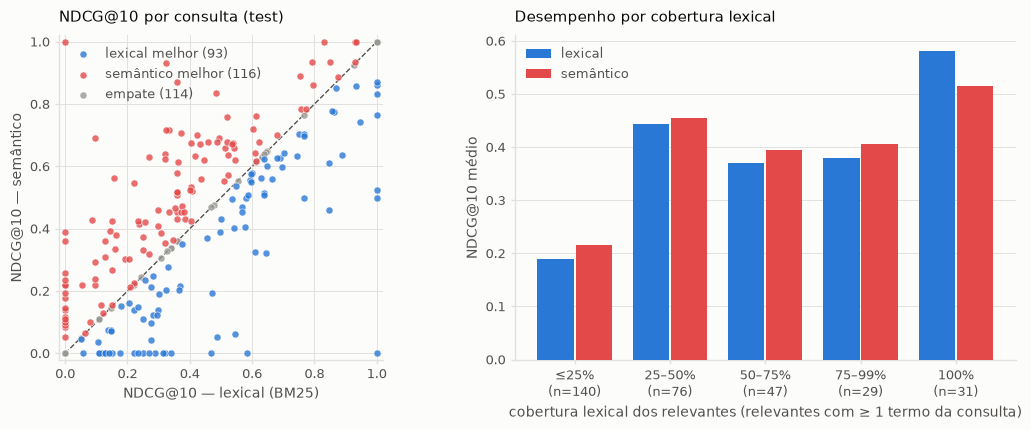

In [41]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e2e1dd"
C_LEX, C_SEM, C_TIE, C_HYB, C_RR = "#2a78d6", "#e34948", "#9a9892", "#1baf7a", "#eb6834"


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
        ax.spines[side].set_linewidth(1)
    ax.tick_params(colors=INK2, labelsize=9, length=3, width=1, color=GRID)
    ax.xaxis.label.set_color(INK2)
    ax.yaxis.label.set_color(INK2)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
fig.patch.set_facecolor(SURFACE)

ax = axes[0]
wins, losses, ties = cmp.delta > 0, cmp.delta < 0, cmp.delta == 0
ax.plot([0, 1], [0, 1], color=INK2, lw=1, ls="--", zorder=1)
ax.scatter(cmp.lexical[losses], cmp.semantic[losses], s=26, c=C_LEX, alpha=.8, lw=.5, edgecolors=SURFACE,
           zorder=3, label=f"lexical melhor ({losses.sum()})")
ax.scatter(cmp.lexical[wins], cmp.semantic[wins], s=26, c=C_SEM, alpha=.8, lw=.5, edgecolors=SURFACE,
           zorder=3, label=f"semântico melhor ({wins.sum()})")
ax.scatter(cmp.lexical[ties], cmp.semantic[ties], s=26, c=C_TIE, alpha=.8, lw=.5, edgecolors=SURFACE,
           zorder=2, label=f"empate ({ties.sum()})")
ax.set_xlabel("NDCG@10 — lexical (BM25)")
ax.set_ylabel("NDCG@10 — semântico")
ax.set_title("NDCG@10 por consulta (test)", color=INK, fontsize=11, loc="left", pad=10)
ax.set_xlim(-.02, 1.02); ax.set_ylim(-.02, 1.02); ax.set_aspect("equal")
ax.grid(True, color=GRID, lw=.7, zorder=0)
ax.legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK2)
style_axes(ax)

ax = axes[1]
bands = coverage_bands
x = np.arange(len(bands))
ax.bar(x - .2, bands.ndcg_lexical, width=.38, color=C_LEX, label="lexical", zorder=3)
ax.bar(x + .2, bands.ndcg_semantico, width=.38, color=C_SEM, label="semântico", zorder=3)
ax.set_xticks(x)
ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(bands.index, bands.consultas)])
ax.set_xlabel("cobertura lexical dos relevantes (relevantes com ≥ 1 termo da consulta)")
ax.set_ylabel("NDCG@10 médio")
ax.set_title("Desempenho por cobertura lexical", color=INK, fontsize=11, loc="left", pad=10)
ax.grid(True, axis="y", color=GRID, lw=.7, zorder=0)
ax.legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK2)
style_axes(ax)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "comparacao_lexical_semantico.png", dpi=150, facecolor=SURFACE)
plt.show()

### Função de exibição

Para cada documento do Top-5: grau no qrels (0 = não julgado), score no próprio sistema, posição no outro sistema, termos da consulta presentes no documento e título.

In [42]:
def sem_rank_of(query_id, split="test"):
    """doc_id -> posição no ranking semântico completo."""
    row = split_ids[split].index(query_id)
    return {doc_ids[i]: pos for pos, i in enumerate(rank_from_scores(sem_score_matrix[split][row]), 1)}


def lex_rank_of(query_id, split="test"):
    return {d: pos for pos, (d, _) in enumerate(lexical_run[split][query_id], 1)}


def compare_top(query_id, k=5):
    grades = qrels["test"][query_id]
    terms = query_stems(query_id)
    n_rel = sum(1 for g in grades.values() if g > 0)
    print(f"CONSULTA {query_id} — {queries[query_id]!r}")
    print(f"  termos: " + ", ".join(
        f"{t} (df={index.df(t)}, idf={bm25.idf[t]:.2f})" if t in index else f"{t} (AUSENTE)" for t in terms))
    print(f"  {n_rel} relevantes (grau 2: {sum(1 for g in grades.values() if g == 2)}); "
          f"cobertura lexical {lexical_coverage(query_id):.0%}; "
          f"NDCG@10 lexical {cmp.loc[query_id, 'lexical']:.3f}, semântico {cmp.loc[query_id, 'semantic']:.3f}")
    ranks = {"lexical": lex_rank_of(query_id), "semântico": sem_rank_of(query_id)}
    for name, run, other in (("lexical", lexical_run, "semântico"), ("semântico", semantic_run, "lexical")):
        print(f"\n  {name}")
        for pos, (doc_id, score) in enumerate(run["test"][query_id][:k], 1):
            present = [t for t in terms if t in doc_stem_sets[doc_position[doc_id]]]
            other_rank = ranks[other].get(doc_id, "—")
            title = " ".join(doc_titles[doc_position[doc_id]].split())[:62]
            print(f"    {pos}. [{grades.get(doc_id, 0)}] {doc_id:9s} score={score:7.3f}  pos. no {other}={other_rank!s:>5}"
                  f"  termos={present}  {title}")
    print()

### Três consultas com maior vantagem do sistema semântico

In [43]:
order = cmp.reset_index().sort_values(["delta", "query_id"], ascending=[False, True])
sem_best = order.query_id.head(3).tolist()
lex_best = order.sort_values(["delta", "query_id"], ascending=[True, True]).query_id.head(3).tolist()
for query_id in sem_best:
    compare_top(query_id)

CONSULTA PLAIN-1679 — 'myelopathy'
  termos: myelopathi (AUSENTE)
  1 relevantes (grau 2: 0); cobertura lexical 0%; NDCG@10 lexical 0.000, semântico 1.000

  lexical

  semântico
    1. [1] MED-5142  score=  0.750  pos. no lexical=    —  termos=[]  Irreversible subacute sclerotic combined degeneration of the s
    2. [0] MED-3316  score=  0.718  pos. no lexical=    —  termos=[]  An outbreak of neurological autoimmunity with polyradiculoneur
    3. [0] MED-3317  score=  0.706  pos. no lexical=    —  termos=[]  Auto-immune polyradiculoneuropathy and a novel IgG biomarker i
    4. [0] MED-3288  score=  0.700  pos. no lexical=    —  termos=[]  Outbreak of progressive inflammatory neuropathy following expo
    5. [0] MED-5135  score=  0.690  pos. no lexical=    —  termos=[]  West syndrome in an infant with vitamin B12 deficiency in the 

CONSULTA PLAIN-307 — 'Vitamin D: Shedding some light on the new recommendations'
  termos: vitamin (df=222, idf=2.79), shed (df=13, idf=5.60), light (df=87

### Três consultas com maior vantagem do sistema lexical

In [44]:
for query_id in lex_best:
    compare_top(query_id)

CONSULTA PLAIN-1473 — 'kohlrabi'
  termos: kohlrabi (df=1, idf=7.79)
  1 relevantes (grau 2: 0); cobertura lexical 100%; NDCG@10 lexical 1.000, semântico 0.000

  lexical
    1. [1] MED-4455  score= 12.589  pos. no semântico=   19  termos=['kohlrabi']  Glucoraphanin and 4-hydroxyglucobrassicin contents in seeds of

  semântico
    1. [0] MED-4713  score=  0.589  pos. no lexical=    —  termos=[]  A case of Kombucha tea toxicity.
    2. [0] MED-5130  score=  0.577  pos. no lexical=    —  termos=[]  Schizophrenia-like psychotic episode precipitated by cobalamin
    3. [0] MED-1655  score=  0.562  pos. no lexical=    —  termos=[]  An archaeologic dig: a rice-fruit diet reverses ECG changes in
    4. [0] MED-4963  score=  0.559  pos. no lexical=    —  termos=[]  Sushi delights and parasites: the risk of fishborne and foodbo
    5. [0] MED-4525  score=  0.555  pos. no lexical=    —  termos=[]  Studies on the antidiarrhoeal effect of dragon's blood from Cr

CONSULTA PLAIN-2620 — 'Phytates for

## Conclusão do requisito 7

**Os dois sistemas recuperam documentos diferentes.** O semântico vence em 116 consultas, o lexical em 93, e 114 empatam (78 delas com NDCG@10 = 0 nos dois). A sobreposição média do Top-10 é de só **3,14 documentos em 10** (mediana 3), contra 6,48 entre BM25 e Modelo Vetorial no Trabalho 1. Lexical e semântico não são variações de um mesmo ranking, e é essa complementaridade que a fusão do requisito 8 aproveita.

**61% dos relevantes não contêm nenhum termo da consulta.** A cobertura lexical média dos relevantes é de 39%. Para os outros 61%, o score BM25 é zero por construção. É consequência de como os qrels do NFCorpus foram feitos (relevante = citado pelo artigo do NutritionFacts que originou a consulta): muitos relevantes tratam de aspectos do tema com outro vocabulário. Na faixa de cobertura ≤ 25% estão 140 consultas (43% do test), e nela os dois sistemas vão mal (NDCG@10 de 0,189 no lexical e 0,215 no semântico).

**No agregado, as características testadas explicam pouco** (|r| ≤ 0,18), mas os sinais apontam na direção esperada:

- idf médio dos termos da consulta: r = −0,178. Termos raros favorecem o lexical.
- número de termos: r = +0,128. Consultas de 1 termo favorecem o lexical (0,377 contra 0,354), e de 3 ou mais, o semântico (+0,04).
- cobertura lexical: r = −0,092. Quando **todos** os relevantes contêm algum termo da consulta (31 consultas), o lexical vence com folga (0,581 contra 0,515), e o semântico ganha em só 13% delas. Abaixo de 100% de cobertura, o semântico tem vantagem pequena e estável (+0,01 a +0,03).

### Semântico superior

| consulta | NDCG@10 lexical → semântico | fenômeno |
|---|---|---|
| PLAIN-1679 *myelopathy* | 0,000 → 1,000 | termo técnico ausente da coleção; paráfrase |
| PLAIN-307 *Vitamin D: Shedding some light on the new recommendations* | 0,324 → 0,933 | expressão idiomática (ambiguidade) e "D" removido como stopword |
| PLAIN-1537 *low-carb diets* | 0,095 → 0,691 | variação de vocabulário (*carb* × *carbohydrate*) |

**PLAIN-1679.** `myelopathi` não existe no índice (a coleção tem `myelitis`, `myeloma` e `myelin`, mas não *myelopathy*), e o BM25 devolve uma lista **vazia**. O único relevante (MED-5142) descreve uma *subacute sclerotic combined degeneration of the spinal cord*. Mielopatia é, literalmente, doença da medula espinhal. O bi-encoder liga a consulta ao documento sem nenhuma palavra em comum e o coloca em 1º. É a paráfrase de termo técnico que o Trabalho 1 apontou como limite dos modelos lexicais.

**PLAIN-307.** O título usa a expressão idiomática *shedding some light*, e o BM25 a lê literalmente. `shed` tem idf 5,60, o maior da consulta: o 1º e o 3º colocados casam `shed` e `light`, e quatro dos cinco primeiros contêm `light`. O 1º (MED-3099, sobre o receptor aril-hidrocarboneto) e o 3º (MED-3373, sobre envolvimento social e vizinhança) não têm relação com vitamina D e estão nas posições 2.691 e 2.834 do semântico. Há também um efeito do pré-processamento: **`d` está na lista de stopwords do NLTK** (por causa de contrações como *I'd*), então "Vitamin D" vira só `vitamin` (df = 222) e perde a especificidade. O semântico trata a consulta pelo sentido e traz em 1º e 2º os dois relevantes de grau 2, sobre recomendações de vitamina D (posições 21 e 6 no lexical).

**PLAIN-1537.** A coleção escreve *low-carbohydrate*, não *low-carb*. `carb` tem df = 1, e o único documento que o contém (MED-4880) não é relevante, mas recebe score 25,8, mais que o triplo do 2º colocado. O resto do ranking lexical é decidido por `low` e `diet`, termos genéricos que trazem dietas *low-calorie*, *low-protein* e *low-fat*. O semântico aproxima *carb* de *carbohydrate* e põe 4 relevantes no Top-5 (*Low-carbohydrate diets and all-cause mortality*, *Very-low-carbohydrate ketogenic diet*…), três deles fora do Top-10 lexical (posições 18, 38 e 24).

### Lexical superior

| consulta | NDCG@10 lexical → semântico | fenômeno |
|---|---|---|
| PLAIN-1473 *kohlrabi* | 1,000 → 0,000 | termo raro com casamento exato |
| PLAIN-2620 *Phytates for the Treatment of Cancer* | 0,583 → 0,000 | termo técnico específico × generalização temática |
| PLAIN-2081 *shelf life* | 1,000 → 0,500 | expressão técnica composta |

**PLAIN-1473.** `kohlrabi` (couve-rábano) tem df = 1, e o único documento que o contém é o relevante: o BM25 acerta em 1º com um único termo. O bi-encoder não tem representação útil para a palavra. O tokenizador a quebra em `ko ##hl ##ra ##bi`, e o Top-5 semântico parece guiado por esses fragmentos: o 1º colocado é *Kombucha* (`ko ##mb ##uch ##a`), seguido de documentos sem relação. O relevante fica em 19º. A maior similaridade dessa consulta é 0,589, a mais baixa entre as seis analisadas (as outras vão de 0,712 a 0,831).

**PLAIN-2620.** `phytat` (df = 12, idf 5,67) ancora o ranking lexical em documentos sobre fitato, e 8 dos 10 primeiros são relevantes. O semântico generaliza para "compostos alimentares e câncer" (quimioprevenção, fitoquímicos, flavonoides, frutas vermelhas): tema vizinho, mas sem nenhum relevante no Top-10 (há 10 entre os 50 primeiros). O composto específico, que define a necessidade de informação, se dilui no embedding da consulta, ofuscado por *treatment of cancer*.

**PLAIN-2081.** `shelf` (df = 7) funciona como etiqueta da expressão técnica *shelf life*, e o BM25 põe o único relevante (MED-4303, *shelf-life evaluation*) em 1º. O semântico reconhece o tema (armazenamento, oxidação, processamento de alimentos) e preenche o topo com documentos sobre estocagem de probióticos, de geleia de mirtilo e de hambúrguer, próximos no sentido mas não relevantes. O relevante cai para 3º.

### Padrão

O **lexical** vence quando a consulta contém um termo **raro e específico** que aparece literalmente nos relevantes (`kohlrabi` com df = 1, `shelf` com 7, `phytat` com 12). O idf alto transforma o casamento exato num sinal decisivo, enquanto o embedding dilui esse termo numa vizinhança temática. O **semântico** vence quando consulta e relevantes **dizem a mesma coisa com palavras diferentes**: termo técnico ausente (*myelopathy*), variação de forma (*carb*/*carbohydrate*) ou expressão idiomática (*shedding light*). É a contrapartida do que o Trabalho 1 encontrou: o descasamento de vocabulário que zerava o BM25 lá é justamente o que o bi-encoder resolve aqui, ao custo de perder precisão em termos raros.

Ressalva: três das seis consultas têm um único relevante, o que leva o Δ aos extremos (±1). Há 23 consultas assim no test, e elas pesam muito nas diferenças por consulta.

# Requisito 8 - Busca híbrida (RRF)

## Decisões de projeto

**Reciprocal Rank Fusion** sobre os 100 primeiros documentos de cada sistema:

$$\mathrm{RRF}(d) = \sum_{s \in \{\text{lexical},\ \text{semântico}\}} \frac{1}{k + \mathrm{rank}_s(d)}$$

com $\mathrm{rank}_s(d)$ começando em 1. Um documento ausente do Top-100 de um sistema não recebe contribuição dele. Como a fusão usa só posições, os scores BM25 e cosseno, que estão em escalas diferentes, nunca são comparados.

**Desempate.** Dois documentos podem ter exatamente o mesmo RRF (por exemplo, um na posição 3 só do lexical e outro na posição 3 só do semântico). Nesse caso vence a melhor posição individual e, persistindo o empate, o `doc_id`.

**Escolha de k no dev**: $k \in \{10, 30, 60, 100\}$ (o enunciado exige ao menos 10, 60 e 100), maior NDCG@10 médio. Um $k$ pequeno dá peso muito maior às primeiras posições de cada lista; um $k$ grande achata as contribuições e favorece documentos que aparecem nas **duas** listas.

In [45]:
RRF_DEPTH = 100
RRF_K_VALUES = [10, 30, 60, 100]


def rrf_fuse(rankings, k, depth=RRF_DEPTH):
    """[(doc_id, score RRF)] a partir de listas [(doc_id, score)], usando só as posições."""
    scores, best = defaultdict(float), {}
    for ranking in rankings:
        for pos, (doc_id, _) in enumerate(ranking[:depth], 1):
            scores[doc_id] += 1.0 / (k + pos)
            best[doc_id] = min(best.get(doc_id, pos), pos)
    return sorted(scores.items(), key=lambda item: (-item[1], best[item[0]], item[0]))


rrf_rows = []
for k in RRF_K_VALUES:
    fused = {q: rrf_fuse([lexical_run["dev"][q], semantic_run["dev"][q]], k) for q in split_ids["dev"]}
    rrf_rows.append({"k": k, "NDCG@10 (dev)": mean_ndcg(ids_only(fused), "dev")})

rrf_dev = pd.DataFrame(rrf_rows).set_index("k")
RRF_K = int(rrf_dev["NDCG@10 (dev)"].idxmax())
print(f"k escolhido: {RRF_K}")
print(f"referência no dev: lexical {mean_ndcg(ids_only(lexical_run['dev']), 'dev'):.4f}   "
      f"semântico {mean_ndcg(ids_only(semantic_run['dev']), 'dev'):.4f}")
rrf_dev.round(4)

k escolhido: 60
referência no dev: lexical 0.2977   semântico 0.3281


,NDCG@10 (dev)
k,
10,0.3393
30,0.3391
60,0.3401
100,0.3393


### Exemplo do cálculo

Primeiro colocado do híbrido para a consulta PLAIN-2, decomposto nas duas contribuições.

In [46]:
q_ex = "PLAIN-2"
fused_ex = rrf_fuse([lexical_run["test"][q_ex], semantic_run["test"][q_ex]], RRF_K)
for doc_id, score in fused_ex[:3]:
    r_lex = lex_rank_of(q_ex).get(doc_id)
    r_sem = sem_rank_of(q_ex).get(doc_id)
    parts = [f"1/({RRF_K}+{r}) = {1 / (RRF_K + r):.5f}" if r and r <= RRF_DEPTH else "0 (fora do Top-100)"
             for r in (r_lex, r_sem)]
    print(f"{doc_id:9s} lexical pos {r_lex}, semântico pos {r_sem}:  {parts[0]} + {parts[1]} = {score:.5f}")

MED-10    lexical pos 1, semântico pos 2:  1/(60+1) = 0.01639 + 1/(60+2) = 0.01613 = 0.03252
MED-14    lexical pos 2, semântico pos 1:  1/(60+2) = 0.01613 + 1/(60+1) = 0.01639 = 0.03252
MED-2429  lexical pos 3, semântico pos 3:  1/(60+3) = 0.01587 + 1/(60+3) = 0.01587 = 0.03175


### Avaliação no test

In [47]:
hybrid_run, fusion_times = {}, []
for split in ("dev", "test"):
    hybrid_run[split] = {}
    for q in split_ids[split]:
        start = time.perf_counter()
        hybrid_run[split][q] = rrf_fuse([lexical_run[split][q], semantic_run[split][q]], RRF_K)
        if split == "test":
            fusion_times.append(time.perf_counter() - start)

per_query_metrics["hybrid"] = evaluate(ids_only(hybrid_run["test"]), "test")
diffs = check_with_ir_measures(hybrid_run["test"], per_query_metrics["hybrid"])
print("conferência ir_measures (híbrido): " + "  ".join(f"{k}={v:.1e}" for k, v in diffs.items()))
summary(["lexical", "semantic", "hybrid"]).round(4)

conferência ir_measures (híbrido): P10=0.0e+00  R10=0.0e+00  AP10=0.0e+00  NDCG10=2.2e-16


,P@10,R@10,MAP@10,NDCG@10
lexical,0.2402,0.1548,0.1231,0.3300
semantic,0.2567,0.1620,0.1230,0.3433
hybrid,0.2653,0.1708,0.1395,0.3618


### De onde vêm os documentos do Top-10 híbrido

In [48]:
origin = Counter()
for q in split_ids["test"]:
    lex100 = {d for d, _ in lexical_run["test"][q][:RRF_DEPTH]}
    sem100 = {d for d, _ in semantic_run["test"][q][:RRF_DEPTH]}
    for d, _ in hybrid_run["test"][q][:10]:
        origin["nas duas listas" if d in lex100 and d in sem100 else "só lexical" if d in lex100 else "só semântico"] += 1
total = sum(origin.values())
for key in ("nas duas listas", "só lexical", "só semântico"):
    print(f"  {key:16s} {origin[key]:5d}  ({origin[key] / total:.1%})")
short_lex = [q for q in split_ids["test"] if len(lexical_run["test"][q]) < RRF_DEPTH]
print(f"\nconsultas cujo ranking lexical tem menos de {RRF_DEPTH} documentos (nenhum outro contém os termos): "
      f"{len(short_lex)}; menor: {min(len(lexical_run['test'][q]) for q in split_ids['test'])}")

h = per_query_metrics["hybrid"].set_index("query_id").NDCG10
best_single = np.maximum(cmp.lexical, cmp.semantic)
worst_single = np.minimum(cmp.lexical, cmp.semantic)
eps = 1e-12
position = np.select(
    [h > best_single + eps, h >= best_single - eps, h > worst_single + eps],
    ["melhor que os dois", "igual ao melhor", "entre os dois"],
    default="igual ou pior que o pior",
)
print()
for label, n in pd.Series(position, index=h.index).value_counts().items():
    print(f"  híbrido {label:25s} {n:4d} consultas")
print(f"  (das que ficam 'igual ao melhor', {((h == 0) & (best_single == 0)).sum()} têm NDCG@10 = 0 nos três sistemas)")

  nas duas listas   2524  (78.1%)
  só lexical          96  (3.0%)
  só semântico       610  (18.9%)

consultas cujo ranking lexical tem menos de 100 documentos (nenhum outro contém os termos): 127; menor: 0

  híbrido igual ao melhor            138 consultas
  híbrido entre os dois               86 consultas
  híbrido melhor que os dois          60 consultas
  híbrido igual ou pior que o pior    39 consultas
  (das que ficam 'igual ao melhor', 77 têm NDCG@10 = 0 nos três sistemas)


## Conclusão do requisito 8

| k | 10 | 30 | 60 | 100 |
|---|---|---|---|---|
| NDCG@10 (dev) | 0,3393 | 0,3391 | **0,3401** | 0,3393 |

| sistema (test) | P@10 | R@10 | MAP@10 | NDCG@10 |
|---|---|---|---|---|
| lexical | 0,2402 | 0,1548 | 0,1231 | 0,3300 |
| semântico | 0,2567 | 0,1620 | 0,1230 | 0,3433 |
| **híbrido (RRF, k = 60)** | **0,2653** | **0,1708** | **0,1395** | **0,3618** |

**k = 60**, o valor proposto no artigo original do RRF (Cormack et al., 2009), venceu no dev, mas a curva é plana (0,3391 a 0,3401). Com só dois sistemas e listas de 100 documentos, o valor de k quase não muda o resultado.

**O híbrido supera os dois sistemas nas quatro métricas.** No NDCG@10 o ganho é de +9,6% sobre o lexical e +5,4% sobre o semântico. No MAP@10 é de +13,3% sobre ambos, que estavam empatados. O ganho já aparecia no dev (0,3401 contra 0,2977 e 0,3281), então não é efeito da escolha de k.

**Por que a fusão funciona: complementaridade.** Como os Top-10 dos dois sistemas compartilham só 3,14 documentos em média (requisito 7), cada sistema traz relevantes que o outro não tem. O RRF dá duas contribuições a quem aparece nas duas listas, e 78,1% dos documentos do Top-10 híbrido estão nos dois Top-100. A concordância entre sistemas independentes funciona como evidência adicional de relevância. Dos restantes, 18,9% vêm só do semântico e 3,0% só do lexical. A assimetria tem uma causa estrutural: 127 consultas têm ranking lexical com menos de 100 documentos (nenhum outro documento contém os termos), enquanto o semântico sempre devolve 100.

**A fusão é segura por consulta.** O híbrido é melhor que os dois sistemas em 60 consultas, iguala o melhor em 138 (77 delas com NDCG@10 = 0 nos três), fica entre os dois em 86 e só fica igual ou abaixo do pior em 39 (12%). Sem saber de antemão qual sistema vai acertar, combinar os dois quase nunca é a pior escolha.

**Exemplo do cálculo (PLAIN-2).** MED-10 (1º no lexical, 2º no semântico) e MED-14 (2º e 1º) têm exatamente o mesmo RRF, $\frac{1}{61} + \frac{1}{62} = 0{,}03252$. Os dois também empatam na melhor posição individual (1), e o desempate final é pelo `doc_id`. Como a fusão usa só posições, os scores do BM25 (24,6) e do cosseno (0,85) nunca são comparados.

# Requisito 9 - Reranking

## Decisões de projeto

**Cross-encoder.** A consulta e o documento entram **juntos** no transformer (`[CLS] consulta [SEP] documento [SEP]`), e a atenção cruza os tokens dos dois textos. O modelo produz um score de relevância para o par. É mais preciso que o bi-encoder, que comprime cada texto em um vetor isolado, mas exige uma passada da rede por par, e por isso só é aplicado aos 50 primeiros do híbrido.

**Candidatos, escolhidos no dev:** `cross-encoder/ms-marco-MiniLM-L6-v2` (6 camadas) e `cross-encoder/ms-marco-MiniLM-L12-v2` (12 camadas). Ambos foram treinados no MS MARCO (consultas reais do Bing), cabem em CPU e são os modelos de referência da documentação do Sentence Transformers. O L12 é ~2× mais caro, e o dev diz se a precisão extra compensa.

**Ranking completo preservado.** As 50 primeiras posições do híbrido são reordenadas pelo score do cross-encoder (empate: posição no híbrido). Da posição 51 em diante a ordem do híbrido é mantida. No arquivo de resultados, a coluna `stage` indica de onde vem o score de cada linha (`rerank` = cross-encoder, `hybrid` = RRF).

**Comprimento máximo de 512 tokens** para o par consulta + documento, com truncamento do documento quando o par excede esse limite.

**Cache.** Os scores de cada par são gravados em `data/rerank/` junto com a lista de candidatos e o tempo gasto em cada consulta. Uma nova execução só recalcula as consultas cujos candidatos mudaram.

In [49]:
RERANK_DEPTH = 50
CE_CANDIDATES = ["cross-encoder/ms-marco-MiniLM-L6-v2", "cross-encoder/ms-marco-MiniLM-L12-v2"]
CE_MAX_LENGTH = 512
CE_DIR = DATA_DIR / "rerank"
CE_DIR.mkdir(parents=True, exist_ok=True)


def cross_encoder_scores(name, ce, split, run):
    """query_id -> {'docs', 'scores', 'seconds'} para os RERANK_DEPTH primeiros de `run`, com cache em disco."""
    path = CE_DIR / f"{name.replace('/', '__')}__{split}.json"
    cache = json.loads(path.read_text()) if path.exists() else {}
    dirty = 0
    for q in split_ids[split]:
        cands = [d for d, _ in run[q][:RERANK_DEPTH]]
        if q in cache and cache[q]["docs"] == cands:
            continue
        start = time.perf_counter()
        scores = ce.predict([(queries[q], doc_texts[doc_position[d]]) for d in cands],
                            batch_size=16, show_progress_bar=False)
        cache[q] = {"docs": cands, "scores": [float(s) for s in scores], "seconds": time.perf_counter() - start}
        dirty += 1
        if dirty % 20 == 0:
            path.write_text(json.dumps(cache))
    if dirty:
        path.write_text(json.dumps(cache))
    return cache


def rerank(hybrid_ranking, entry):
    """Top-RERANK_DEPTH reordenado pelo cross-encoder + restante na ordem do híbrido."""
    hyb_pos = {d: i for i, (d, _) in enumerate(hybrid_ranking)}
    head = sorted(zip(entry["docs"], entry["scores"]), key=lambda x: (-x[1], hyb_pos[x[0]]))
    return head + hybrid_ranking[RERANK_DEPTH:]


def load_cross_encoder(name):
    return CrossEncoder(name, device="cpu", max_length=CE_MAX_LENGTH)

### Escolha do modelo no dev

In [50]:
ce_rows = []
for name in CE_CANDIDATES:
    ce = load_cross_encoder(name)
    cache = cross_encoder_scores(name, ce, "dev", hybrid_run["dev"])
    reranked = {q: rerank(hybrid_run["dev"][q], cache[q]) for q in split_ids["dev"]}
    ce_rows.append({
        "modelo": name.split("/")[1],
        "NDCG@10 (dev)": mean_ndcg(ids_only(reranked), "dev"),
        "s/consulta (50 pares)": np.mean([cache[q]["seconds"] for q in split_ids["dev"]]),
    })
    del ce

ce_selection = pd.DataFrame(ce_rows).set_index("modelo").sort_values("NDCG@10 (dev)", ascending=False)
CE_MODEL = next(n for n in CE_CANDIDATES if n.split("/")[1] == ce_selection.index[0])
print(f"modelo escolhido: {CE_MODEL}")
print(f"(híbrido sem reranking no dev: {mean_ndcg(ids_only(hybrid_run['dev']), 'dev'):.4f})")
ce_selection.round(4)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

modelo escolhido: cross-encoder/ms-marco-MiniLM-L6-v2
(híbrido sem reranking no dev: 0.3401)


,NDCG@10 (dev),s/consulta (50 pares)
modelo,,
ms-marco-MiniLM-L6-v2,0.3341,3.9379
ms-marco-MiniLM-L12-v2,0.3222,8.6100


### Reranking do test

In [51]:
ce = load_cross_encoder(CE_MODEL)
ce_cache_test = cross_encoder_scores(CE_MODEL, ce, "test", hybrid_run["test"])
reranked_run = {"test": {q: rerank(hybrid_run["test"][q], ce_cache_test[q]) for q in split_ids["test"]}}
ce_cache_dev = cross_encoder_scores(CE_MODEL, ce, "dev", hybrid_run["dev"])
reranked_run["dev"] = {q: rerank(hybrid_run["dev"][q], ce_cache_dev[q]) for q in split_ids["dev"]}

per_query_metrics["reranking"] = evaluate(ids_only(reranked_run["test"]), "test")
diffs = check_with_ir_measures(reranked_run["test"], per_query_metrics["reranking"])
print("conferência ir_measures (reranking): " + "  ".join(f"{k}={v:.1e}" for k, v in diffs.items()))

all_systems = summary(["lexical", "semantic", "hybrid", "reranking"])
all_systems.round(4)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

conferência ir_measures (reranking): P10=0.0e+00  R10=0.0e+00  AP10=0.0e+00  NDCG10=2.2e-16


,P@10,R@10,MAP@10,NDCG@10
lexical,0.2402,0.1548,0.1231,0.3300
semantic,0.2567,0.1620,0.1230,0.3433
hybrid,0.2653,0.1708,0.1395,0.3618
reranking,0.2505,0.1688,0.1391,0.3564


### Comprimento de entrada, truncamento e tempos

In [52]:
pair_lens = []
for q in split_ids["test"]:
    for d in ce_cache_test[q]["docs"]:
        pair_lens.append(len(ce.tokenizer(queries[q], doc_texts[doc_position[d]], truncation=False)["input_ids"]))
pair_lens = np.array(pair_lens)
all_scores = np.array([s for q in split_ids["test"] for s in ce_cache_test[q]["scores"]])

ce_info = {
    "modelo": CE_MODEL,
    "revisão (commit no HF Hub)": model_revision(CE_MODEL),
    "comprimento máximo (tokens, consulta + documento)": ce.max_length,
    "tokens por par (média, mediana, máx)": f"{pair_lens.mean():.0f}, {np.median(pair_lens):.0f}, {pair_lens.max()}",
    "pares truncados (test)": f"{(pair_lens > ce.max_length).sum()} de {len(pair_lens)} ({(pair_lens > ce.max_length).mean():.1%})",
    "faixa dos scores": f"[{all_scores.min():.3f}, {all_scores.max():.3f}]",
}
pd.Series(ce_info).to_frame("valor")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (587 > 512). Running this sequence through the model will result in indexing errors


/tmp/ipykernel_44831/1361076323.py:11: DeprecationWarning: The `max_length` property was renamed and is now deprecated. Please use `max_seq_length` instead.
  "comprimento máximo (tokens, consulta + documento)": ce.max_length,
/tmp/ipykernel_44831/1361076323.py:13: DeprecationWarning: The `max_length` property was renamed and is now deprecated. Please use `max_seq_length` instead.
  "pares truncados (test)": f"{(pair_lens > ce.max_length).sum()} de {len(pair_lens)} ({(pair_lens > ce.max_length).mean():.1%})",


,valor
modelo,cross-encoder/ms-marco-MiniLM-L6-v2
revisão (commit no HF Hub),233902d25c440f23af6f7d6e94d2946bac0bee0a
"comprimento máximo (tokens, consulta + documento)",512
"tokens por par (média, mediana, máx)","380, 374, 2389"
pares truncados (test),1965 de 16150 (12.2%)
faixa dos scores,"[-11.379, 8.728]"


In [53]:
stage_times = pd.DataFrame({
    "etapa": ["lexical (BM25)", "semântica (codificação + busca)", "fusão (RRF)", "reranking (50 pares)"],
    "ms/consulta (média)": [
        1000 * np.mean([t for t in query_times]),
        1000 * np.mean(sem_times["test"]),
        1000 * np.mean(fusion_times),
        1000 * np.mean([ce_cache_test[q]["seconds"] for q in split_ids["test"]]),
    ],
}).set_index("etapa")
stage_times.loc["total do pipeline"] = stage_times["ms/consulta (média)"].sum()
stage_times.round(2)

,ms/consulta (média)
etapa,
lexical (BM25),0.26
semântica (codificação + busca),122.07
fusão (RRF),0.07
reranking (50 pares),4112.99
total do pipeline,4235.39


O tempo lexical é o do requisito 2 (BM25 com $k_1 = 1{,}2$, $b = 0{,}75$; os parâmetros não alteram o custo). O tempo do reranking foi registrado durante o cálculo dos scores e fica guardado no cache.

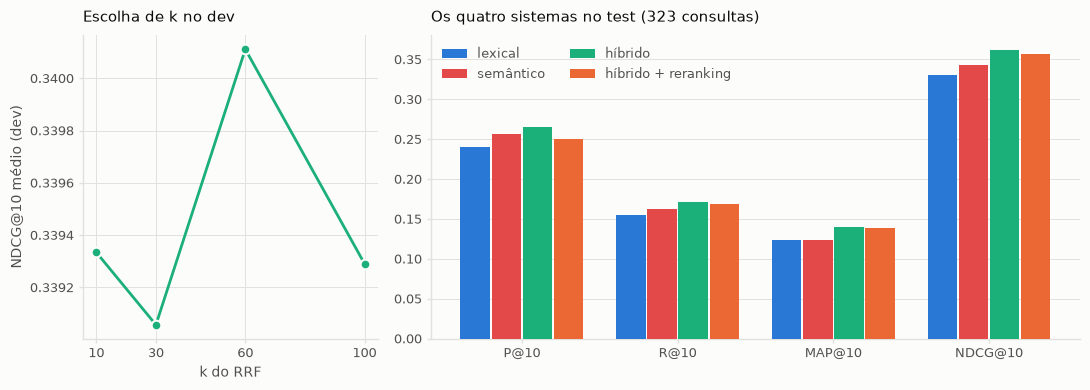

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2.2]})
fig.patch.set_facecolor(SURFACE)

ax = axes[0]
ax.plot(rrf_dev.index, rrf_dev["NDCG@10 (dev)"], color=C_HYB, lw=2, marker="o", ms=7, mec=SURFACE, mew=1.5, zorder=3)
ax.set_xticks(RRF_K_VALUES)
ax.set_xlabel("k do RRF")
ax.set_ylabel("NDCG@10 médio (dev)")
ax.set_title("Escolha de k no dev", color=INK, fontsize=11, loc="left", pad=10)
ax.grid(True, color=GRID, lw=.7, zorder=0)
style_axes(ax)

ax = axes[1]
labels = ["P@10", "R@10", "MAP@10", "NDCG@10"]
colors = {"lexical": C_LEX, "semantic": C_SEM, "hybrid": C_HYB, "reranking": C_RR}
names = {"lexical": "lexical", "semantic": "semântico", "hybrid": "híbrido", "reranking": "híbrido + reranking"}
x = np.arange(len(labels))
for i, system in enumerate(all_systems.index):
    vals = all_systems.loc[system, labels].values
    ax.bar(x + (i - 1.5) * .2, vals, width=.19, color=colors[system], label=names[system], zorder=3)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_title("Os quatro sistemas no test (323 consultas)", color=INK, fontsize=11, loc="left", pad=10)
ax.grid(True, axis="y", color=GRID, lw=.7, zorder=0)
ax.legend(frameon=False, fontsize=9, loc="upper left", labelcolor=INK2, ncol=2)
style_axes(ax)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "sistemas_test.png", dpi=150, facecolor=SURFACE)
plt.show()

## Conclusão do requisito 9

**Escolha no dev:**

| reranker | NDCG@10 (dev) | tempo por consulta (50 pares) |
|---|---|---|
| *híbrido, sem reranking* | *0,3401* | — |
| **ms-marco-MiniLM-L6-v2** | **0,3341** | 3,94 s |
| ms-marco-MiniLM-L12-v2 | 0,3222 | 8,61 s |

**Os quatro sistemas no test:**

| sistema | P@10 | R@10 | MAP@10 | NDCG@10 |
|---|---|---|---|---|
| lexical (BM25) | 0,2402 | 0,1548 | 0,1231 | 0,3300 |
| semântico (bge-small) | 0,2567 | 0,1620 | 0,1230 | 0,3433 |
| **híbrido (RRF)** | **0,2653** | **0,1708** | **0,1395** | **0,3618** |
| híbrido + reranking | 0,2505 | 0,1688 | 0,1391 | 0,3564 |

**Modelo: `cross-encoder/ms-marco-MiniLM-L6-v2`** (commit `233902d`), o melhor dos dois candidatos no dev, com entrada máxima de 512 tokens para o par consulta + documento. Os pares têm em média 380 tokens (mediana 374, máximo 2.389), e 1.965 dos 16.150 pares do test (12,2%) foram truncados.

**O reranking não melhorou o híbrido: piorou um pouco.** No dev, o NDCG@10 cai de 0,3401 para 0,3341 (−1,8%) com o L6 e para 0,3222 (−5,3%) com o L12, que é maior. No test, o L6 leva o NDCG@10 de 0,3618 para 0,3564 (−1,5%). A perda se concentra no P@10 (−5,6%), enquanto o MAP@10 quase não muda (0,1395 → 0,1391). Seguimos o protocolo: a escolha entre rerankers é feita no dev e mantida no test, e o reranking permanece no pipeline, porque é exigido e é ele que seleciona o contexto do RAG. O resultado continua acima do lexical e do semântico em R@10, MAP@10 e NDCG@10, mas fica abaixo do semântico em P@10. As razões são investigadas no requisito 10.

**O reranking domina o custo.** O cross-encoder faz uma passada do transformer **por par**, 50 por consulta, e leva 4.113 ms por consulta, contra 122 ms do semântico, 0,26 ms do BM25 e 0,07 ms da fusão. São 97% do tempo do pipeline, e o L12 custaria o dobro. Em CPU, é o reranking que limita a profundidade do pipeline: reordenar 100 documentos em vez de 50 dobraria esse tempo.

# Requisito 10 - Análise do reranking

## Decisões de projeto

**Seleção programática** pela diferença $\Delta = \mathrm{NDCG@10}_{\text{reranking}} - \mathrm{NDCG@10}_{\text{híbrido}}$:

- os **dois maiores ganhos**;
- **pouca ou nenhuma alteração**: entre as consultas com $|\Delta| < 0{,}005$ e NDCG@10 híbrido > 0, a de maior número de relevantes no Top-10 híbrido. É um caso em que o híbrido já acertava, e o teste é se o cross-encoder preserva o acerto;
- a **maior perda**.

Para cada caso mostramos os documentos que entraram no Top-10 ou saíram dele, com o grau no qrels, a posição antes e depois, o score do cross-encoder e as posições nos sistemas lexical e semântico.

In [55]:
rr_cmp = pd.DataFrame({
    "hybrid": per_query_metrics["hybrid"].set_index("query_id").NDCG10,
    "reranking": per_query_metrics["reranking"].set_index("query_id").NDCG10,
})
rr_cmp["delta"] = rr_cmp.reranking - rr_cmp.hybrid
rr_cmp["rel_top10_hybrid"] = [sum(1 for d, _ in hybrid_run["test"][q][:10] if qrels["test"][q].get(d, 0) > 0) for q in rr_cmp.index]
rr_cmp["moved_top10"] = [
    10 - len({d for d, _ in hybrid_run["test"][q][:10]} & {d for d, _ in reranked_run["test"][q][:10]}) for q in rr_cmp.index
]

print(f"reranking melhor: {(rr_cmp.delta > 0).sum()}   pior: {(rr_cmp.delta < 0).sum()}   igual: {(rr_cmp.delta == 0).sum()}")
print(f"ΔNDCG@10 médio {rr_cmp.delta.mean():+.4f};  documentos trocados no Top-10: média {rr_cmp.moved_top10.mean():.2f}")

ranked = rr_cmp.reset_index().sort_values(["delta", "query_id"], ascending=[False, True])
rr_gain = ranked.query_id.head(2).tolist()
stable = rr_cmp[(rr_cmp.delta.abs() < 0.005) & (rr_cmp.hybrid > 0)]
rr_stable = stable.reset_index().sort_values(["rel_top10_hybrid", "query_id"], ascending=[False, True]).query_id.iloc[0]
rr_loss = ranked.sort_values(["delta", "query_id"], ascending=[True, True]).query_id.iloc[0]
print(f"maiores ganhos: {rr_gain}   sem alteração: {rr_stable}   maior perda: {rr_loss}")

reranking melhor: 97   pior: 91   igual: 135
ΔNDCG@10 médio -0.0055;  documentos trocados no Top-10: média 4.47
maiores ganhos: ['PLAIN-2281', 'PLAIN-1320']   sem alteração: PLAIN-1398   maior perda: PLAIN-1679


### Como o cross-encoder move os documentos, por grau e por origem

Para todos os pares (consulta, documento) do Top-50 híbrido do test: deslocamento médio (posição no híbrido − posição após o reranking; positivo = subiu), por grau no qrels e, para os relevantes, pela lista de origem na fusão.

In [56]:
moves = []
for q in split_ids["test"]:
    rr_pos = {d: i for i, (d, _) in enumerate(reranked_run["test"][q][:RERANK_DEPTH], 1)}
    lex100 = {d for d, _ in lexical_run["test"][q][:RRF_DEPTH]}
    sem100 = {d for d, _ in semantic_run["test"][q][:RRF_DEPTH]}
    for i, (d, _) in enumerate(hybrid_run["test"][q][:RERANK_DEPTH], 1):
        moves.append({"grau": qrels["test"][q].get(d, 0), "híbrido": i, "rerank": rr_pos[d],
                      "origem": "nas duas listas" if d in lex100 and d in sem100 else "só lexical" if d in lex100 else "só semântico"})
moves = pd.DataFrame(moves)
moves["subiu"] = moves["híbrido"] - moves["rerank"]
display(moves.groupby("grau").agg(pares=("subiu", "size"), deslocamento_medio=("subiu", "mean")).round(2))
display(moves[moves.grau > 0].groupby("origem").agg(relevantes=("subiu", "size"), deslocamento_medio=("subiu", "mean")).round(2))
for name, run in (("híbrido", hybrid_run), ("reranking", reranked_run)):
    c = Counter(qrels["test"][q].get(d, 0) for q in split_ids["test"] for d, _ in run["test"][q][:10])
    print(f"Top-10 do {name:9s}: grau 2 = {c[2]}, grau 1 = {c[1]}, não relevantes = {c[0]}")

,pares,deslocamento_medio
grau,,
0,14169,0.12
1,1659,-1.15
2,322,0.56


,relevantes,deslocamento_medio
origem,,
nas duas listas,1532,-1.98
só lexical,121,10.44
só semântico,328,0.16


Top-10 do híbrido  : grau 2 = 195, grau 1 = 662, não relevantes = 2373
Top-10 do reranking: grau 2 = 198, grau 1 = 611, não relevantes = 2421


In [57]:
def rerank_case(query_id, k=10):
    grades = qrels["test"][query_id]
    hyb = [d for d, _ in hybrid_run["test"][query_id]]
    rr = [d for d, _ in reranked_run["test"][query_id]]
    ce_score = dict(zip(ce_cache_test[query_id]["docs"], ce_cache_test[query_id]["scores"]))
    lex_r, sem_r = lex_rank_of(query_id), sem_rank_of(query_id)
    print(f"CONSULTA {query_id} — {queries[query_id]!r}")
    print(f"  NDCG@10 híbrido {rr_cmp.loc[query_id, 'hybrid']:.3f} -> reranking {rr_cmp.loc[query_id, 'reranking']:.3f};  "
          f"{sum(1 for g in grades.values() if g > 0)} relevantes")
    shown = list(dict.fromkeys(rr[:k] + [d for d in hyb[:k] if d not in rr[:k]]))
    print(f"  {'doc':9s} grau  híbrido -> rerank   CE score   lex   sem   título")
    for d in shown:
        mark = "" if d in rr[:k] else "   (saiu do Top-10)"
        title = " ".join(doc_titles[doc_position[d]].split())[:55]
        print(f"  {d:9s}  {grades.get(d, 0)}    {hyb.index(d) + 1:5d} -> {rr.index(d) + 1:5d}   {ce_score.get(d, float('nan')):8.3f}"
              f"  {lex_r.get(d, '—')!s:>4}  {sem_r.get(d, '—')!s:>4}   {title}{mark}")
    print()

### Os dois maiores ganhos

In [58]:
for q in rr_gain:
    rerank_case(q)

CONSULTA PLAIN-2281 — 'turnips'
  NDCG@10 híbrido 0.000 -> reranking 0.431;  1 relevantes
  doc       grau  híbrido -> rerank   CE score   lex   sem   título
  MED-2066   0        2 ->     1     -0.985     2    33   Glucosinolates in Brassica vegetables: the influence of
  MED-948    0        1 ->     2     -1.504     1     4   Microbiological examination of vegetable seed sprouts i
  MED-2200   0        3 ->     3     -3.055     3    85   Diet and gallbladder cancer: a case-control study.
  MED-2098   1       45 ->     4     -7.887     —    44   Steam cooking significantly improves in vitro bile acid
  MED-3143   0       32 ->     5     -8.612     —    30   Gastrointestinal symptoms in 3181 volunteers ingesting 
  MED-4288   0       47 ->     6     -8.975     —    46   Out-of-hand nut consumption is associated with improved
  MED-2180   0       25 ->     7     -8.978     —    23   Christmas 2012: Research: Nutritional content of superm
  MED-711    0       46 ->     8     -9.114     —

### Pouca ou nenhuma alteração

In [59]:
rerank_case(rr_stable)

CONSULTA PLAIN-1398 — 'IGF-1'
  NDCG@10 híbrido 1.000 -> reranking 1.000;  103 relevantes
  doc       grau  híbrido -> rerank   CE score   lex   sem   título
  MED-1722   1        3 ->     1      6.550     6     1   Insulin-like growth factor-1 and childhood cancer risk
  MED-4897   1        5 ->     2      6.322     4    12   Milk consumption: aggravating factor of acne and promot
  MED-4216   1       12 ->     3      5.265     5    19   Relationship of dietary protein and soy isoflavones to 
  MED-1715   1        2 ->     4      4.674     1     6   Long-term effects of calorie or protein restriction on 
  MED-4211   1       16 ->     5      4.283    18    14   Dietary soy and fats in relation to serum insulin-like 
  MED-4225   1       19 ->     6      4.205    13    24   Why do centenarians escape or postpone cancer? The role
  MED-4212   1        8 ->     7      4.166     3    17   Insulin-like growth factor-1 and binding protein-3 in a
  MED-4223   1       14 ->     8      4.132  

### Maior perda

In [60]:
rerank_case(rr_loss)

CONSULTA PLAIN-1679 — 'myelopathy'
  NDCG@10 híbrido 1.000 -> reranking 0.000;  1 relevantes
  doc       grau  híbrido -> rerank   CE score   lex   sem   título
  MED-1105   0       41 ->     1      0.443     —    41   A CASE OF MULTIPLE MYELOMA PRESENTING AS A BULLOUS DERM
  MED-1115   0       20 ->     2     -3.216     —    20   Disparities in the prevalence, pathogenesis and progres
  MED-1109   0       39 ->     3     -3.824     —    39   Risk factors for multiple myeloma: a hospital-based cas
  MED-4312   0       29 ->     4     -5.481     —    29   Post-epidemic eosinophilia myalgia syndrome associated 
  MED-3317   0        3 ->     5     -6.407     —     3   Auto-immune polyradiculoneuropathy and a novel IgG biom
  MED-3288   0        4 ->     6     -6.502     —     4   Outbreak of progressive inflammatory neuropathy followi
  MED-3316   0        2 ->     7     -6.688     —     2   An outbreak of neurological autoimmunity with polyradic
  MED-1577   0       31 ->     8     -6.8

## Conclusão do requisito 10

**Muita reorganização, efeito líquido quase nulo.** O cross-encoder troca em média 4,47 dos 10 documentos do Top-10, mas o NDCG@10 melhora em 97 consultas, piora em 91 e empata em 135, com Δ médio de −0,0055. Os ganhos e as perdas se compensam.

**O que o cross-encoder favorece** (Top-50 híbrido de todas as consultas de test):

| grau | pares | deslocamento médio |
|---|---|---|
| 2 (citação direta) | 322 | **+0,56** |
| 1 (citação indireta) | 1.659 | **−1,15** |
| 0 (não relevante ou não julgado) | 14.169 | +0,12 |

| relevantes, por origem na fusão | n | deslocamento médio |
|---|---|---|
| só no Top-100 lexical | 121 | **+10,44** |
| só no Top-100 semântico | 328 | +0,16 |
| nas duas listas | 1.532 | −1,98 |

- **Ele não é inútil.** Sobe os relevantes de grau 2 e, principalmente, resgata os que só o BM25 tinha encontrado (+10,4 posições). O RRF os subestimava, porque recebiam a contribuição de um único sistema. Lendo consulta e documento juntos, o cross-encoder valoriza a correspondência textual explícita, o que é coerente com seu treino no MS MARCO (trechos da web que respondem a consultas do Bing).
- **Mas ele rebaixa os relevantes de grau 1**, que são a maioria (1.659 contra 322 de grau 2 no Top-50), e os documentos que estavam nas duas listas, justamente os que o RRF tinha promovido por consenso. No Top-10, os de grau 2 passam de 195 para 198, os de grau 1 caem de 662 para 611, e os não relevantes sobem de 2.373 para 2.421. É isso que derruba o P@10 em 5,6%. O NDCG@10 cai menos porque o grau 2 vale o dobro e aumenta.
- **Hipótese: descasamento entre o critério do modelo e o dos qrels.** No MS MARCO, relevante é o trecho que **responde** à pergunta. No NFCorpus, relevante é o estudo **citado** por um artigo sobre o tema, e o grau 1 (citação indireta) marca justamente documentos tematicamente relacionados que não necessariamente respondem à consulta. O L12, mais especializado no MS MARCO, perde mais no dev (0,3222 contra 0,3341), o que é coerente com essa hipótese, mas não a prova.

### Os quatro casos

**PLAIN-2281 *turnips* (0,000 → 0,431).** O único relevante (MED-2098) sobe do 45º para o 4º lugar. Ele não menciona *turnip*: trata do cozimento a vapor de couve, kale, folhas de mostarda, brócolis e repolho, crucíferas como o nabo, e por isso nem aparece no ranking lexical (o semântico o tinha em 44º). O Top-10 híbrido vinha dominado por documentos genéricos sobre vegetais trazidos pelo semântico (*Serving styles of raw snack vegetables*, *Attractive names sustain increased vegetable intake in schools*, 1º e 2º no semântico), que o cross-encoder manda para 41º e 49º. Em 1º ele põe *Glucosinolates in Brassica vegetables*, sobre a família do nabo. Porém **todos os scores são negativos** (o maior é −0,99): o modelo não considera nenhum candidato uma boa resposta, e o ganho vem de uma reordenação entre candidatos fracos que, desta vez, favoreceu o relevante.

**PLAIN-1320 *Harvard Physicians' Study II* (0,196 → 0,562).** A consulta nomeia um ensaio clínico, o *Physicians' Health Study II*. No híbrido, o Top-10 era tomado por documentos sobre médicos (*Physician smoking status…*, *Physicians' health habits are associated with lifestyle counseling…*): lexical e semântico trataram `physician` como o tema da consulta. O cross-encoder reconhece a entidade e sobe os artigos do próprio estudo: *Multivitamins in the Prevention of Cancer in Men: The Physicians' Health Study II* (7º → 1º), *…of Cardiovascular Disease in Men: The Physicians' Health Study II* (8º → 3º) e *Who uses multivitamins? A cross-sectional study in the Physicians' Health Study* (26º → 6º). O 2º colocado após o reranking, *Vitamins E and C in the Prevention of Cardiovascular Disease in Men: The Physicians' Health Study II*, também é um artigo do estudo, mas **não está nos qrels**: o NDCG@10 de 0,562 subestima o acerto, um exemplo concreto de qrels incompletos.

**PLAIN-1398 *IGF-1* (1,000 → 1,000).** São 103 relevantes, todos de grau 1, e o Top-10 híbrido já era 100% relevante. O cross-encoder o reorganiza bastante (o antigo 1º, MED-4228, cai para 11º, e quatro documentos saem do Top-10), mas os que entram também são relevantes de grau 1. Com todos os relevantes no mesmo grau, o NDCG@10 é indiferente à ordem entre eles: a métrica satura. Aqui o cross-encoder dá scores altos e positivos aos dez (3,6 a 6,6), porque a entidade da consulta aparece literalmente nos títulos (*Insulin-like growth factor-1…*).

**PLAIN-1679 *myelopathy* (1,000 → 0,000).** O caso que o bi-encoder tinha resolvido no requisito 7 é desfeito. O relevante MED-5142 (degeneração da medula espinhal) cai do 1º para o 42º lugar, com score −10,2, entre os mais baixos dos 50. Em 1º o cross-encoder põe *A case of multiple myeloma presenting as a bullous dermatosis* (41º no híbrido) e em 3º *Risk factors for multiple myeloma*. Mieloma compartilha com mielopatia o radical *myel-* (medula), mas é um câncer da medula **óssea**. O cross-encoder trocou a paráfrase correta por semelhança de superfície, o que é coerente com o ganho que ele dá aos relevantes encontrados só pelo lexical.

**Síntese.** O cross-encoder acerta quando a consulta tem uma entidade explícita que o texto do documento confirma (*Physicians' Health Study II*, *IGF-1*). Erra quando a relevância depende de conhecimento de domínio que ele não tem (mielopatia ≠ mieloma) ou de uma noção de relevância temática que não é a do seu treino. Um reranker mais preciso **em geral** não é automaticamente melhor **nesta coleção**. Por isso ele foi avaliado no dev, e não presumido.

# Requisito 11 - Retrieval-Augmented Generation (RAG)

## Decisões de projeto

**Pipeline:** consulta → recuperação híbrida (BM25 + bi-encoder, RRF) → reranking (cross-encoder sobre o Top-50) → **seleção de contexto: os 5 primeiros após o reranking** → LLM → resposta. Cada item do `corpus.jsonl` é uma unidade de contexto (sem chunking), o que mantém a correspondência direta com os qrels. Cada documento entra no prompt com seu `doc_id` entre colchetes, seguido de título e texto completos.

**LLM: `qwen2.5:3b` (Qwen2.5-3B-Instruct, quantização Q4_K_M) executado localmente pelo Ollama**, sem custo. A máquina não tem GPU e tem 7,4 GB de RAM: um modelo de 3 bilhões de parâmetros quantizado em 4 bits (~1,9 GB) é o maior que cabe com folga e gera ~19 tokens/s em CPU. A família Qwen é uma das sugeridas no enunciado.

**Parâmetros (idênticos nas duas condições):** temperatura 0 (decodificação gulosa), seed 42, no máximo 512 tokens de saída e janela de contexto de 8.192 tokens. A janela é conferida em cada chamada: o número de tokens do prompt (`prompt_eval_count`) precisa ficar abaixo dela, senão o Ollama descartaria o início do prompt silenciosamente.

**Idioma: inglês nas duas condições.** É o idioma da coleção e das consultas. Responder em português obrigaria um modelo pequeno a traduzir as evidências enquanto responde, o que acrescentaria uma fonte de erro alheia à recuperação e atrapalharia a avaliação de fidelidade.

**Prompts.** O prompt de sistema é o mesmo nas duas condições. Na condição **B**, o prompt instrui o modelo a responder **só** com base nos documentos, a citar o `doc_id` de cada afirmação e a dizer explicitamente quando não houver evidência suficiente, como pede o enunciado. Na condição **A**, o modelo recebe **só a pergunta**, com as mesmas restrições de idioma e tamanho, para que as respostas sejam comparáveis.

**Cache das respostas.** As respostas ficam em `results/rag_answers.json`, junto com o prompt exato. A avaliação humana se refere a essas respostas específicas, então reexecutar o notebook não as gera de novo, a menos que o prompt ou o modelo mudem.

In [61]:
import platform
import psutil
import requests

OLLAMA_URL = "http://127.0.0.1:11434"
LLM_MODEL = "qwen2.5:3b"
LLM_OPTIONS = {"temperature": 0, "seed": 42, "num_predict": 512, "num_ctx": 8192}
RAG_TOP_K = 5
RAG_CACHE = RESULTS_DIR / "rag_answers.json"

SYSTEM_PROMPT = "You are a careful assistant that answers health and nutrition questions."

PROMPT_A = """Question: {question}

Answer the question in English, in at most 200 words."""

PROMPT_B = """Answer the question using only the scientific abstracts below.

Rules:
- Base every statement on the abstracts and cite the supporting abstract id in square brackets right after it, for example [MED-1234].
- If the abstracts do not contain enough evidence to answer the question, or part of it, say so explicitly.
- Answer in English, in at most 200 words.

Abstracts:
{context}

Question: {question}"""


def ollama_info():
    version = requests.get(f"{OLLAMA_URL}/api/version", timeout=10).json()["version"]
    tags = {m["name"]: m for m in requests.get(f"{OLLAMA_URL}/api/tags", timeout=10).json()["models"]}
    model = tags[LLM_MODEL] if LLM_MODEL in tags else tags[f"{LLM_MODEL}:latest"]
    return version, model


def cpu_name():
    try:
        for line in open("/proc/cpuinfo"):
            if line.startswith("model name"):
                return line.split(":", 1)[1].strip()
    except OSError:
        pass
    return platform.processor()


ollama_version, llm_meta = ollama_info()
llm_info = {
    "modelo": f"{LLM_MODEL} ({llm_meta['details']['family']}, {llm_meta['details']['parameter_size']}, "
              f"{llm_meta['details']['quantization_level']})",
    "digest": llm_meta["digest"],
    "execução": f"local, Ollama {ollama_version}, só CPU",
    "temperatura": LLM_OPTIONS["temperature"],
    "seed": LLM_OPTIONS["seed"],
    "máximo de tokens de saída": LLM_OPTIONS["num_predict"],
    "janela de contexto (tokens)": LLM_OPTIONS["num_ctx"],
    "demais parâmetros": "padrões do Ollama para o modelo (temperatura 0 = decodificação gulosa)",
    "idioma das respostas": "inglês",
    "custo": "nenhum (execução local)",
    "hardware": f"{cpu_name()}, {psutil.cpu_count(logical=False)} núcleos / {psutil.cpu_count()} threads, "
                f"{psutil.virtual_memory().total / 2**30:.1f} GB de RAM, sem GPU",
}
pd.Series(llm_info).to_frame("valor")

,valor
modelo,"qwen2.5:3b (qwen2, 3.1B, Q4_K_M)"
digest,357c53fb659c5076de1d65ccb0b397446227b71a42be9d...
execução,"local, Ollama 0.40.16, só CPU"
temperatura,0
seed,42
máximo de tokens de saída,512
janela de contexto (tokens),8192
demais parâmetros,padrões do Ollama para o modelo (temperatura 0...
idioma das respostas,inglês
custo,nenhum (execução local)


In [62]:
def format_context(context_ids):
    return "\n\n".join(f"[{d}] {doc_texts[doc_position[d]]}" for d in context_ids)


def build_prompt(question, condition, context_ids=None):
    if condition == "A":
        return PROMPT_A.format(question=question)
    return PROMPT_B.format(question=question, context=format_context(context_ids))


def ollama_chat(user_prompt):
    payload = {
        "model": LLM_MODEL, "stream": False, "options": LLM_OPTIONS,
        "messages": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": user_prompt}],
    }
    out = requests.post(f"{OLLAMA_URL}/api/chat", json=payload, timeout=3600).json()
    return {
        "answer": out["message"]["content"].strip(),
        "prompt_tokens": out["prompt_eval_count"],
        "output_tokens": out["eval_count"],
        "seconds": out["total_duration"] / 1e9,
    }


def retrieve_context(query_id, k=RAG_TOP_K):
    """Top-k após o reranking (hybrid -> cross-encoder) para uma consulta de test."""
    return [d for d, _ in reranked_run["test"][query_id][:k]]


def rag_pipeline(question, k=RAG_TOP_K):
    """Pipeline completo para uma pergunta nova: lexical + semântico -> RRF -> cross-encoder -> Top-k -> LLM."""
    fused = rrf_fuse([lexical_search(question, top_k=RRF_DEPTH), semantic_search(question, RRF_DEPTH)], RRF_K)
    cands = [d for d, _ in fused[:RERANK_DEPTH]]
    scores = ce.predict([(question, doc_texts[doc_position[d]]) for d in cands], batch_size=16, show_progress_bar=False)
    reranked = rerank(fused, {"docs": cands, "scores": [float(s) for s in scores]})
    context_ids = [d for d, _ in reranked[:k]]
    return context_ids, ollama_chat(build_prompt(question, "B", context_ids))

# Requisito 12 - Experimento sem RAG × com RAG

## Decisões de projeto

**Consultas sorteadas com o código do enunciado**: seed 42, entre as consultas de test terminadas em "?". Conferimos que a lista bate com a do enunciado.

**Duas condições com a mesma LLM e os mesmos parâmetros**: (A) só a pergunta, sem acesso à coleção; (B) a pergunta e os Top-5 após o reranking, com seus `doc_id`.

In [63]:
test_qrels = qrels["test"]
ids = [q for q in sorted(test_qrels.keys()) if queries[q].strip().endswith("?")]
queries_rag = random.Random(42).sample(ids, 10)

EXPECTED_RAG = ["PLAIN-68", "PLAIN-2450", "PLAIN-153", "PLAIN-2850", "PLAIN-2750",
                "PLAIN-270", "PLAIN-2470", "PLAIN-2430", "PLAIN-238", "PLAIN-3342"]
assert queries_rag == EXPECTED_RAG
print(f"{len(ids)} consultas de test formuladas como pergunta; sorteio confere com o enunciado:")
for q in queries_rag:
    print(f"  {q:11s} {queries[q]}")

42 consultas de test formuladas como pergunta; sorteio confere com o enunciado:
  PLAIN-68    What is Actually in Chicken Nuggets?
  PLAIN-2450  Are Organic Foods Safer?
  PLAIN-153   How Should I Take Probiotics?
  PLAIN-2850  More Antibiotics In White Meat or Dark Meat?
  PLAIN-2750  Preventing the Common Cold with Probiotics?
  PLAIN-270   Is Caffeinated Tea Really Dehydrating?
  PLAIN-2470  Is Milk Good for Our Bones?
  PLAIN-2430  Preventing Brain Loss with B Vitamins?
  PLAIN-238   How Chemically Contaminated Are We?
  PLAIN-3342  Is Coconut Milk Good For You?


In [64]:
rag_cache = json.loads(RAG_CACHE.read_text()) if RAG_CACHE.exists() else {}

rag_rows = []
for query_id in queries_rag:
    question = queries[query_id]
    context_ids = retrieve_context(query_id)
    for condition in ("A", "B"):
        prompt = build_prompt(question, condition, context_ids)
        key = f"{query_id}|{condition}"
        cached = rag_cache.get(key)
        if not cached or cached["prompt"] != prompt or cached["model"] != llm_meta["digest"]:
            cached = {"prompt": prompt, "model": llm_meta["digest"], **ollama_chat(prompt)}
            rag_cache[key] = cached
            RAG_CACHE.write_text(json.dumps(rag_cache, indent=1, ensure_ascii=False))
        assert cached["prompt_tokens"] < LLM_OPTIONS["num_ctx"], key
        rag_rows.append({
            "query_id": query_id, "query": question, "condition": condition,
            "context_doc_ids": " ".join(context_ids) if condition == "B" else "",
            "prompt": f"[system] {SYSTEM_PROMPT}\n[user] {prompt}",
            "answer": cached["answer"],
            "prompt_tokens": cached["prompt_tokens"], "output_tokens": cached["output_tokens"],
            "seconds": round(cached["seconds"], 1),
        })

rag_df = pd.DataFrame(rag_rows)
print(f"tokens do prompt: A máx {rag_df[rag_df.condition == 'A'].prompt_tokens.max()}, "
      f"B máx {rag_df[rag_df.condition == 'B'].prompt_tokens.max()} (janela {LLM_OPTIONS['num_ctx']}) -> sem truncamento")
print(f"tempo médio por resposta: A {rag_df[rag_df.condition == 'A'].seconds.mean():.0f}s, "
      f"B {rag_df[rag_df.condition == 'B'].seconds.mean():.0f}s")
rag_df[["query_id", "condition", "context_doc_ids", "prompt_tokens", "output_tokens", "seconds"]]

tokens do prompt: A máx 52, B máx 2943 (janela 8192) -> sem truncamento
tempo médio por resposta: A 17s, B 26s


,query_id,condition,context_doc_ids,prompt_tokens,output_tokens,seconds
0,PLAIN-68,A,,49,186,13.1
1,PLAIN-68,B,MED-2991 MED-1797 MED-2492 MED-1810 MED-2741,2101,107,12.9
2,PLAIN-2450,A,,48,259,14.5
3,PLAIN-2450,B,MED-1140 MED-1178 MED-1144 MED-1179 MED-1173,1857,309,23.3
4,PLAIN-153,A,,50,369,20.2
5,PLAIN-153,B,MED-3679 MED-3692 MED-3695 MED-3693 MED-3680,2447,221,20.6
6,PLAIN-2850,A,,52,309,17.0
7,PLAIN-2850,B,MED-3891 MED-4358 MED-4983 MED-2584 MED-4482,2702,361,30.7
8,PLAIN-2750,A,,52,248,15.5
9,PLAIN-2750,B,MED-3683 MED-3695 MED-3680 MED-3690 MED-4762,2943,485,41.9


### Respostas

In [65]:
for query_id in queries_rag:
    print("=" * 100)
    print(f"{query_id} — {queries[query_id]}")
    ctx = retrieve_context(query_id)
    print("contexto (B): " + ", ".join(f"{d} [grau {qrels['test'][query_id].get(d, 0)}]" for d in ctx))
    for condition in ("A", "B"):
        answer = rag_df[(rag_df.query_id == query_id) & (rag_df.condition == condition)].answer.iloc[0]
        print(f"\n--- {condition} ---\n{answer}")
    print()

PLAIN-68 — What is Actually in Chicken Nuggets?
contexto (B): MED-2991 [grau 2], MED-1797 [grau 0], MED-2492 [grau 0], MED-1810 [grau 0], MED-2741 [grau 0]

--- A ---
Chicken nuggets are typically a processed food product made from pieces of chicken meat, usually from the breast or thigh areas. The primary ingredients include ground chicken, which is mixed with other ingredients to form the nugget shape and texture. Common additives and binders in chicken nuggets include breadcrumbs, wheat flour, and sometimes potato starch or other binders to help hold the nuggets together. These ingredients are often coated in a batter or breading, which can be made from various ingredients like wheat flour, milk, and eggs, to give the nuggets a golden-brown color and crispy texture. Seasonings such as salt, pepper, and various herbs and spices are also commonly added to enhance flavor. Some manufacturers may also include ingredients like sugar, to improve the texture and appearance, or artificial co

### Características objetivas das respostas

Medidas automáticas que não substituem a avaliação humana do requisito 13: tamanho, quantos `doc_id` distintos cada resposta cita, quantos desses estavam de fato no contexto (um id fora do contexto seria uma fonte inventada), quantos citados são relevantes nos qrels e se a resposta declara evidência insuficiente ou limitada.

In [66]:
CITE_RE = re.compile(r"MED-\d+")
INSUFFICIENT_RE = re.compile(r"not (?:directly |specifically )?(?:addressed|provide|establish|conclusive|clear)|limited|insufficient|"
                             r"no (?:direct |specific )?(?:evidence|data)|does not (?:directly |specifically )?(?:address|mention)|"
                             r"further research", re.IGNORECASE)

answer_feats = []
for row in rag_df.itertuples():
    cited = sorted(set(CITE_RE.findall(row.answer)))
    ctx = retrieve_context(row.query_id)
    answer_feats.append({
        "query_id": row.query_id, "condição": row.condition,
        "palavras": len(row.answer.split()),
        "ids citados": len(cited),
        "citados fora do contexto": sum(1 for d in cited if d not in ctx) if row.condition == "B" else len(cited),
        "citados relevantes": sum(1 for d in cited if qrels["test"][row.query_id].get(d, 0) > 0),
        "declara limitação": bool(INSUFFICIENT_RE.search(row.answer)),
    })
answer_feats = pd.DataFrame(answer_feats)
display(answer_feats.groupby("condição")[["palavras", "ids citados", "citados fora do contexto", "citados relevantes", "declara limitação"]].mean().round(2))
answer_feats.pivot(index="query_id", columns="condição", values=["palavras", "ids citados", "citados relevantes"])

,palavras,ids citados,citados fora do contexto,citados relevantes,declara limitação
condição,,,,,
A,223.7,0.0,0.0,0.0,0.0
B,205.0,2.5,0.0,1.3,0.7


palavras      ids citados    citados relevantes   
condição          A    B           A  B                  A  B
query_id                                                     
PLAIN-153       265  179           0  1                  0  1
PLAIN-238       253  243           0  4                  0  1
PLAIN-2430      252  228           0  5                  0  3
PLAIN-2450      222  223           0  4                  0  1
PLAIN-2470      180  261           0  4                  0  3
PLAIN-270       207   99           0  1                  0  1
PLAIN-2750      207  280           0  2                  0  1
PLAIN-2850      265  281           0  1                  0  0
PLAIN-3342      233  183           0  2                  0  1
PLAIN-68        153   73           0  1                  0  1

## Conclusão dos requisitos 11 e 12

**Configuração do RAG.** `qwen2.5:3b` (Qwen2.5-3B-Instruct, Q4_K_M, digest `357c53fb659c`) executado localmente pelo Ollama 0.40.16, só em CPU (Intel Core i5-1340P, 7,4 GB de RAM), sem custo. Temperatura 0, seed 42, até 512 tokens de saída, janela de 8.192 tokens, respostas em inglês nas duas condições. O contexto da condição B são os 5 primeiros documentos após o reranking, inteiros e identificados pelo `doc_id`.

**Sem truncamento do contexto.** O maior prompt da condição B tem 2.943 tokens, bem abaixo da janela de 8.192, então os cinco documentos chegaram inteiros à LLM em todas as consultas.

**Custo.** Cada resposta levou em média 17 s sem contexto e 26 s com contexto: o processamento dos ~2.000 tokens do contexto é o custo adicional do RAG. Somando recuperação e reranking (~4 s), o pipeline completo responde uma pergunta em cerca de meio minuto em CPU.

**O que muda, objetivamente, com o RAG.** As respostas da condição B citam em média 2,5 documentos distintos, e **nenhum id citado está fora do contexto**: a LLM não inventou fontes. Na condição A não há citação alguma, como esperado. As respostas da condição B são um pouco mais curtas (205 contra 224 palavras em média; o limite de 200 palavras pedido no prompt foi excedido nas duas condições) e declaram explicitamente limitação da evidência com mais frequência (7 de 10, contra nenhuma na condição A, pela heurística de expressões como *limited*, *not directly addressed* e *further research*). A qualidade das respostas (fidelidade, completude, utilidade e rastreabilidade) é avaliada por humanos no requisito 13.

**Observação para a avaliação às cegas:** as respostas acima aparecem identificadas por condição. Os avaliadores devem preencher as planilhas de `avaliacao/` antes de ler esta seção.

# Requisito 13 - Avaliação do RAG

## Decisões de projeto

**Recuperação.** Precision@5, Recall@5 e Hit@5 sobre os 5 documentos efetivamente enviados à LLM (relevante = grau > 0).

**Geração: avaliação humana estruturada e às cegas.** O notebook gera, em `avaliacao/`:

- `respostas.md`: as 20 respostas **embaralhadas** (seed fixa), identificadas só por um código (`R01`…`R20`), sem indicar a condição;
- `contextos.md`: para cada pergunta, os Top-5 documentos completos, que são a base para julgar a **fidelidade** nas duas condições;
- `avaliador_1.csv` e `avaliador_2.csv`: uma planilha por integrante, preenchida de forma **independente**, com nota 0, 1 ou 2 e justificativa para cada critério;
- `chave.csv`: a correspondência código → (consulta, condição), que só deve ser aberta depois das duas avaliações;
- `INSTRUCOES.md`: a rubrica.

Os arquivos só são criados se ainda não existirem, para não apagar notas já preenchidas. **Limite da cegueira:** respostas com citações `[MED-…]` são reconhecivelmente da condição B, e isso será discutido no relatório.

**Protocolo da condição A.** A fidelidade é julgada contra os mesmos Top-5 da condição B. A rastreabilidade é registrada como **N/A** e excluída da média (o notebook aplica isso ao ler as planilhas).

**Nota final** = média dos dois avaliadores. A concordância é medida pela porcentagem de notas idênticas e pelo kappa de Cohen com pesos quadráticos (adequado para notas ordinais 0/1/2).

### Recuperação: o que chegou à LLM

In [67]:
rag_retrieval = []
for query_id in queries_rag:
    ctx = retrieve_context(query_id)
    grades = qrels["test"][query_id]
    n_rel = sum(1 for g in grades.values() if g > 0)
    hits = sum(1 for d in ctx if grades.get(d, 0) > 0)
    rag_retrieval.append({"query_id": query_id, "P@5": hits / RAG_TOP_K, "R@5": hits / n_rel,
                          "Hit@5": int(hits > 0), "relevantes no contexto": hits, "relevantes (qrels)": n_rel,
                          "NDCG@10 (reranking)": rr_cmp.loc[query_id, "reranking"]})
rag_retrieval = pd.DataFrame(rag_retrieval).set_index("query_id")
print(rag_retrieval[["P@5", "R@5", "Hit@5"]].mean().round(4).to_string())
rag_retrieval.round(3)

P@5      0.4400
R@5      0.0742
Hit@5    0.9000


,P@5,R@5,Hit@5,relevantes no contexto,relevantes (qrels),NDCG@10 (reranking)
query_id,,,,,,
PLAIN-68,0.2,0.018,1,1,55,0.361
PLAIN-2450,0.4,0.053,1,2,38,0.297
PLAIN-153,1.0,0.106,1,5,47,0.948
PLAIN-2850,0.0,0.000,0,0,9,0.055
PLAIN-2750,0.8,0.068,1,4,59,0.670
PLAIN-270,0.4,0.038,1,2,52,0.315
PLAIN-2470,0.6,0.041,1,3,73,0.598
PLAIN-2430,0.6,0.065,1,3,46,0.520
PLAIN-238,0.2,0.019,1,1,54,0.139


### Planilhas da avaliação cega

In [68]:
EVAL_DIR = Path("avaliacao")
EVAL_DIR.mkdir(exist_ok=True)
CRITERIA = ["fidelidade", "completude", "utilidade", "rastreabilidade"]

if not (EVAL_DIR / "chave.csv").exists():
    items = [(q, c) for q in queries_rag for c in ("A", "B")]
    random.Random(2026).shuffle(items)
    key_df = pd.DataFrame([{"item": f"R{i:02d}", "query_id": q, "condition": c} for i, (q, c) in enumerate(items, 1)])
    key_df.to_csv(EVAL_DIR / "chave.csv", index=False)

    lines = ["# Respostas para avaliação (ordem embaralhada)\n",
             "Os documentos de referência de cada pergunta estão em `contextos.md`.\n"]
    sheet = []
    for row in key_df.itertuples():
        answer = rag_df[(rag_df.query_id == row.query_id) & (rag_df.condition == row.condition)].answer.iloc[0]
        lines += [f"\n## {row.item} — {row.query_id}: {queries[row.query_id]}\n", answer, "\n"]
        sheet.append({"item": row.item, "query_id": row.query_id, "pergunta": queries[row.query_id],
                      **{c: "" for c in CRITERIA}, **{f"justificativa_{c}": "" for c in CRITERIA}})
    (EVAL_DIR / "respostas.md").write_text("\n".join(lines), encoding="utf-8")
    for evaluator in (1, 2):
        pd.DataFrame(sheet).to_csv(EVAL_DIR / f"avaliador_{evaluator}.csv", index=False)

    ctx_lines = ["# Documentos de referência (Top-5 após o reranking)\n",
                 "Base para julgar a fidelidade de **todas** as respostas da pergunta.\n"]
    for q in queries_rag:
        ctx_lines.append(f"\n## {q}: {queries[q]}\n")
        for d in retrieve_context(q):
            ctx_lines.append(f"**[{d}]** {doc_texts[doc_position[d]]}\n")
    (EVAL_DIR / "contextos.md").write_text("\n".join(ctx_lines), encoding="utf-8")

    (EVAL_DIR / "INSTRUCOES.md").write_text("""# Instruções da avaliação

1. Cada integrante preenche **só a sua** planilha (`avaliador_1.csv` ou `avaliador_2.csv`), sem ver a do outro.
2. Leia a resposta em `respostas.md` e os documentos da pergunta em `contextos.md`.
3. Dê nota **0, 1 ou 2** em cada critério e escreva uma justificativa curta para cada nota.
4. **Não abra `chave.csv`** antes de terminar.
5. Avalie a rastreabilidade de todas as respostas. Para respostas sem nenhuma fonte, a nota é 0 (o notebook converte para N/A na condição sem RAG).

| Critério | 0 | 1 | 2 |
|---|---|---|---|
| Fidelidade | Afirmações importantes não são sustentadas pelos documentos ou os contradizem. | Resposta parcialmente sustentada. | As afirmações principais são sustentadas pelos documentos. |
| Completude | Não responde aos aspectos principais. | Responde parcialmente. | Cobre adequadamente os aspectos que podem ser respondidos. |
| Utilidade | Não responde à necessidade da consulta. | Resposta parcialmente útil. | Responde diretamente à necessidade apresentada. |
| Rastreabilidade | Não é possível identificar as fontes. | Apenas parte das afirmações pode ser associada às fontes. | As afirmações principais podem ser associadas aos doc_ids apresentados. |

A fidelidade de **todas** as respostas é julgada contra os documentos de `contextos.md`, inclusive as respostas que não citam nenhum documento.
""", encoding="utf-8")
    print("planilhas criadas em", EVAL_DIR)
else:
    print("planilhas já existem em", EVAL_DIR, "(não foram sobrescritas)")
print(sorted(p.name for p in EVAL_DIR.iterdir()))

planilhas já existem em avaliacao (não foram sobrescritas)
['INSTRUCOES.md', 'avaliador_1.csv', 'avaliador_2.csv', 'chave.csv', 'contextos.md', 'respostas.md']


### Leitura das notas, concordância e médias

In [69]:
from sklearn.metrics import cohen_kappa_score

key_df = pd.read_csv(EVAL_DIR / "chave.csv")


def load_sheet(path):
    """Lê a planilha de um avaliador (detecta o separador, caso tenha sido salva com ';')."""
    df = pd.read_csv(path, dtype=str, sep=None, engine="python").fillna("")
    for c in CRITERIA:
        df[c] = pd.to_numeric(df[c].str.strip().str.replace(",", "."), errors="coerce")
    return df.merge(key_df, on=["item", "query_id"])


sheets = {p.stem: load_sheet(p) for p in sorted(EVAL_DIR.glob("avaliador_*.csv"))}
complete = {name: s for name, s in sheets.items() if s[CRITERIA].notna().all().all()}
print(f"planilhas completas: {list(complete) or 'nenhuma'}")

if complete:
    if len(complete) == 2:
        a, b = complete.values()
        agreement = []
        for c in CRITERIA:
            mask = pd.Series(True, index=a.index) if c != "rastreabilidade" else a.condition == "B"
            x, y = a.loc[mask, c].astype(int), b.loc[mask, c].astype(int)
            kappa = cohen_kappa_score(x, y, weights="quadratic", labels=[0, 1, 2])
            agreement.append({"critério": c, "n": int(mask.sum()), "notas idênticas": (x == y).mean(), "kappa ponderado": kappa})
        display(pd.DataFrame(agreement).set_index("critério").round(3))

    grades_long = pd.concat(complete.values())
    final = grades_long.groupby(["query_id", "condition"])[CRITERIA].mean().reset_index()
    final.loc[final.condition == "A", "rastreabilidade"] = np.nan
    just = grades_long.groupby(["query_id", "condition"]).agg(
        **{f"justificativa_{c}": (f"justificativa_{c}", lambda s: " | ".join(f"av{i + 1}: {t}" for i, t in enumerate(s)))
           for c in CRITERIA}).reset_index()
    rag_scores = final.merge(just, on=["query_id", "condition"])
    means = rag_scores.groupby("condition")[CRITERIA].mean()
    means["média (fid., comp., util.)"] = rag_scores.groupby("condition")[["fidelidade", "completude", "utilidade"]].mean().mean(axis=1)
    display(means.round(3))
else:
    rag_scores = pd.DataFrame(columns=["query_id", "condition", *CRITERIA, *[f"justificativa_{c}" for c in CRITERIA]])
    print("A avaliação humana ainda não foi preenchida: as notas ficam vazias em rag_experiment.csv.")

planilhas completas: nenhuma
A avaliação humana ainda não foi preenchida: as notas ficam vazias em rag_experiment.csv.


In [70]:
rag_out = rag_df.merge(rag_scores, on=["query_id", "condition"], how="left")
rag_out["rastreabilidade"] = rag_out["rastreabilidade"].astype(object)
rag_out.loc[rag_out.condition == "A", "rastreabilidade"] = "N/A"
rag_out["observacao"] = np.where(
    rag_out.condition == "A",
    "sem contexto externo: a LLM recebeu só a pergunta; fidelidade avaliada contra os Top-5 da condição B; rastreabilidade N/A",
    "contexto: Top-5 após o reranking",
)
rag_cols = ["query_id", "query", "condition", "context_doc_ids", "prompt", "answer", *CRITERIA,
            *[f"justificativa_{c}" for c in CRITERIA], "observacao", "prompt_tokens", "output_tokens", "seconds"]
rag_out[rag_cols].to_csv(RESULTS_DIR / "rag_experiment.csv", index=False)
print(RESULTS_DIR / "rag_experiment.csv")

results/rag_experiment.csv


## Conclusão do requisito 13

### Recuperação: o que chegou à LLM

| consulta | pergunta | P@5 | R@5 | Hit@5 | relevantes nos qrels |
|---|---|---|---|---|---|
| PLAIN-68 | What is Actually in Chicken Nuggets? | 0,2 | 0,018 | 1 | 55 |
| PLAIN-2450 | Are Organic Foods Safer? | 0,4 | 0,053 | 1 | 38 |
| PLAIN-153 | How Should I Take Probiotics? | 1,0 | 0,106 | 1 | 47 |
| PLAIN-2850 | More Antibiotics In White Meat or Dark Meat? | 0,0 | 0,000 | **0** | 9 |
| PLAIN-2750 | Preventing the Common Cold with Probiotics? | 0,8 | 0,068 | 1 | 59 |
| PLAIN-270 | Is Caffeinated Tea Really Dehydrating? | 0,4 | 0,038 | 1 | 52 |
| PLAIN-2470 | Is Milk Good for Our Bones? | 0,6 | 0,041 | 1 | 73 |
| PLAIN-2430 | Preventing Brain Loss with B Vitamins? | 0,6 | 0,065 | 1 | 46 |
| PLAIN-238 | How Chemically Contaminated Are We? | 0,2 | 0,019 | 1 | 54 |
| PLAIN-3342 | Is Coconut Milk Good For You? | 0,2 | 0,333 | 1 | 3 |
| **média** | | **0,44** | **0,074** | **0,9** | 43,6 |

Em **9 das 10** consultas ao menos um documento relevante chegou à LLM, e em média 2,2 dos 5 documentos do contexto são relevantes. O R@5 baixo (0,074) é consequência do número de relevantes, como o enunciado antecipa: com 43,6 relevantes por consulta em média, o R@5 máximo possível já seria de ~0,11. A exceção é a PLAIN-2850, em que **nenhum** relevante chegou ao contexto. Ela é diagnosticada no requisito 14.

### Geração: avaliação humana

**[A completar depois da avaliação humana]** Médias por condição e critério, concordância entre os avaliadores (notas idênticas e kappa ponderado) e discussão: efeito do RAG na fidelidade, na completude e na utilidade; ausência de fontes na condição A e suas consequências para a verificabilidade; limites da cegueira (as citações identificam a condição B).

# Requisito 14 - Análise de falhas ponta a ponta

## Decisões de projeto

**Rastreamento por estágio.** Para cada consulta seguimos os documentos relevantes ao longo do pipeline: quantos estão no Top-100 lexical, no Top-100 semântico, no Top-50 híbrido (o conjunto que o cross-encoder vê) e no Top-5 final (o que a LLM recebe). Quando uma resposta é ruim, isso localiza o estágio em que a evidência se perdeu: se nenhum relevante chega ao Top-50 híbrido, o problema está na recuperação; se chega ao Top-50 mas não ao Top-5, está no reranking ou na seleção de contexto; se chega ao Top-5, o problema está na geração.

**Seleção dos três casos pelas notas humanas.** A diferença B − A na média de fidelidade, completude e utilidade (os três critérios comuns às duas condições) define os casos: maior diferença (o RAG melhorou claramente), menor |diferença| (pouca diferença) e menor diferença (o RAG não ajudou ou prejudicou).

In [71]:
def stage_trace(query_id):
    grades = qrels["test"][query_id]
    rel = {d for d, g in grades.items() if g > 0}
    lex = [d for d, _ in lexical_run["test"][query_id][:RRF_DEPTH]]
    sem = [d for d, _ in semantic_run["test"][query_id][:RRF_DEPTH]]
    hyb = [d for d, _ in hybrid_run["test"][query_id][:RERANK_DEPTH]]
    top5 = retrieve_context(query_id)
    return {
        "relevantes": len(rel),
        "lexical Top-100": len(rel & set(lex)),
        "semântico Top-100": len(rel & set(sem)),
        "híbrido Top-50": len(rel & set(hyb)),
        "contexto Top-5": len(rel & set(top5)),
        "grau 2 no contexto": sum(1 for d in top5 if grades.get(d, 0) == 2),
    }


trace_df = pd.DataFrame({q: stage_trace(q) for q in queries_rag}).T
trace_df

,relevantes,lexical Top-100,semântico Top-100,híbrido Top-50,contexto Top-5,grau 2 no contexto
PLAIN-68,55,12,14,9,1,1
PLAIN-2450,38,7,7,6,2,2
PLAIN-153,47,17,22,18,5,1
PLAIN-2850,9,2,4,1,0,0
PLAIN-2750,59,16,24,17,4,2
PLAIN-270,52,13,9,4,2,0
PLAIN-2470,73,26,20,18,3,3
PLAIN-2430,46,11,18,16,3,3
PLAIN-238,54,3,2,2,1,0
PLAIN-3342,3,3,3,3,1,1


In [72]:
def context_trace(query_id):
    """Os 5 documentos do contexto e as posições que receberam em cada estágio."""
    grades = qrels["test"][query_id]
    lex_r, sem_r = lex_rank_of(query_id), sem_rank_of(query_id)
    hyb = [d for d, _ in hybrid_run["test"][query_id]]
    print(f"{query_id} — {queries[query_id]}")
    print(f"  {'doc':9s} grau   lex   sem  híbrido -> rerank  título")
    for pos, d in enumerate(retrieve_context(query_id), 1):
        title = " ".join(doc_titles[doc_position[d]].split())[:60]
        print(f"  {d:9s}  {grades.get(d, 0)}   {lex_r.get(d, '—')!s:>4}  {sem_r.get(d, '—')!s:>4}  {hyb.index(d) + 1:7d} -> {pos}"
              f"      {title}")
    print()


if complete:
    common = ["fidelidade", "completude", "utilidade"]
    per_answer = rag_scores.assign(media=rag_scores[common].mean(axis=1)).pivot(index="query_id", columns="condition", values="media")
    per_answer["B - A"] = per_answer.B - per_answer.A
    display(per_answer.round(2))
    s = per_answer.reset_index().sort_values(["B - A", "query_id"])
    cases = {
        "RAG melhorou claramente": s.query_id.iloc[-1],
        "pouca diferença": s.assign(abs_diff=s["B - A"].abs()).sort_values(["abs_diff", "query_id"]).query_id.iloc[0],
        "RAG não ajudou ou prejudicou": s.query_id.iloc[0],
    }
    for label, q in cases.items():
        print(f"### {label}: {q}")
        context_trace(q)
else:
    print("Seleção dos casos aguardando a avaliação humana. Rastreamento do contexto das dez consultas:\n")
    for q in queries_rag:
        context_trace(q)

Seleção dos casos aguardando a avaliação humana. Rastreamento do contexto das dez consultas:

PLAIN-68 — What is Actually in Chicken Nuggets?
  doc       grau   lex   sem  híbrido -> rerank  título
  MED-2991   2      1     1        1 -> 1      The autopsy of chicken nuggets reads "chicken little".
  MED-1797   0     23   308       41 -> 2      Comparative genome analysis with the human genome reveals ch
  MED-2492   0      8     4        3 -> 3      Roxarsone, Inorganic Arsenic, and Other Arsenic Species in C
  MED-1810   0      5    16        5 -> 4      Transmissibility of adenovirus-induced adiposity in a chicke
  MED-2741   0     14   441       30 -> 5      Overcrowding stress decreases macrophage activity and increa

PLAIN-2450 — Are Organic Foods Safer?
  doc       grau   lex   sem  híbrido -> rerank  título
  MED-1140   0      1     1        1 -> 1      Organic food: buying more safety or just peace of mind? A cr
  MED-1178   2      2     2        2 -> 2      Are organic foods 

### A única consulta sem relevante no contexto: PLAIN-2850

Posição de cada relevante da consulta em cada estágio do pipeline (— = fora do ranking ou do Top-50 reordenado).

In [73]:
def relevant_trace(query_id):
    grades = qrels["test"][query_id]
    lex_r, sem_r = lex_rank_of(query_id), sem_rank_of(query_id)
    hyb = [d for d, _ in hybrid_run["test"][query_id]]
    rr = [d for d, _ in reranked_run["test"][query_id]]
    ce_score = dict(zip(ce_cache_test[query_id]["docs"], ce_cache_test[query_id]["scores"]))
    print(f"{query_id} — {queries[query_id]}   termos: {preprocess(queries[query_id], **CONFIGS[PREPROC])}")
    print(f"  {'doc':9s} grau   lex   sem  híbrido  rerank  CE score  título")
    for d, g in sorted(grades.items(), key=lambda x: (-x[1], sem_r[x[0]])):
        title = " ".join(doc_titles[doc_position[d]].split())[:62]
        h = hyb.index(d) + 1 if d in hyb else "—"
        r = rr.index(d) + 1 if d in rr else "—"
        print(f"  {d:9s}  {g}   {lex_r.get(d, '—')!s:>4}  {sem_r[d]:4d}  {h!s:>7}  {r!s:>6}  {ce_score.get(d, float('nan')):8.2f}  {title}")
    print(f"  scores do cross-encoder no Top-5 enviado à LLM: {[round(ce_score[d], 2) for d in rr[:5]]}")


relevant_trace("PLAIN-2850")

PLAIN-2850 — More Antibiotics In White Meat or Dark Meat?   termos: ['antibiot', 'white', 'meat', 'dark', 'meat']
  doc       grau   lex   sem  híbrido  rerank  CE score  título
  MED-4166   2    174    33       76      76       nan  Concentrations of antibiotic residues vary between different e
  MED-3693   1      —    18       60      60       nan  Microbiological evaluation of commercial probiotic products av
  MED-4167   1     76    46       36      10     -7.26  Influence of water and food consumption on inadvertent antibio
  MED-4436   1     94    83       58      58       nan  Consumption of meat and dairy and lymphoma risk in the Europea
  MED-4168   1    147   160        —       —       nan  Influence of a five-day vegetarian diet on urinary levels of a
  MED-3690   1    254   170        —       —       nan  Probiotics as prevention and treatment for diarrhea.
  MED-4433   1      —   217        —       —       nan  Cancer mortality in poultry slaughtering/processing plant work

## Conclusão do requisito 14

### Onde a evidência se perde (todas as dez consultas)

Somando as dez consultas: dos **436** documentos relevantes, **110** estão no Top-100 lexical, **123** no Top-100 semântico (**151** em pelo menos um dos dois), **94** no Top-50 híbrido (o que o cross-encoder vê) e **22** no Top-5 enviado à LLM. O gargalo principal é a **primeira etapa**: 285 relevantes (65%) não aparecem em nenhum dos dois rankings iniciais e nunca têm chance de chegar ao contexto, o que é coerente com a cobertura lexical de 39% dos relevantes medida no requisito 7. A fusão leva 94 dos 151 ao Top-50. Daí em diante, o Top-5 é um corte de 1/10 do Top-50, então é natural que a maior parte dos relevantes do Top-50 fique de fora.

### PLAIN-2850: falha na recuperação, antes do reranking

*More Antibiotics In White Meat or Dark Meat?* é a única consulta com Hit@5 = 0, e o rastreamento localiza a falha:

- O relevante de grau 2, **MED-4166** (*Concentrations of antibiotic residues vary between different edible muscle tissues in poultry*), responde exatamente à pergunta. Mas o documento fala em *muscle tissues*, não em *white meat* ou *dark meat*, e o BM25 o coloca só em **174º**. O semântico o coloca em **33º**.
- Por ficar fora do Top-100 lexical, ele recebe do RRF a contribuição de um único sistema e cai para **76º** no híbrido, fora do Top-50. **O cross-encoder nunca chega a vê-lo.** O único relevante que entra no Top-50 (MED-4167, sobre ingestão inadvertida de antibióticos) fica em 10º depois do reranking.
- Os cinco documentos enviados à LLM tratam de resistência antimicrobiana em carnes do varejo, bacteriófagos em produtos cárneos, consumo de carne e mortalidade, e câncer colorretal. São do tema "carne", sem relação com a comparação entre carne branca e escura, e todos têm score negativo no cross-encoder (−5,0 a −6,1): o reranker não encontrou nenhum candidato convincente.

**Estágio do problema: recuperação lexical somada à fusão.** O descasamento de vocabulário (*white/dark meat* × *muscle tissues*) tirou o documento do ranking lexical, e o RRF, que recompensa a concordância entre os sistemas, rebaixou um documento que só o semântico tinha encontrado. Usando só o semântico, ele estaria em 33º, dentro do alcance do cross-encoder. Como a informação necessária **não chegou ao contexto**, o que a LLM respondeu na condição B não pode ser atribuído a uma falha de geração.

### Os três casos pelas notas

**[A completar depois da avaliação humana]** O código acima seleciona automaticamente, pela diferença B − A na média de fidelidade, completude e utilidade, a consulta em que o RAG melhorou claramente, a de pouca diferença e a em que o RAG não ajudou ou prejudicou. Para cada uma: o que mudou na resposta, se a informação necessária estava no contexto (rastreamento acima) e em que estágio está o problema, quando houver.

# Requisito 15 - Arquivos padronizados de resultados

Rankings do test com os 100 primeiros documentos de cada consulta (`query_id, doc_id, rank, score, relevance`; relevância = grau no qrels, 0 se não julgado), métricas por consulta dos quatro sistemas e os arquivos dos experimentos de correção ortográfica e RAG (já gravados nos requisitos 4/5 e 13).

**Rankings lexicais com menos de 100 documentos.** O BM25 só pontua documentos que contêm ao menos um termo da consulta. Quando menos de 100 documentos têm algum termo em comum, o ranking lexical é mais curto, e o arquivo traz só esses documentos, sem completar a lista com documentos de score zero em ordem arbitrária, o que não seria um ranking. Uma consulta cujos termos não existem na coleção (como *myelopathy*) não tem nenhuma linha em `results_lexical.csv`, mas continua nas métricas, com valor zero. Os demais sistemas sempre têm 100 linhas por consulta.

In [74]:
def save_run(run, filename, extra=None):
    rows = []
    for q in split_ids["test"]:
        for pos, (d, s) in enumerate(run[q][:100], 1):
            row = {"query_id": q, "doc_id": d, "rank": pos, "score": s, "relevance": qrels["test"][q].get(d, 0)}
            if extra:
                row.update(extra(q, pos))
            rows.append(row)
    pd.DataFrame(rows).to_csv(RESULTS_DIR / filename, index=False)


save_run(lexical_run["test"], "results_lexical.csv")
save_run(semantic_run["test"], "results_semantic.csv")
save_run(hybrid_run["test"], "results_hybrid.csv")
save_run(reranked_run["test"], "results_reranking.csv",
         extra=lambda q, pos: {"stage": "rerank" if pos <= RERANK_DEPTH else "hybrid"})

lex_lens = pd.Series({q: min(len(lexical_run["test"][q]), 100) for q in split_ids["test"]})
print(f"results_lexical.csv: {(lex_lens < 100).sum()} consultas com menos de 100 documentos, "
      f"{(lex_lens == 0).sum()} sem nenhum ({', '.join(lex_lens[lex_lens == 0].index)})")

metrics_per_query = pd.concat(
    [df.assign(model=name) for name, df in per_query_metrics.items()]
)[["query_id", "model", "P10", "R10", "AP10", "NDCG10"]]
metrics_per_query.to_csv(RESULTS_DIR / "metrics_per_query.csv", index=False)
all_systems.to_csv(RESULTS_DIR / "metrics_aggregated.csv")

# a média de AP10 por modelo é o MAP@10 reportado
check = metrics_per_query.groupby("model").AP10.mean()
assert all(abs(check[m] - all_systems.loc[m, "MAP@10"]) < 1e-12 for m in all_systems.index)

REQUIRED = {
    "results_lexical.csv": ["query_id", "doc_id", "rank", "score", "relevance"],
    "results_semantic.csv": ["query_id", "doc_id", "rank", "score", "relevance"],
    "results_hybrid.csv": ["query_id", "doc_id", "rank", "score", "relevance"],
    "results_reranking.csv": ["query_id", "doc_id", "rank", "score", "relevance"],
    "metrics_per_query.csv": ["query_id", "model", "P10", "R10", "AP10", "NDCG10"],
    "typo_experiment.csv": ["query_id", "query_original", "query_erro", "query_corrigida", "tipo_erro",
                            "NDCG10_original", "NDCG10_erro", "NDCG10_corrigida"],
    "rag_experiment.csv": ["query_id", "query", "condition", "context_doc_ids", "prompt", "answer", *CRITERIA,
                           *[f"justificativa_{c}" for c in CRITERIA]],
}
for filename, cols in REQUIRED.items():
    df = pd.read_csv(RESULTS_DIR / filename)
    missing = [c for c in cols if c not in df.columns]
    assert not missing, (filename, missing)
    print(f"  {filename:24s} {len(df):6d} linhas  colunas obrigatórias presentes")

results_lexical.csv: 127 consultas com menos de 100 documentos, 15 sem nenhum (PLAIN-1098, PLAIN-1214, PLAIN-1309, PLAIN-1611, PLAIN-1621, PLAIN-1679, PLAIN-1752, PLAIN-1827, PLAIN-2134, PLAIN-2209, PLAIN-2271, PLAIN-2396, PLAIN-2408, PLAIN-551, PLAIN-997)
  results_lexical.csv       21916 linhas  colunas obrigatórias presentes
  results_semantic.csv      32300 linhas  colunas obrigatórias presentes
  results_hybrid.csv        32300 linhas  colunas obrigatórias presentes
  results_reranking.csv     32300 linhas  colunas obrigatórias presentes
  metrics_per_query.csv      1292 linhas  colunas obrigatórias presentes
  typo_experiment.csv          10 linhas  colunas obrigatórias presentes
  rag_experiment.csv           20 linhas  colunas obrigatórias presentes
